# Detecting Moving Objects in DAS Recordings

**Computer Vision - Project 1 (2026), grade-5 version + both extra points.**
Authors: **Kuba** and **Mateusz** (pair project). Data: Jana Pawła II street, 2024-05-07.

**Abstract.** Vehicles passing a fibre-optic cable appear in a Distributed Acoustic Sensing
(DAS) time-space image as slanted lines whose slope is the velocity. We detect them with a
classical, fully vectorised image- and signal-processing pipeline (NumPy, OpenCV,
scikit-image, Matplotlib only): common-mode removal, two complementary frequency paths
(HF 60-312.5 Hz vibration energy and LF 1-8 Hz quasi-static load), RMS energy images with
log compression, a direction-separated **f-k fan filter** (5-150 km/h) and a **matched
line-filter bank**, then two detection paths - **thick lines** (Otsu threshold, oriented
morphology, sequential RANSAC) and **thin lines** (hysteresis, skeleton, probabilistic and
global Hough) - followed by grouping of candidates into one averaged line per vehicle. A
two-pass **ridge tracker** gives the velocity of every object and its **velocity over time**,
and the objects are **clustered** into thick / thin x constant / varying speed groups.

The method is evaluated quantitatively against the ground truth of the synthetic dataset and
against manual labels of the three real 2-minute segments, and every design decision is backed
by an experiment (ablation, method comparison, parameter sweeps - section 12 and Appendix A).
**Results:** synthetic data (134 vehicles) - recall thick 1.00, thin 0.88, F1 0.93, velocity
error 1.9 km/h, v(t) error 2.3 km/h; real segments against our manual labels (47 lines) - recall
thick 0.96, thin 0.71, F1 0.79; 15 / 19 / 18 objects in the three 2-minute segments, ≈9-10 s
of processing per segment.

**How this notebook is built.** All computations live in the package `src/das/` (one module per
processing stage) and in the scripts `scripts/*.py`, which write figures to `outputs/figures/` and
tables to `outputs/results/`. `scripts/make_report_figures.py --regenerate` reruns everything
and copies the figures, downscaled with `cv2.INTER_AREA`, to `report/figures/`. The notebook
displays those figures and reads the result tables, and section 11 runs the whole pipeline live
on one segment. The complete source code is listed in Appendix B. "Stage N" and "log #N"
refer to the implementation plan (`plan.md`: Stages 4-10 are the processing blocks of
section 4, Stage 11 the evaluation, Stage 13 the parameter studies) and to the experiments
log (Appendix A).

Reproduce: `uv sync`, `uv run python scripts/extract_data.py`,
`uv run python scripts/make_report_figures.py --regenerate`,
`uv run jupyter nbconvert --to html --execute report/report.ipynb`.

In [1]:
import csv
import json
import sys
from pathlib import Path

import numpy as np
from IPython.display import Code, Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "report" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG, RES = ROOT / "report" / "figures", ROOT / "outputs" / "results"

from das import config  # noqa: E402


def fig(name: str, width: int | None = None) -> None:
    # Show a report figure (PNG or JPEG, embedded in the HTML).
    path = next(FIG.glob(name + ".*"))
    display(Image(filename=str(path), width=width))


def read_csv(name: str) -> list[dict]:
    with open(RES / name, newline="", encoding="utf-8") as fh:
        return list(csv.DictReader(fh))


def read_json(name: str) -> dict:
    return json.loads((RES / name).read_text(encoding="utf-8"))


def fmt(v, nd: int = 3) -> str:
    if v is None or v == "":
        return "-"
    if isinstance(v, str):
        try:
            v = float(v) if any(c in v for c in ".e") else int(v)
        except ValueError:
            return v
    if isinstance(v, float):
        if not np.isfinite(v):
            return "-"
        return f"{v:.3g}" if (abs(v) >= 1e4 or 0 < abs(v) < 1e-3) else f"{v:.{nd}f}"
    return str(v)


def table(rows: list[dict], cols: list[str], headers: list[str] | None = None, nd: int = 3) -> None:
    # Render a list of dicts as a Markdown table.
    esc = lambda s: str(s).replace("|", "\\|")  # noqa: E731  (pipes inside cells)
    headers = headers or cols
    lines = ["| " + " | ".join(map(esc, headers)) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(esc(fmt(r.get(c, ""), nd)) for c in cols) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


print("project root:", ROOT)

project root: D:\Studia\sem5\CV_projects\Object_detection_from_DAS


## 1. Introduction and data

**DAS principle.** Laser pulses are sent into an optical fibre; the phase of the Rayleigh
back-scattered light measures the strain rate of every ≈5 m section of the cable. A vehicle on
the street loads and shakes the ground above the cable, so the matrix *time × position* shows
it as a **slanted line**: position changes linearly with time and the slope
$v = \Delta x / \Delta t$ is the velocity (sign = direction along the cable). Trams and heavy
trucks give **thick, strong** lines, cars **thin, weak** ones.

| | Real data (used for all results) | Synthetic data (development and evaluation) |
|---|---|---|
| Files | 259 files `HHMMSS.npy`, each 10 s: (6250, 52) float32 | 6 samples (ids 40-45): signal (75000, 59), ground-truth mask, metadata |
| Sampling | dt = 1.6 ms (625 Hz, Nyquist 312.5 Hz), dx = 5.1065 m, 52 channels ≈ 266 m | same dt / dx (from the metadata), 59 channels |
| Continuity | two continuous runs: 09:00:17-09:02:27 (14 files) and 09:02:52-09:43:32 (245 files) | 2 min each |
| Ground truth | none (manual labels made by us, section 12) | vehicle id per pixel + type (car / van / truck / tram), direction, lane |

A 2-minute segment = 12 consecutive files = 75000 × 52 samples. Every analysis segment is
loaded with **one extra file of padding on each side** (`io.load_segment(pad_files=1)`), which
removes edge effects of the FFT-based filters; the padding is cropped after the envelope.

**Analysed segments** (pair work: two assigned segments + one chosen by us that overlaps
neither). Our own segment was chosen after the EDA as the most active admissible 2-minute window
(25.8 % of the 1 s × channel cells above 3× the channel reference, 10 traffic episodes, lines in
both directions and crossings), complementing the assigned segments that are dominated by one
direction (ranking in `outputs/results/eda_candidates.csv`).

In [2]:
from datetime import datetime, timedelta  # noqa: E402

t0 = {s["name"]: datetime.strptime(s["start"], "%H%M%S") for s in config.SEGMENTS}
table([{**s, "start_clock": t0[s["name"]].strftime("%H:%M:%S"),
        "end": (t0[s["name"]] + timedelta(seconds=10 * s["n_files"])).strftime("%H:%M:%S")}
       for s in config.SEGMENTS],
      ["name", "owner", "kind", "start_clock", "end", "n_files"],
      ["segment", "analysed by", "kind", "start", "end", "files"])

| segment | analysed by | kind | start | end | files |
|---|---|---|---|---|---|
| seg_kuba | Kuba | assigned | 09:04:52 | 09:06:52 | 12 |
| seg_mateusz | Mateusz | assigned | 09:32:22 | 09:34:22 | 12 |
| seg_own | Kuba + Mateusz | own | 09:11:52 | 09:13:52 | 12 |

The whole recording as consecutive 2-minute panels (log RMS in 1 s × channel cells). The three
segments are marked in the timeline of section 2.

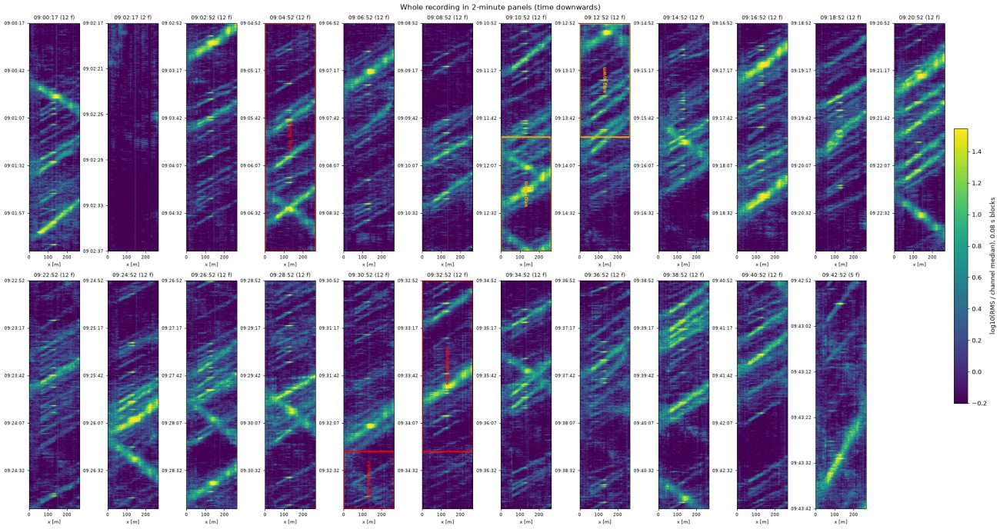

In [3]:
fig("eda_global_overview")

## 2. Exploratory data analysis

Global statistics over **all 259 files** are computed by streaming (`stats.RunningStats`,
batch-merged moments - Welford / Chan updates - and fixed-bin histograms), so the dataset never
has to fit into memory. Per-segment statistics come from `stats.describe`,
`per_channel_stats`, `per_time_stats` (1 s windows) and `activity_metrics`.

In [4]:
g = read_json("eda_global.json")["global"]
segs = {s["name"]: read_json(f"eda_{s['name']}.json") for s in config.SEGMENTS}
rows = [{"data": "all 259 files", **g}] + [{"data": n, **d["describe"], **d["activity"]} for n, d in segs.items()]
for r in rows:
    r["robust_sigma"] = r.get("robust_sigma", float("nan"))
table(rows, ["data", "mean", "std", "robust_sigma", "skewness", "kurtosis", "max_abs",
             "active_fraction", "strong_fraction", "n_events"],
      ["data", "mean", "std", "robust σ (1.4826 MAD)", "skewness", "excess kurtosis", "max |x|",
       "active fraction", "strong fraction", "traffic episodes"], nd=3)

| data | mean | std | robust σ (1.4826 MAD) | skewness | excess kurtosis | max \|x\| | active fraction | strong fraction | traffic episodes |
|---|---|---|---|---|---|---|---|---|---|
| all 259 files | 1.4e-10 | 4.85e-07 | - | 0.902 | 434.755 | 7.18e-05 | - | - | - |
| seg_kuba | -1.94e-12 | 5.02e-07 | 1.15e-07 | 1.521 | 973.904 | 7.18e-05 | 0.118 | 0.030 | 6 |
| seg_mateusz | 2.17e-10 | 4.83e-07 | 1.11e-07 | 1.102 | 323.663 | 4.47e-05 | 0.099 | 0.032 | 2 |
| seg_own | 1.46e-10 | 7e-07 | 1.86e-07 | 0.410 | 193.726 | 4.24e-05 | 0.258 | 0.050 | 10 |

**Key findings and their consequences for the method**

| Finding | Evidence | Consequence |
|---|---|---|
| Extremely heavy-tailed values | std 4.85e-7 vs robust σ ≈ 1.15e-7; excess kurtosis ≈ 435; max ≈ 150 σ | median / MAD statistics everywhere, log compression, percentile clipping; mean / std normalisation rejected (log #3) |
| Quantised values | step 2.5e-9, 1-4 % exact zeros | an epsilon in every log / division |
| Channel ≈25 (≈128 m) flagged by the bad-channel test (robust z 4.4) | smooth RMS / kurtosis bump over channels 22-28; short horizontal dashes whenever vehicles pass | a **physical hotspot** (road / track feature), not a faulty channel: kept, handled by per-channel normalisation and the f-k filter (log #1) |
| Raw signal is oscillatory and broadband | signed zoom: ± vibration under a moving envelope | trajectories are visible only in the **energy envelope** |
| Thin car lines are invisible in linear RMS, clear in log(RMS / channel median) | waterfall figure below | log compression + per-channel normalisation are essential for grade 5 (log #2) |
| Neighbour correlation alternates 0.3 / 0.9 | correlation matrix with block structure | filters spanning several channels, no single-neighbour logic |
| Traffic is bursty (per-file RMS varies 5×) | activity timeline | all thresholds relative to the robust noise level of each image |
| Most traffic moves towards decreasing x; crossings exist | waterfalls, f-k (section 3) | direction-separated processing |

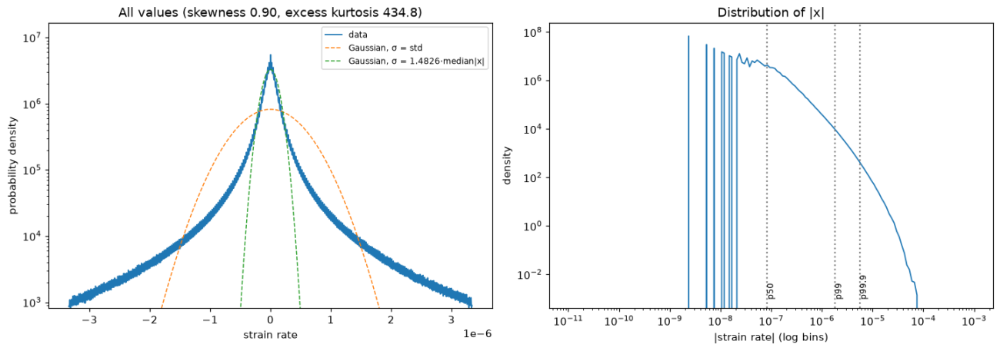

In [5]:
fig("eda_global_histograms")

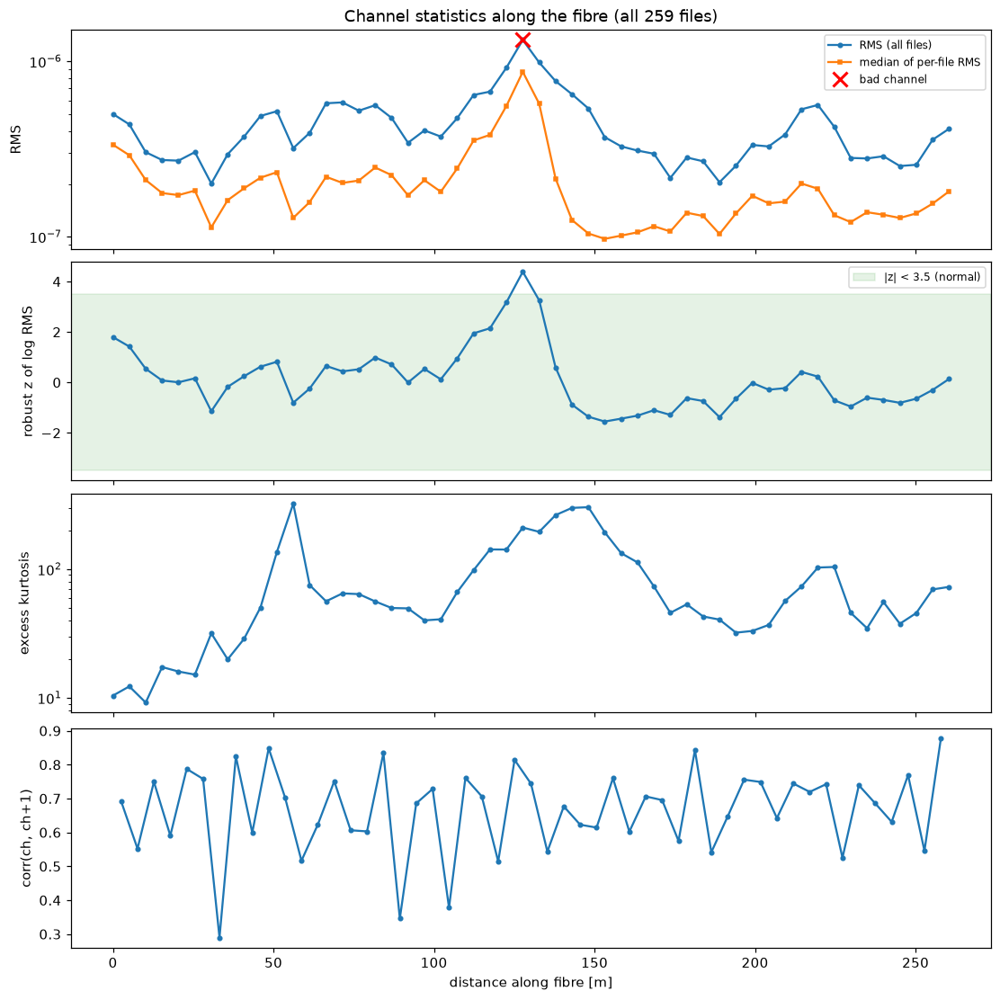

In [6]:
fig("eda_global_channel_profile")

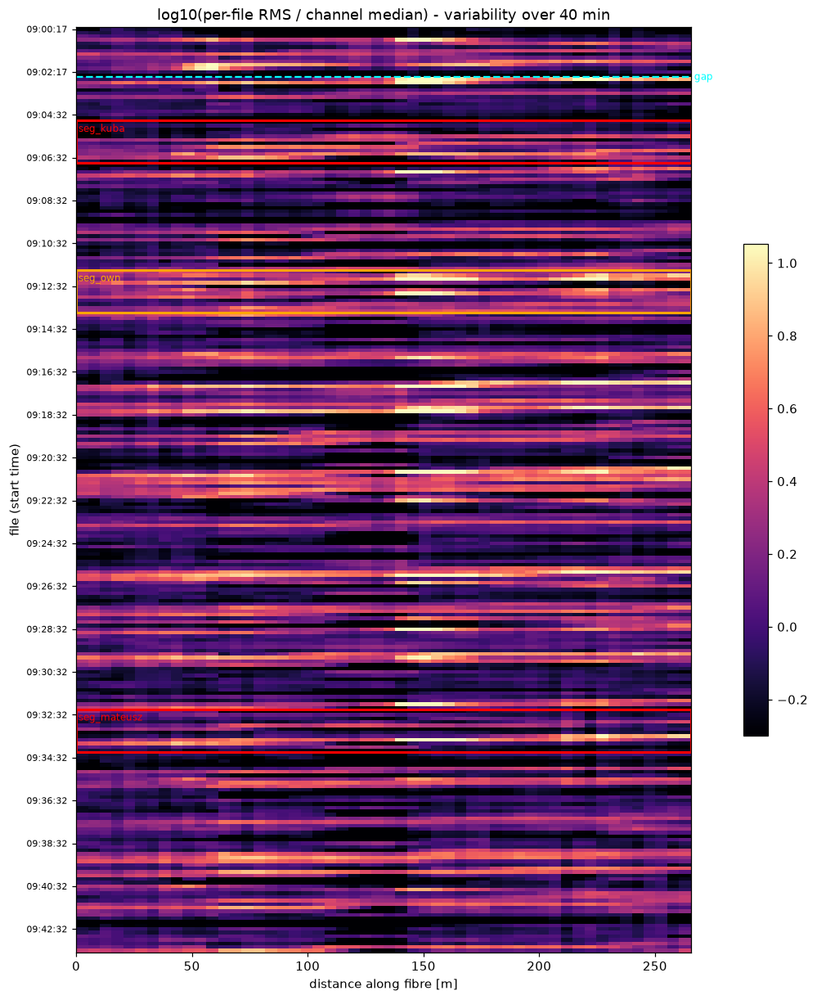

In [7]:
fig("eda_global_file_channel_rms")

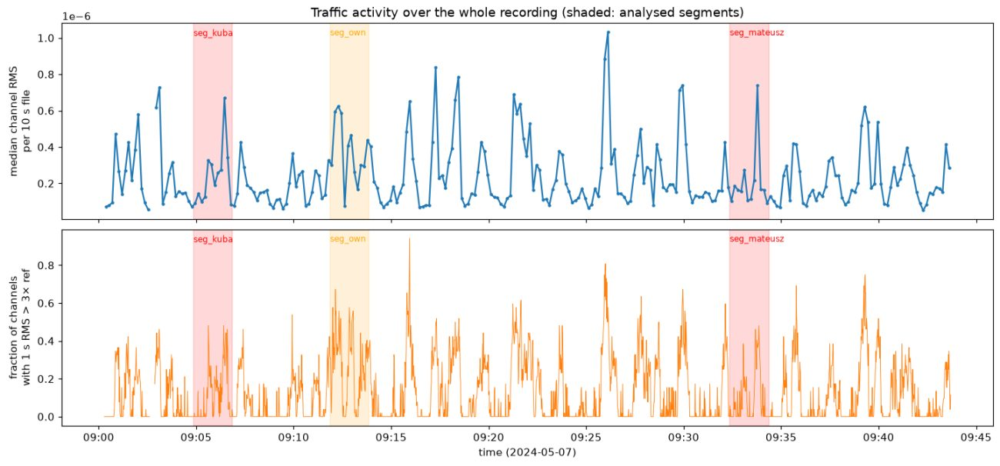

In [8]:
fig("eda_global_activity_timeline")

**Linear vs logarithmic display** (segment `seg_kuba`): only the trams are visible in the
linear RMS; after log10(RMS / channel median) the thin car lines appear.

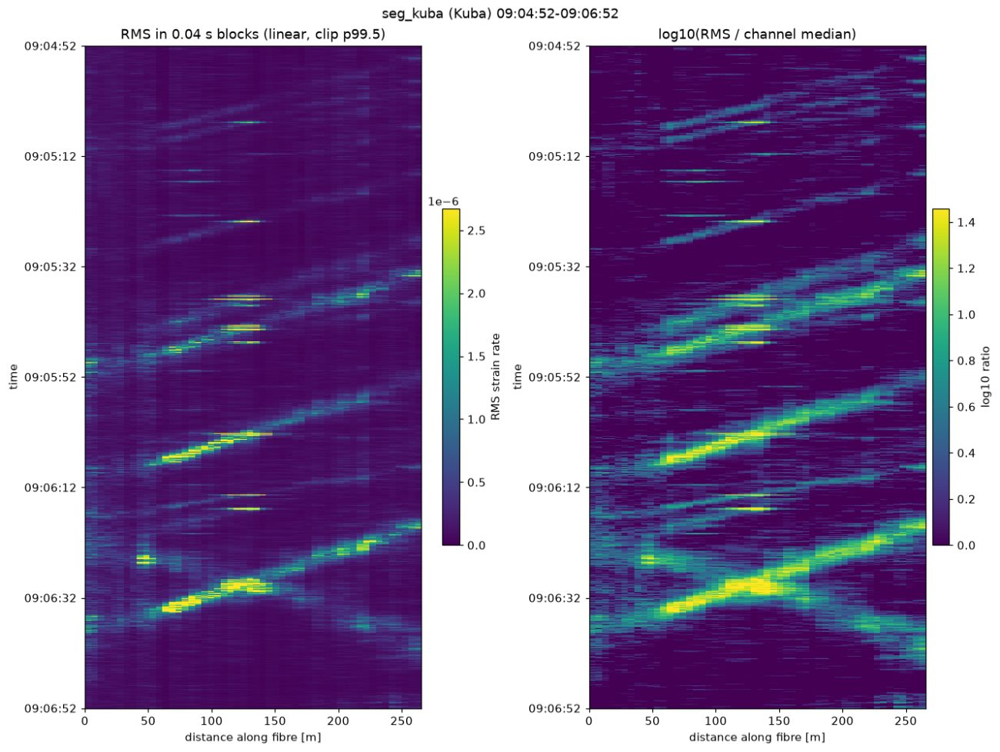

In [9]:
fig("eda_seg_kuba_waterfall")

Raw signed signal of the busiest 10 s of `seg_own` - oscillations under a moving envelope:

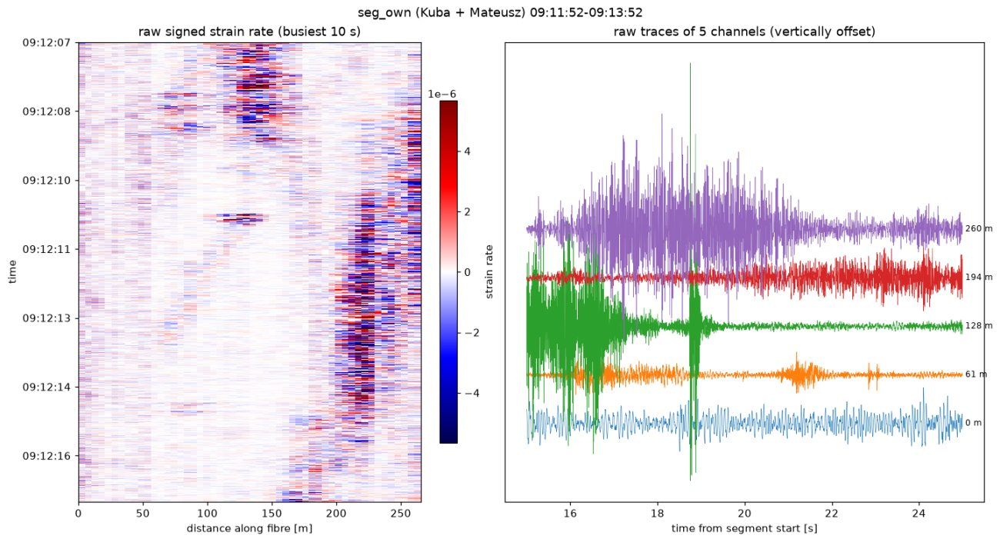

In [10]:
fig("eda_seg_own_raw_zoom")

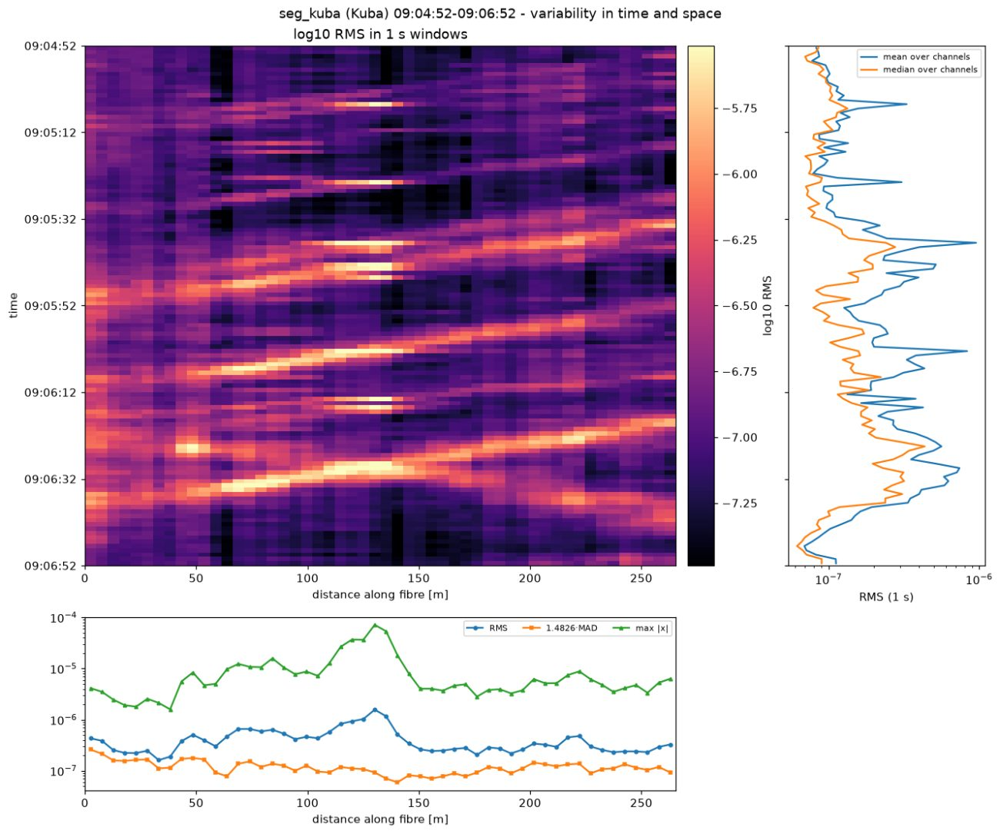

In [11]:
fig("eda_seg_kuba_variability")

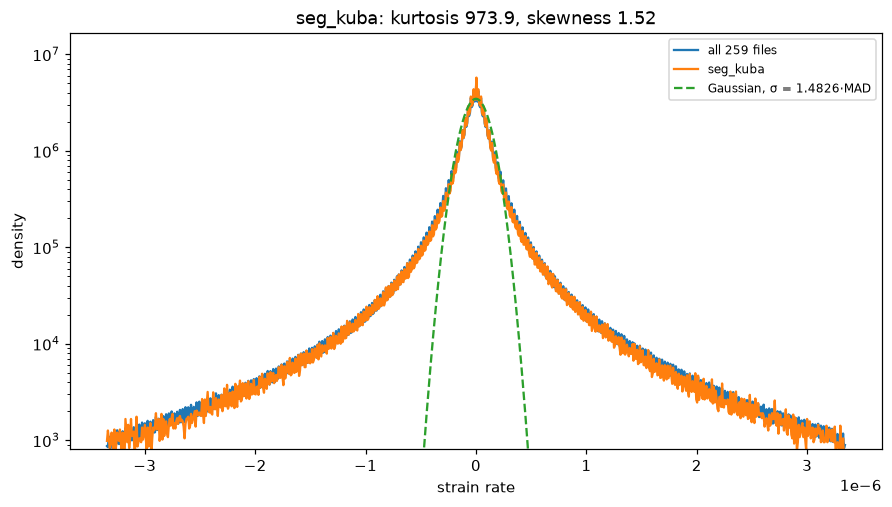

In [12]:
fig("eda_seg_kuba_histogram")

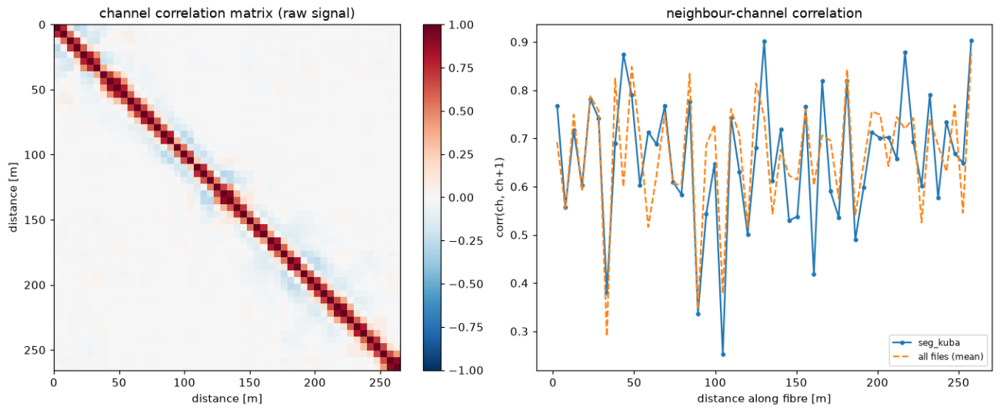

In [13]:
fig("eda_seg_kuba_correlation")

## 3. Frequency analysis

All spectra are computed with `numpy.fft` (SciPy is not on the list of allowed libraries).
**The FFT is applied independently to each channel** (`spectral.channel_fft`: Hann window,
`rfft` along time for every column). Further tools: Welch PSD (`welch_psd`, frames from
`sliding_window_view`, Parseval checked in a test), STFT (`stft`, 1 s windows) for selected
channels, and the 2-D **f-k spectrum** (`fk_spectrum`), in which a pattern moving with
velocity *v* lies on the line $f = -v k$ - the basis of the velocity filter of section 6.

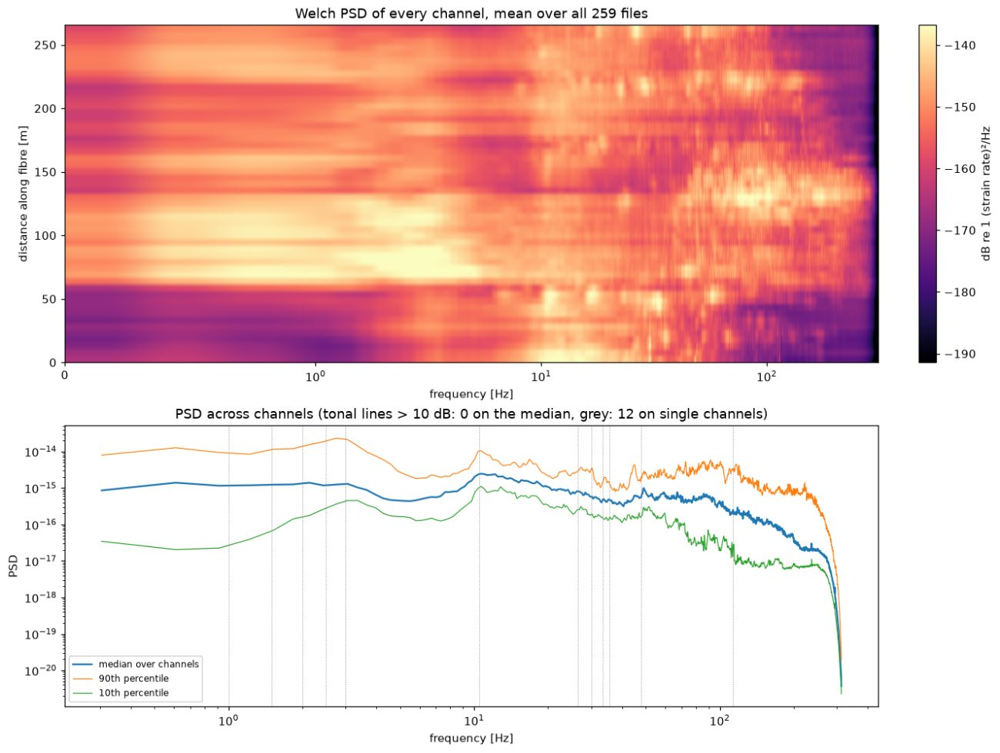

In [14]:
fig("spectral_global_psd")

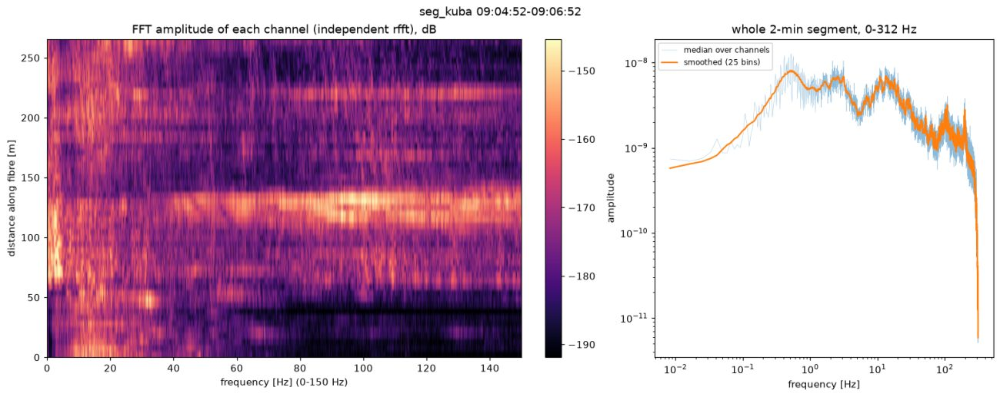

In [15]:
fig("spectral_seg_kuba_fft")

STFT of three channels (41 m, the 128 m hotspot, 214 m): trams are broadband (20-150 Hz) for
several seconds, the hotspot gives short broadband impacts around 100 Hz, and there are weak
stationary local lines (≈12 Hz, 31-35 Hz).

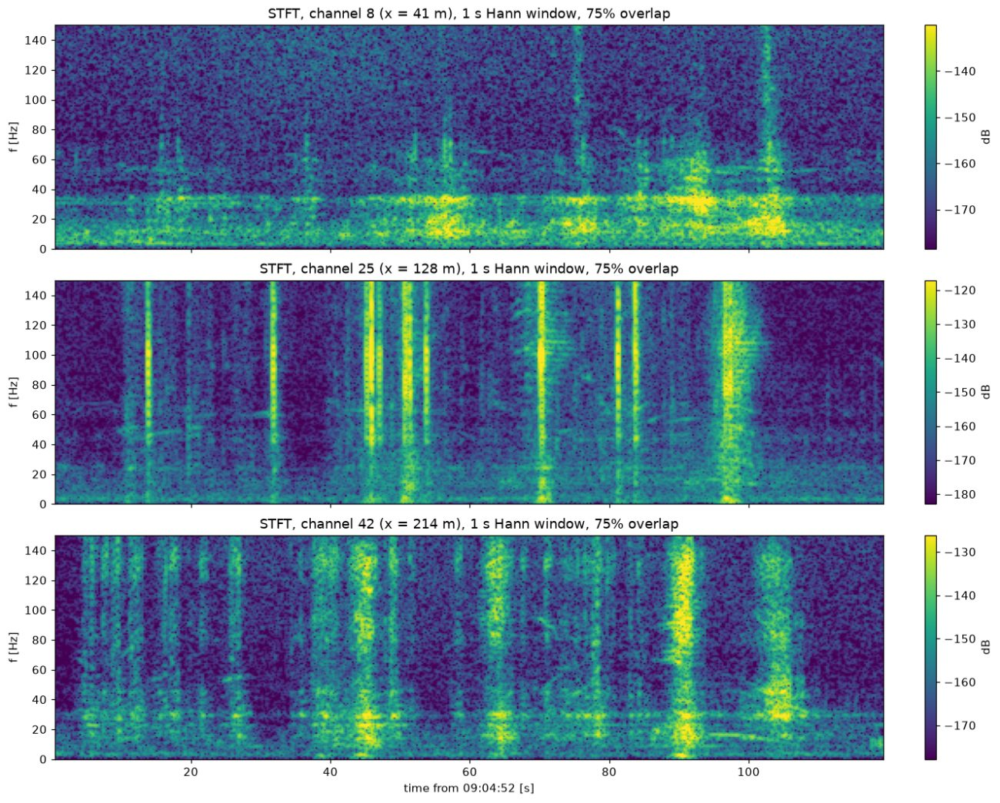

In [16]:
fig("spectral_seg_kuba_stft")

**f-k spectra** of the raw signal and of the LF / HF envelopes with ±20 / 50 / 100 km/h lines. In
the envelopes the energy concentrates inside the vehicle "fan"; 52-59 % of the HF envelope
energy of `seg_kuba` / `seg_mateusz` lies at −150…−10 km/h and only 8-10 % at +10…+150 km/h,
while `seg_own` has both directions (49 % vs 24 %). The vertical band at k ≈ 0 (events
simultaneous on all channels) lies outside the fan.

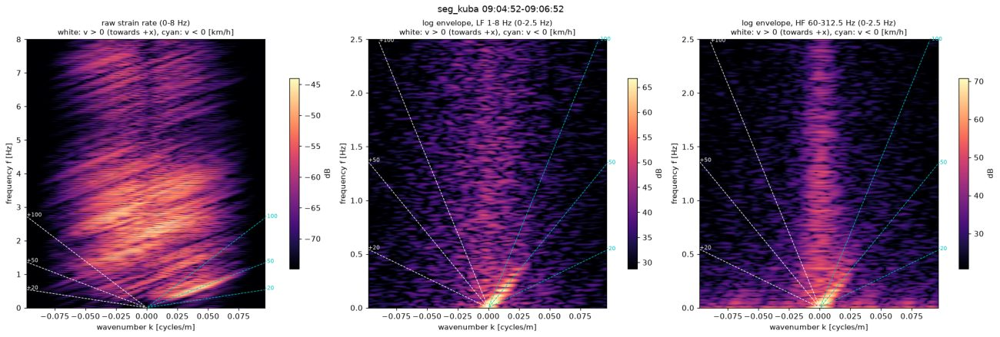

In [17]:
fig("spectral_seg_kuba_fk")

**Tonal interference.** No spectral line > 10 dB above a running-median baseline exists on the
channel-median PSD (no 50 Hz mains), so **no notch filter is needed**; weak lines on 1-5 single
channels are removed implicitly by per-channel normalisation and the fan filter.

**Vehicle vs background contrast** per frequency (2 s cells, per channel top 10 % vs bottom 30 %
RMS): 26 dB at 1 Hz, a minimum of 15 dB at 5-10 Hz and a maximum of **38 dB around 80 Hz**.

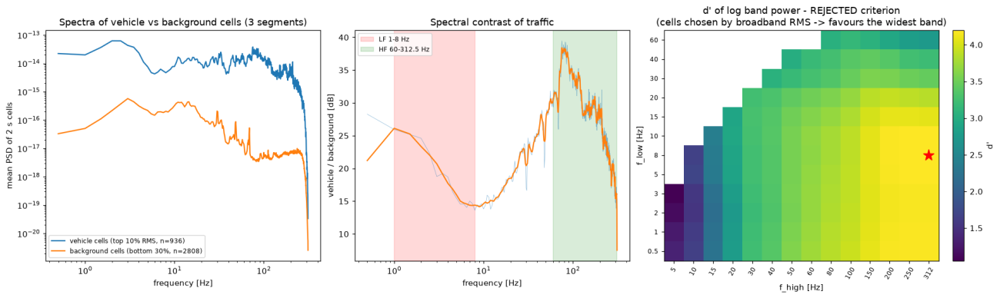

In [18]:
fig("spectral_band_contrast")

**Choice of the pass bands - objective criterion.** For a grid of 16 × 19 bands each segment is
processed as in sections 5-6 (common mode → band-pass → log RMS envelope → f-k fan filter) and
scored by the **line SNR** = 99th percentile of the robust z-score of the result.

* **HF path 60-312.5 Hz: line SNR 5.84** (the best 10 bands all lie in 50-80 Hz × 120-312 Hz);
* **LF path 1-8 Hz: line SNR 5.39** (best band with an upper edge ≤ 10 Hz);
* a single broad band 0.2-312.5 Hz reaches only 4.88, i.e. **both paths beat one broad band**.

Two other criteria were tried and rejected (log #6, #7): the d' of band power (circular - the
cells are selected by broadband RMS, so the widest band always wins) and the fraction of f-k
energy inside the fan (energy-weighted, it picked 0.2-1 Hz, visually the worst band).

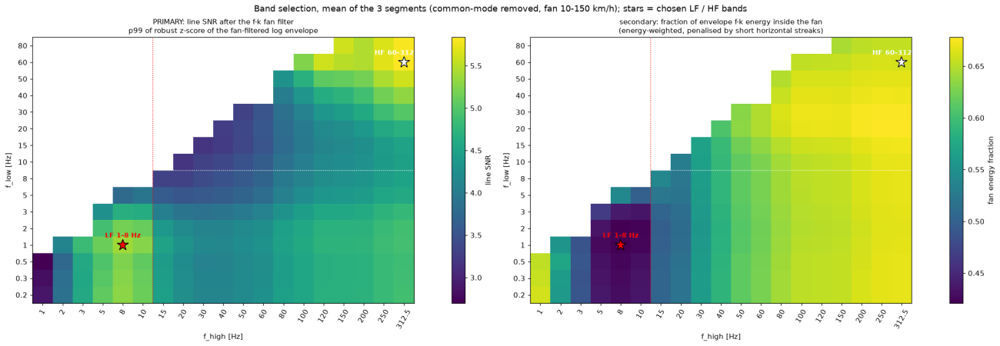

In [19]:
fig("spectral_band_selection")

**Visual comparison of 8 bands** (`seg_kuba`): LF shows the sharpest thin car lines (quasi-static
load of the vehicle) but is blind for x < 55 m and misses some lanes (e.g. the tram towards +x at
09:06:20-09:06:45 is visible only in HF); HF has a clean background and all thick lines, with
wider car lines. ⇒ **Two complementary processing paths, HF and LF** (the brief explicitly allows
multiple processing paths).

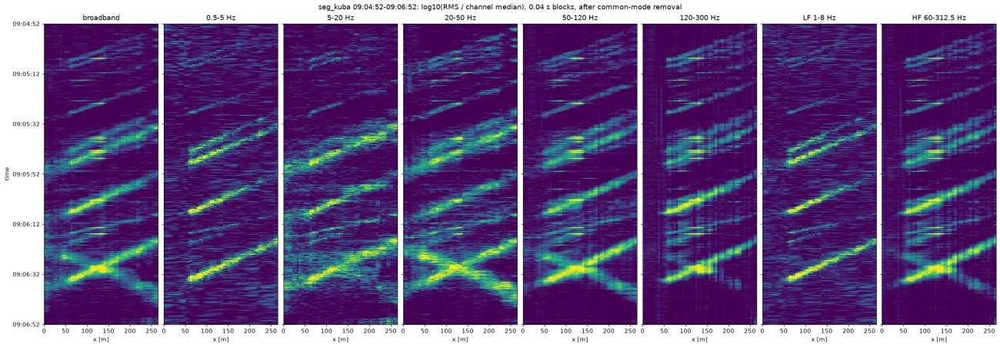

In [20]:
fig("spectral_seg_kuba_band_comparison")

## 4. Algorithm overview (block diagram)

The diagram below is drawn by `scripts/make_report_figures.py` (same blocks as the mermaid
source in `docs/flowchart.md`). Red notes on the right say what each block removes. Every
parameter is a field of a dataclass in `src/das/config.py` (`PipelineParams`), saved with the
results; nothing is tied to individual lines or to the three segments.

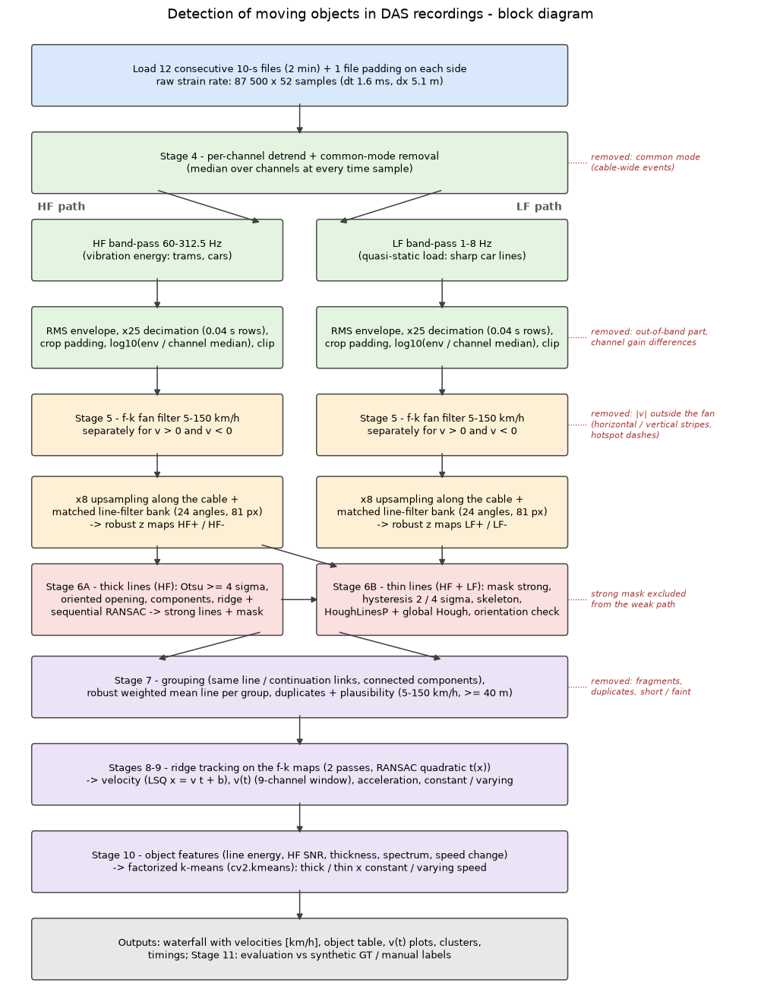

In [21]:
fig("flowchart", width=820)

| Block | What it does | Why |
|---|---|---|
| **Load** (`io.py`) | 12 consecutive files → 2-min matrix; one file of padding on each side; continuity check | analysis unit of the brief; padding prevents FFT edge effects at the segment ends |
| **Detrend + common mode** (`preprocessing.py`) | per-channel mean / linear trend removal; subtract the median over channels at every sample | events seen by the whole cable at once (interrogator noise, distant sources) are not vehicles; without it the light-vehicle AUC drops 0.830 → 0.810 |
| **Band-pass HF / LF** | zero-phase FFT filter with raised-cosine edges: HF 60-312.5 Hz, LF 1-8 Hz | bands chosen by line SNR (section 3); HF = clean vibration energy, LF = sharp car lines |
| **Envelope + log normalisation** | RMS of 25-sample blocks (0.04 s rows, 3000 rows / 2 min); log10(env / channel median), clipped to [0, p99.5] | the oscillating signal becomes an energy image; the log equalises channel gains and lifts thin lines next to trams |
| **f-k fan filter** (`enhancement.py`) | 2-D FFT of the image, keep only apparent velocities 5-150 km/h, separately for each direction | horizontal stripes (v → ∞), vertical stripes / static channels (v → 0) and the hotspot dashes are removed; crossing lines of opposite directions are separated |
| **Upsampling + filter bank** | ×8 interpolation along the cable (0.64 m columns), correlation with 24 oriented line kernels per direction (81 px, Gaussian cross-profile), max response → robust z map + local orientation | 52 columns are too few for angles; the matched filter integrates along the line and raises weak lines above the noise |
| **6A strong lines** (`detection.py`) | Otsu threshold (floor 4 σ) of the HF map → opening with line elements → components → ridge + sequential RANSAC | thick trams / trucks; RANSAC separates touching trams |
| **6B weak lines** | strong mask excluded → hysteresis 2 / 4 σ → skeleton → HoughLinesP + global `hough_line` on HF and LF → slope + local-orientation check | thin car lines (grade-5 condition), mostly found in LF |
| **Grouping** (`grouping.py`) | link candidates of one vehicle (same line / continuation), connected components, robust weighted mean line; remove duplicates, too short / implausible objects | many candidates per vehicle → one averaged line per object (as suggested by the brief) |
| **Tracking + velocity** (`tracking.py`, `velocity.py`) | ridge of the f-k map in every channel around the mean line, RANSAC quadratic t(x), refinement; v = LSQ slope of x(t); v(t) from a 9-channel sliding fit; acceleration and constant / varying label | the reported velocity of each object and its velocity profile (extra point 1) |
| **Features + clustering** (`features.py`, `clustering.py`) | cross-profile energy, HF SNR, thickness, spectrum, speed change → factorized k-means | groups thick / thin × constant / varying speed (extra point 2) |
| **Evaluation** (`evaluation.py`) | one-to-one matching with the synthetic GT and with manual labels; P / R / F1 thick vs thin, velocity error, trajectory IoU | quantitative evidence for every design decision |

## 5. Pre-processing (noise removal, energy image)

`preprocessing.preprocess` runs the chain for both bands and stores **every intermediate image**
(at the 0.04 s image resolution) - including what each step removed - so the figures below show
*before / after / removed* for every step. One segment takes ≈0.5-1 s for both bands.

1. **Detrend** each channel (vectorised least squares). No measurable effect after the
   band-pass, kept because it is cheap and safe.
2. **Common-mode removal**: median across channels at every time sample (removed component
   stored). Without it the HF light-vehicle AUC drops 0.830 → 0.810.
3. **Band-pass** (FFT, zero phase, raised-cosine edges, > 40 dB stop-band in the tests): HF
   60-312.5 Hz, LF 1-8 Hz. The out-of-band part is stored.
4. **Envelope + downsampling**: RMS of blocks of 25 samples (0.0016 s × 25 = 0.04 s per row;
   a vehicle at 150 km/h needs 0.12 s per channel, so nothing is lost). Plain decimation without
   an envelope aliases the oscillating signal (light AUC 0.729 vs 0.830); mean |x| equals RMS.
5. **Normalisation + log compression**: log10(envelope / channel median) clipped to [0, p99.5]
   - per-channel gain normalisation and dynamic-range compression in one step. Without the lower
   clip the LF AUC drops 0.960 → 0.938; a robust z-score variant was slightly better on
   synthetic HF but worse on real data.
6. Optional steps that were **tested and switched off** (no gain): interpolation of the
   flagged channel (it is a physical hotspot), anisotropic Gaussian smoothing (±0.001 AUC),
   CLAHE (+0.003 synthetic AUC but lower SNR on real data).

(AUC = pixel-level separability of vehicle vs background pixels against the synthetic ground
truth, light = car / van; details in section 6 and log #11-#14.)

**HF path, `seg_kuba`** - raw → common mode removed → band-passed → envelope → normalised image, with the removed components:

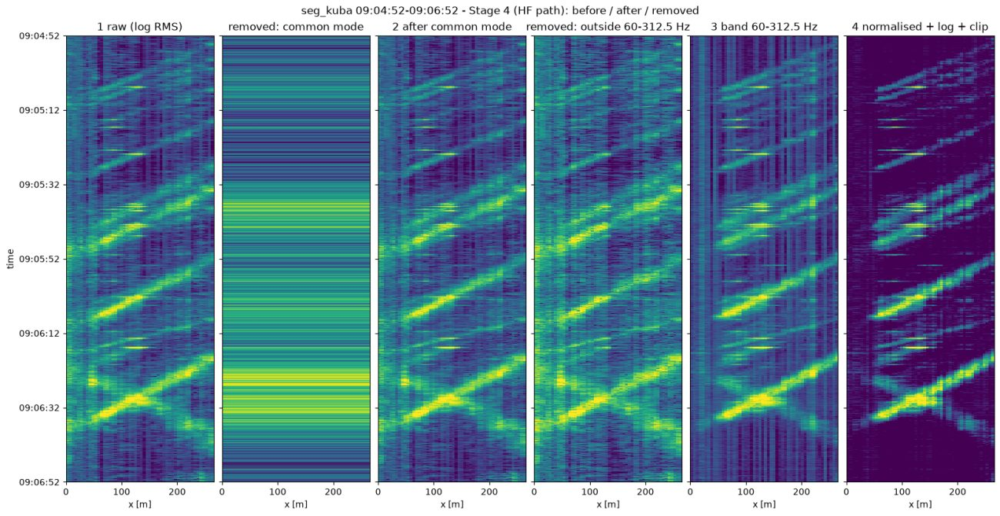

In [22]:
fig("stage4_seg_kuba_hf")

**LF path, `seg_kuba`:**

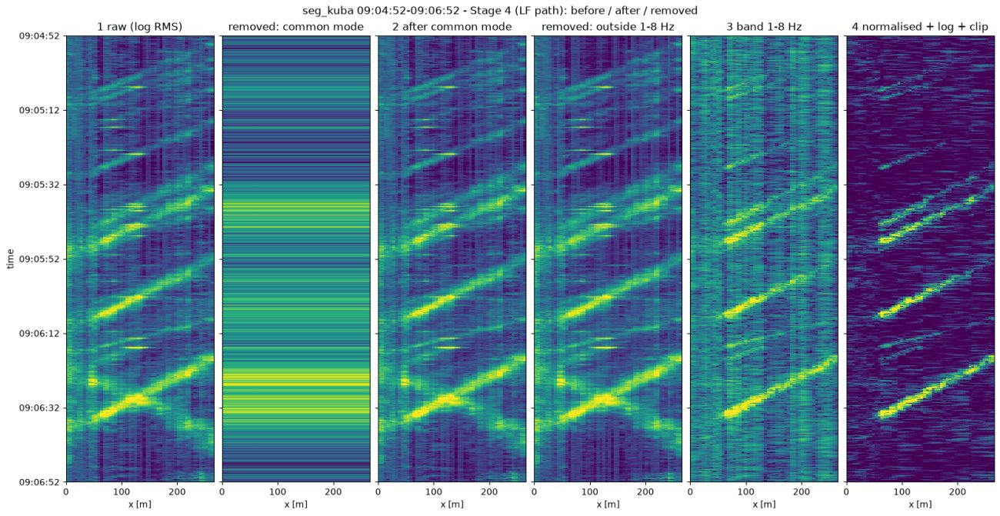

In [23]:
fig("stage4_seg_kuba_lf")

## 6. Line enhancement: only moving objects remain

`enhancement.enhance` turns each band image into two robust z maps, one per direction of motion
(HF+, HF−, LF+, LF−).

**f-k fan filter** (`fk_velocity_filter`). The image is transformed with a 2-D FFT; a tapered
raised-cosine mask keeps only apparent velocities $5 \le |v| \le 150$ km/h, separately for
$v > 0$ and $v < 0$ (k = 0 rejected). Horizontal structures (simultaneous events, fast seismic
waves: v → ∞) and vertical ones (static channel noise: v → 0) fall outside the fan, so after this
step **only slanted lines remain** - the requirement of the brief. The lower limit is 5 km/h, not
10, because a vehicle slower than 10 km/h in synthetic sample 40 was removed completely
(limitation: a vehicle that stops is suppressed). Spatial zero padding to 128 columns limits the
wrap-around of the circular FFT; reflect padding removes leakage of full-width stripes in a test,
but after common-mode removal such stripes no longer exist and zero padding is slightly better
on the data.

**Directional matched-filter bank.** The image is upsampled ×8 along the cable
(`cv2.resize`, 0.64 m columns) so that typical lines have slopes near 45°, and correlated
(`cv2.filter2D`) with 24 line kernels per direction whose angles span the admissible
velocities (length 81 px ≈ 3 s along the line, Gaussian cross-profile σ = 2 px, Hann taper,
zero mean, unit norm). The maximum response is the output and the argmax gives each pixel a
**local orientation / velocity**, used later to reject Hough segments with a wrong angle.

**Pixel-level comparison** on synthetic data (AUC of vehicle vs background pixels; light =
car / van, heavy = tram / truck; 3 synthetic samples, times for 6 recordings):

| Enhancer | light AUC HF / LF / fused | heavy AUC | time |
|---|---|---|---|
| matched filter bank (first version, 41 px) | 0.830 / 0.960 / 0.962 | 1.000 | 26 s |
| f-k only (no enhancer) | 0.815 / 0.966 / 0.956 | 1.000 | 9 s |
| Sato (Hessian) | 0.812 / 0.936 / 0.948 | 0.996 | 81 s |
| Meijering | 0.759 / 0.898 / 0.917 | 0.985 | 55 s |
| Gabor bank | 0.841 / 0.943 / 0.949 | 0.997 | 31 s |
| no f-k filter | 0.790 / 0.925 / 0.933 | 0.999 | 24 s |
| **final: bank 81 px + zero padding + fan 5-150 km/h** | **0.867 / 0.972 / 0.974** | **1.000** | 27 s |

Heavy vehicles are separated almost perfectly by any reasonable variant; **light vehicles are
the difficulty of grade 5**, and the matched bank with the f-k filter is best. The Hessian
filters are tuned to tubular structures of a given width and lose the thin, noisy car lines;
they are also 2-3× slower. The same comparison repeated at the *object* level is in section 12.

**HF path of `seg_kuba`**: input → f-k filtered (both directions) → removed by the fan → per direction: f-k map, upsampled, filter-bank response:

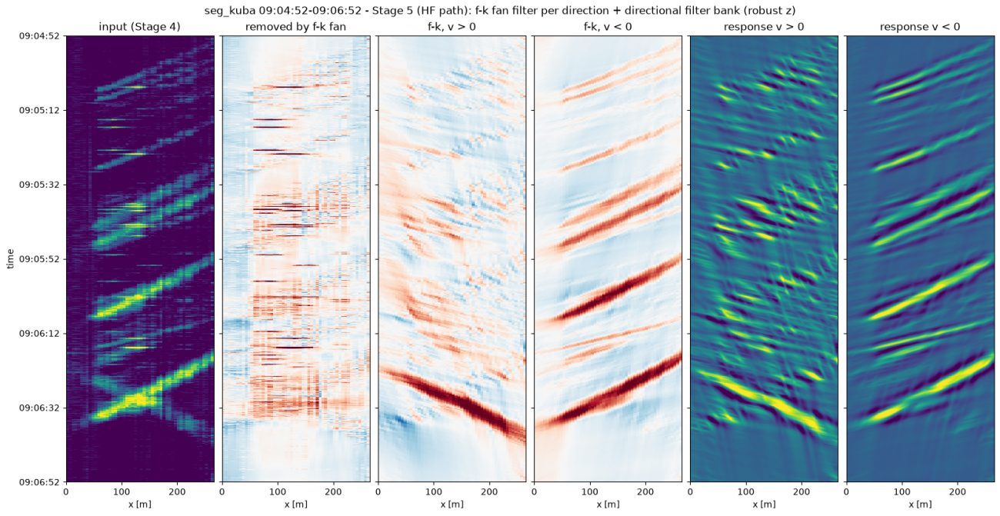

In [24]:
fig("stage5_seg_kuba_hf")

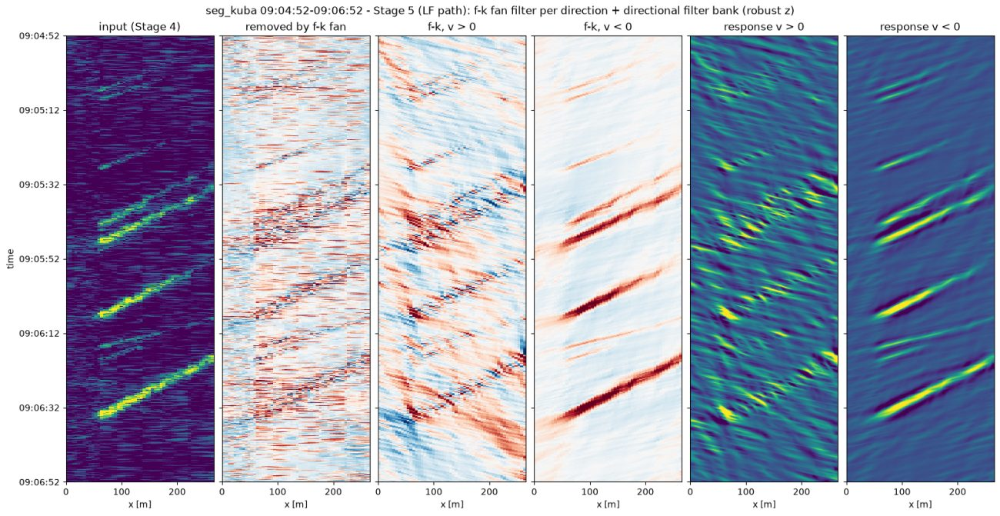

In [25]:
fig("stage5_seg_kuba_lf")

Final maps of `seg_own` (the segment with traffic in both directions): crossing lines are
separated by direction, the horizontal hotspot dashes at ≈128 m are gone, and thin lines are
clearest in LF. Maps of a direction with little traffic show an oblique noise texture with
z ≈ 2-4 - therefore all detection thresholds are relative to the robust noise level of each map.

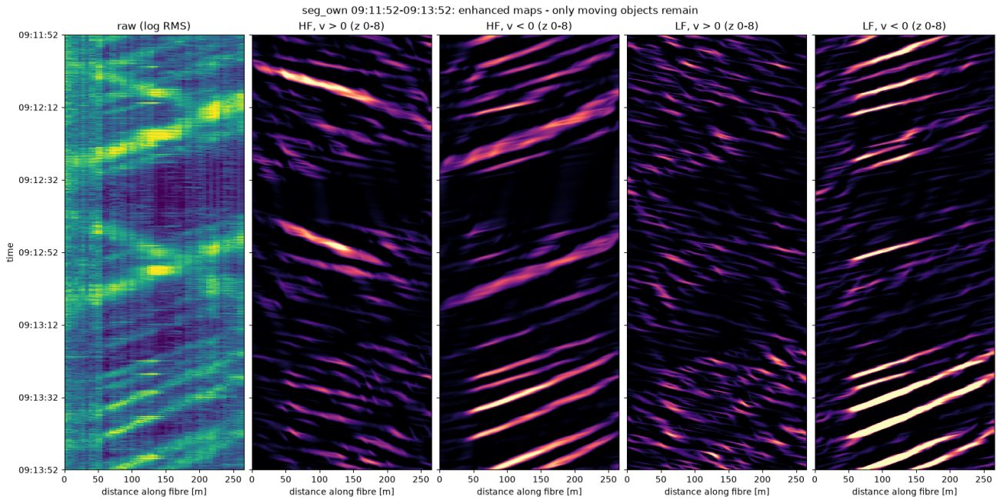

In [26]:
fig("stage5_seg_own_final_maps")

Synthetic sample 40: enhanced maps against the ground-truth mask:

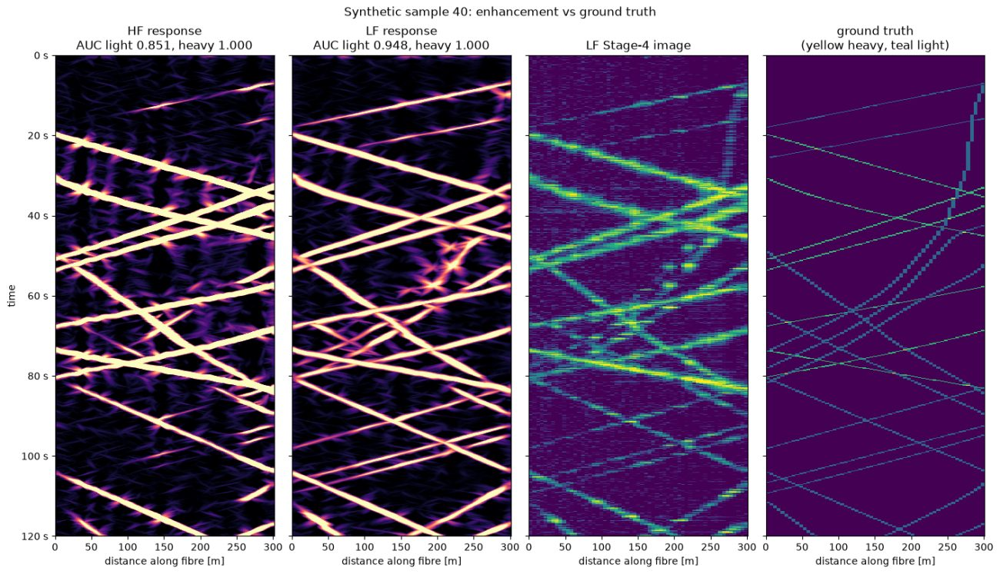

In [27]:
fig("stage5_synthetic_40")

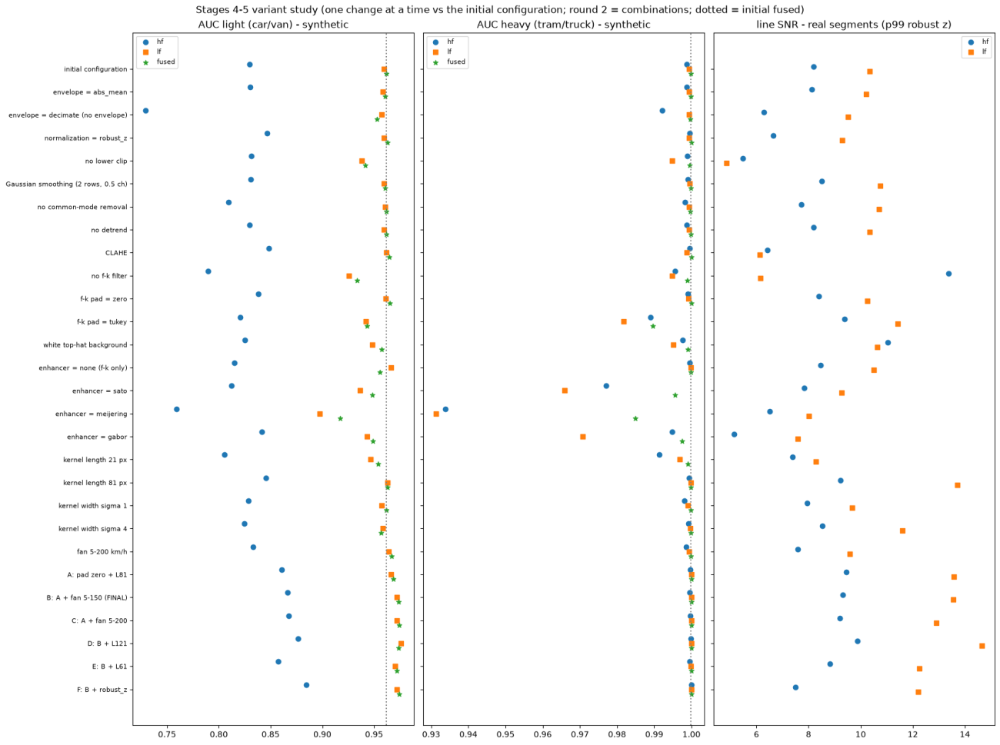

In [28]:
fig("stage5_variant_study")

## 7. Detection of strong and weak lines, grouping

`detection.detect_candidates` runs two processing paths on the four maps. Pixel units refer to
the response grid (1 row = 0.04 s, 1 column = 0.64 m); all thresholds are multiples of the
**robust σ** (1.4826 MAD) of the map itself, so they adapt to each recording.

**Path 6A - thick, strong lines (HF maps).**
1. Threshold = Otsu of the positive response, floored at 4 σ (in a direction without trams
   Otsu would otherwise split pure noise; 6 σ missed wide, diffuse tram lines on real data whose
   skeleton in 6B is branched, 3 σ duplicated lines - log #21).
2. Union of binary **openings with line structuring elements** of 9 admissible slopes (41 px):
   specks and horizontal / vertical streaks disappear.
3. Connected components (`skimage.measure.label` / `regionprops`): area ≥ 1500 px, extent ≥ 40 m.
4. **Ridge** of each component (local maxima along time, NMS ±0.2 s) + **sequential RANSAC**
   (`skimage.measure.ransac`, up to 4 lines per component): two touching trams give two lines.
   The first version used per-column centroids and failed exactly there (log #19).
5. The kept components form the **strong mask**.

**Path 6B - thin, weak lines (HF and LF maps), the grade-5 condition.**
1. The strong mask, dilated by ±0.5 s × ±4 m, is replaced by the background median - a tram's
   halo would otherwise produce many false thin lines.
2. **Hysteresis** thresholds med + 2σ / med + 4σ of the background (`apply_hysteresis_threshold`),
   `remove_small_objects`, `skeletonize`.
3. **`cv2.HoughLinesP`** (local, fragmented segments) **and** global **`skimage hough_line`** +
   `hough_line_peaks` (votes along whole lines - long, very weak lines), both restricted to the
   angles of the admissible velocities. The two find different lines (log #23).
4. Filters: slope inside the velocity fan, **local orientation** of the filter bank within 10° of
   the segment angle, mean response ≥ low threshold.

**Stage 7 - grouping and averaging** (`grouping.build_objects`). Two candidates of one
direction are linked if they are the *same line* (|Δv| < 8 km/h or 15 % and a time gap at their
midpoint below the tolerance of 1.5 s or half the thickness of a strong candidate -
chosen in Stage 13, section 12.4) or a *continuation* (consecutive x-ranges that meet - joins bent
pieces of braking vehicles). Connected components of the link graph are the groups; each group
gives one line by a robust weighted least-squares fit of t(x) (weights = response × band weight,
LF ×2, MAD re-weighting). Duplicates are removed, objects must span ≥ 8 channels with
5 ≤ |v| ≤ 150 km/h, and a weak object must be long (≥ 60 m) or clearly above the noise (≥ 5 σ) -
the statistics of true and false weak objects behind this rule are in log #29.

All steps of both paths on the HF v < 0 map of `seg_own` (threshold → opening → components → strong lines; mask → hysteresis → skeleton → Hough):

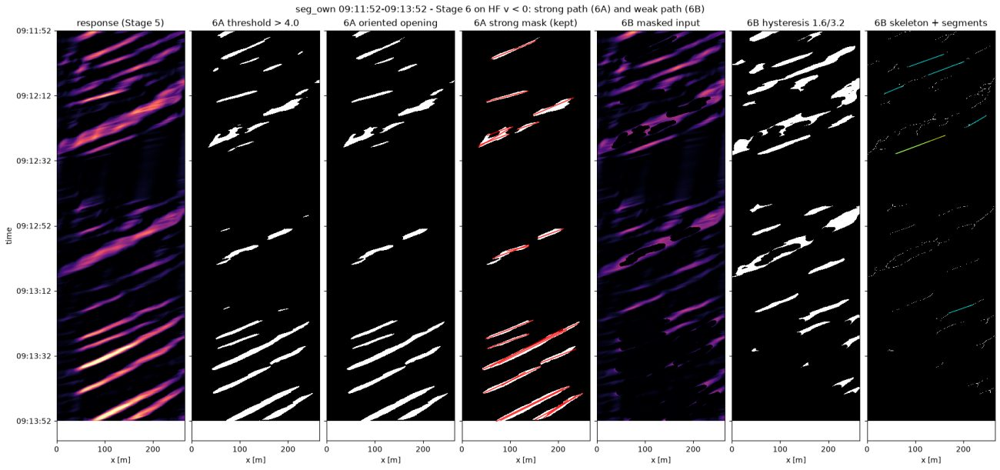

In [29]:
fig("stage6_seg_own_hf_neg")

The same for the LF v < 0 map, where most thin car lines are found:

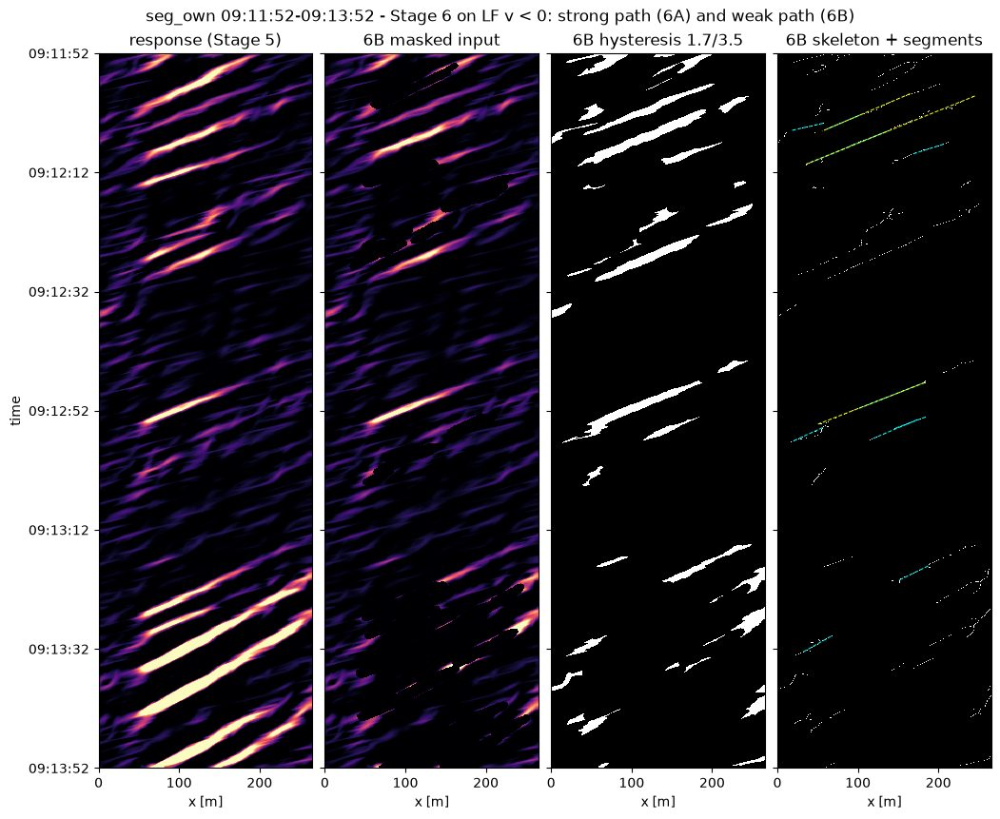

In [30]:
fig("stage6_seg_own_lf_neg")

Candidates of all four maps → groups (one colour per group) → one averaged line per object (`seg_own`):

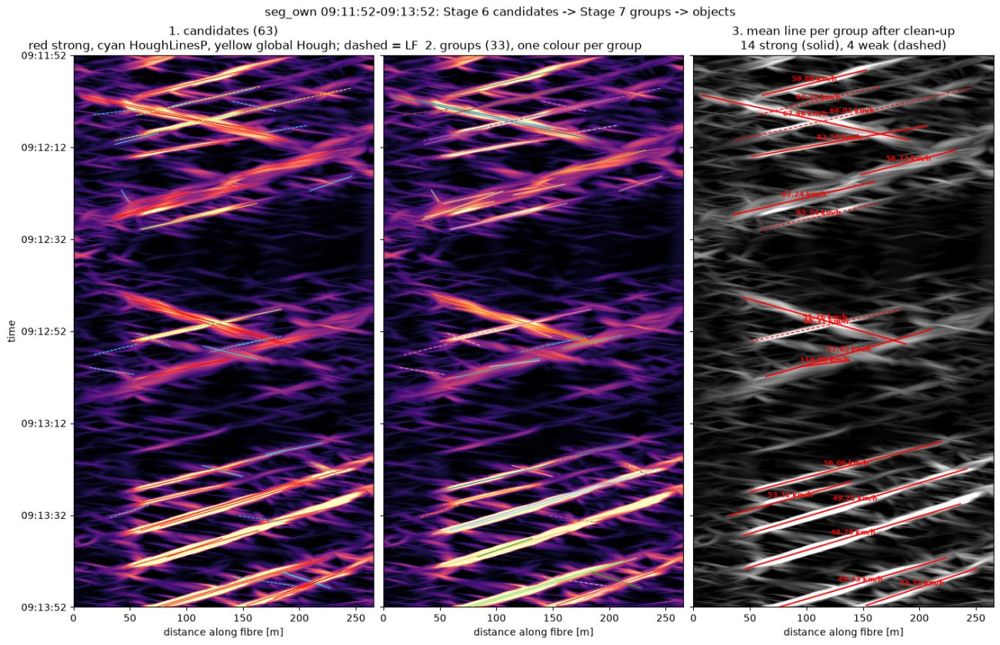

In [31]:
fig("stage7_seg_own_candidates")

Synthetic sample 42: detected objects against the ground truth:

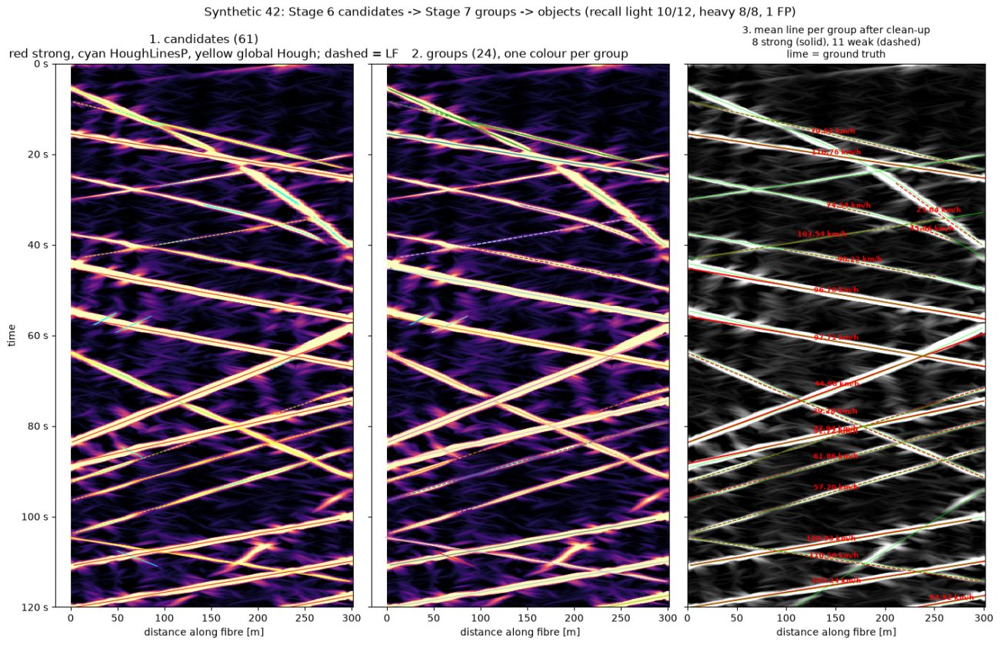

In [32]:
fig("stage6_synthetic_42")

**Stage-6 study on the synthetic data** (objects after grouping, 85 light + 49 heavy vehicles;
`run_detection.py`, log #24). The strong path alone - enough for grade 3/4 - finds almost all
trams but only 18 % of the cars; the weak path and especially its LF band are what finds the
thin lines. The same ablation on the final parameters, with the real-data labels, is in
section 12.

In [33]:
rows = read_csv("detection_variants.csv")
table(rows, ["group", "variant", "recall_light", "recall_heavy", "precision", "f1", "fp",
             "vel_mae_kmh", "real_strong", "real_weak"],
      ["group", "variant (synthetic, 6 samples)", "recall thin (car/van)", "recall thick (tram/truck)",
       "precision", "F1", "FP", "line |v| MAE [km/h]", "real strong", "real weak"])

| group | variant (synthetic, 6 samples) | recall thin (car/van) | recall thick (tram/truck) | precision | F1 | FP | line \|v\| MAE [km/h] | real strong | real weak |
|---|---|---|---|---|---|---|---|---|---|
| baseline | default | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.893 | 44 | 8 |
| hough | HoughLinesP only | 0.765 | 1.000 | 0.927 | 0.887 | 9 | 3.142 | 44 | 8 |
| hough | global hough_line only | 0.788 | 0.980 | 0.950 | 0.902 | 6 | 2.641 | 43 | 4 |
| hough | global Hough gap = HoughLinesP gap (20 px) | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.898 | 44 | 8 |
| paths | strong path only (grade 3/4) | 0.176 | 0.980 | 0.913 | 0.621 | 6 | 3.195 | 43 | 0 |
| paths | no masking of strong objects | 0.800 | 0.980 | 0.935 | 0.899 | 8 | 2.555 | 42 | 11 |
| paths | weak path HF only | 0.412 | 1.000 | 0.903 | 0.740 | 9 | 3.250 | 43 | 4 |
| paths | weak path LF only | 0.812 | 0.980 | 0.936 | 0.903 | 8 | 2.809 | 44 | 6 |
| paths | no local-orientation check | 0.871 | 1.000 | 0.932 | 0.925 | 9 | 2.830 | 45 | 11 |
| strong | one RANSAC line per component | 0.882 | 1.000 | 0.912 | 0.919 | 12 | 2.993 | 44 | 9 |
| strong | no ridge NMS (1 row) | 0.882 | 1.000 | 0.925 | 0.925 | 10 | 2.807 | 45 | 9 |
| strong | strong floor 3 sigma | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.893 | 73 | 2 |
| strong | strong floor 6 sigma | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.893 | 27 | 18 |
| strong | strong floor 10 sigma | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.896 | 6 | 33 |
| strong | strong threshold 8 sigma (no Otsu) | 0.871 | 0.980 | 0.961 | 0.935 | 5 | 2.766 | 18 | 25 |
| weak | hysteresis 1.5 / 3 sigma | 0.800 | 0.980 | 0.928 | 0.896 | 9 | 2.730 | 43 | 12 |
| weak | hysteresis 2.5 / 5 sigma | 0.847 | 1.000 | 0.945 | 0.924 | 7 | 2.863 | 43 | 6 |
| weak | hysteresis 3 / 6 sigma | 0.824 | 1.000 | 0.952 | 0.919 | 6 | 2.402 | 43 | 3 |
| grouping | no weak acceptance rule (support 40 m) | 0.894 | 1.000 | 0.906 | 0.919 | 13 | 2.942 | 44 | 27 |
| grouping | weak: support >= 60 m only (no score) | 0.812 | 0.980 | 0.951 | 0.911 | 6 | 2.696 | 44 | 7 |
| grouping | weak: support 80 m or score 5 | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.893 | 44 | 8 |
| grouping | weak: support 60 m or score 6 | 0.871 | 1.000 | 0.932 | 0.925 | 9 | 2.913 | 44 | 8 |
| grouping | no continuation link | 0.882 | 1.000 | 0.886 | 0.905 | 16 | 3.036 | 46 | 7 |
| grouping | tol_time 0.5 s | 0.882 | 1.000 | 0.919 | 0.922 | 11 | 2.895 | 65 | 10 |
| grouping | tol_time 1.5 s | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.893 | 44 | 8 |
| grouping | tol_velocity 4 km/h / 8 % | 0.871 | 1.000 | 0.925 | 0.921 | 10 | 2.861 | 46 | 8 |
| grouping | band weights LF = HF | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.931 | 43 | 8 |
| grouping | band weights LF x4 | 0.882 | 1.000 | 0.932 | 0.929 | 9 | 2.888 | 44 | 8 |

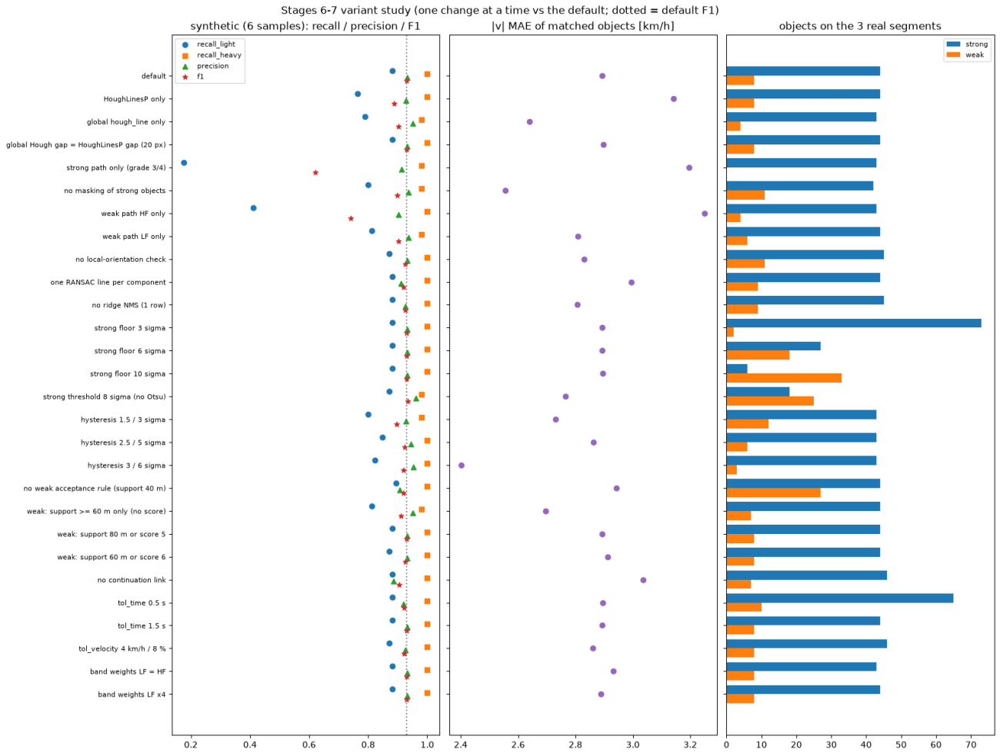

In [34]:
fig("stage6_variant_study")

## 8. Velocity estimation

The slope of a line in the image gives the velocity:
$v = \dfrac{\Delta \text{col} \cdot \Delta x_{col}}{\Delta \text{row} \cdot \Delta t_{row}}$ [m/s]
× 3.6 → km/h; the sign is the direction (+ towards increasing cable position).
The **reported velocity** of an object is the least-squares slope of x(t) = v t + b fitted to its
*tracked* passage times (section 9), with R² as a quality flag; the Stage-7 averaged line is only a
fallback for objects without a track. On synthetic data this lowers the |v| error from 2.89 to
1.89 km/h (log #34, final parameters).

The figure reproduces the style of the brief: red lines with "xx.xx km/h" labels on the raw
waterfall (strong objects solid, weak dashed), time in HH:MM:SS, position in metres.

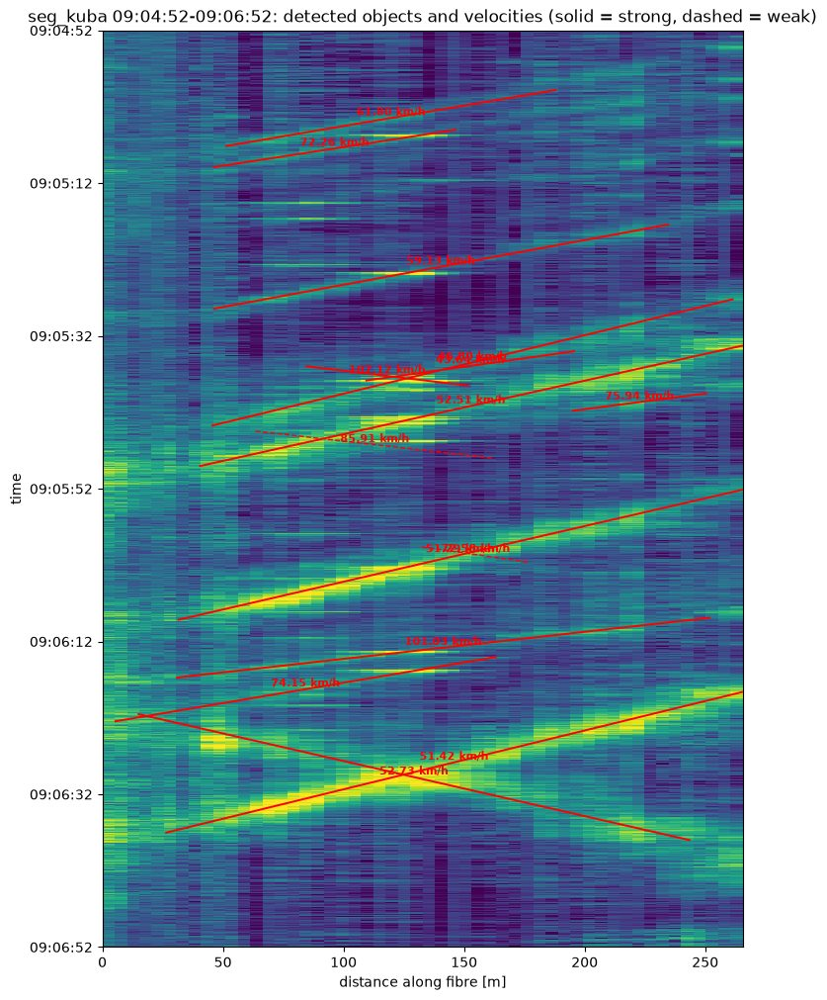

In [35]:
fig("stage8_seg_kuba_velocities")

## 9. Velocity over time (extra point 1)

A single slope assumes constant speed, but trams brake and cars accelerate. `tracking.track_ridge`
measures the **passage time of the vehicle in every channel**:

1. map = the f-k filtered map of the object's direction (sum of the HF and LF z maps, light
   smoothing along time). The filter-bank response is *not* used here because its straight
   81-px kernels straighten curved tracks (v(t) error 5.33 vs 2.29 km/h, log #32);
2. pass 1: in every channel the maximum within ±1 s of the averaged line, refined to sub-row
   precision by a parabola through the peak (vectorised over channels);
3. **RANSAC of a quadratic t(x)** (constant acceleration; all trials solved at once with batched
   Vandermonde systems) rejects peaks of crossing vehicles;
4. pass 2: maxima within ±0.5 s of that curve; only the longest run of channels is kept, and
   peaks within 0.5 s of the first / last image row are dropped (a ridge cut by the window end
   has its maximum on the border, which compressed the passage times and produced v(t) up to
   350 km/h for a vehicle leaving through the end of an ad-hoc window - fixed in Stage 13).

From the track: **v(t)** = local least-squares slope in a sliding window of 9 channels (46 m),
reported at the mean time of the window; a quadratic fit x(t) gives the acceleration along the
motion (+ faster, − braking) and the start / end speeds. An object is **varying speed** if
|v_end − v_start| ≥ 15 % of |v| *and* the quadratic model reduces the RMS residual by ≥ 30 %;
otherwise **constant**.

Synthetic validation (124 matched vehicles, GT v(t) from the GT track with a 3-channel window):
|v| MAE 1.89 km/h (thin 2.24, thick 1.35), **v(t) MAE 2.29 km/h**, median acceleration error
0.07 m/s², constant / varying agreement 0.85 (errors are mostly GT-varying → constant, i.e.
conservative: 18 of 64). Window 5 / 7 / 9 / 11 / 15 channels → v(t) MAE 4.31 / 3.01 / 2.29 / 1.87
/ 1.46 km/h; 9 is a compromise, because the smooth synthetic dynamics always reward smoothing
while real braking can be abrupt (log #37).

Averaged lines (dashed) vs measured curved tracks, coloured by speed class (`seg_own`):

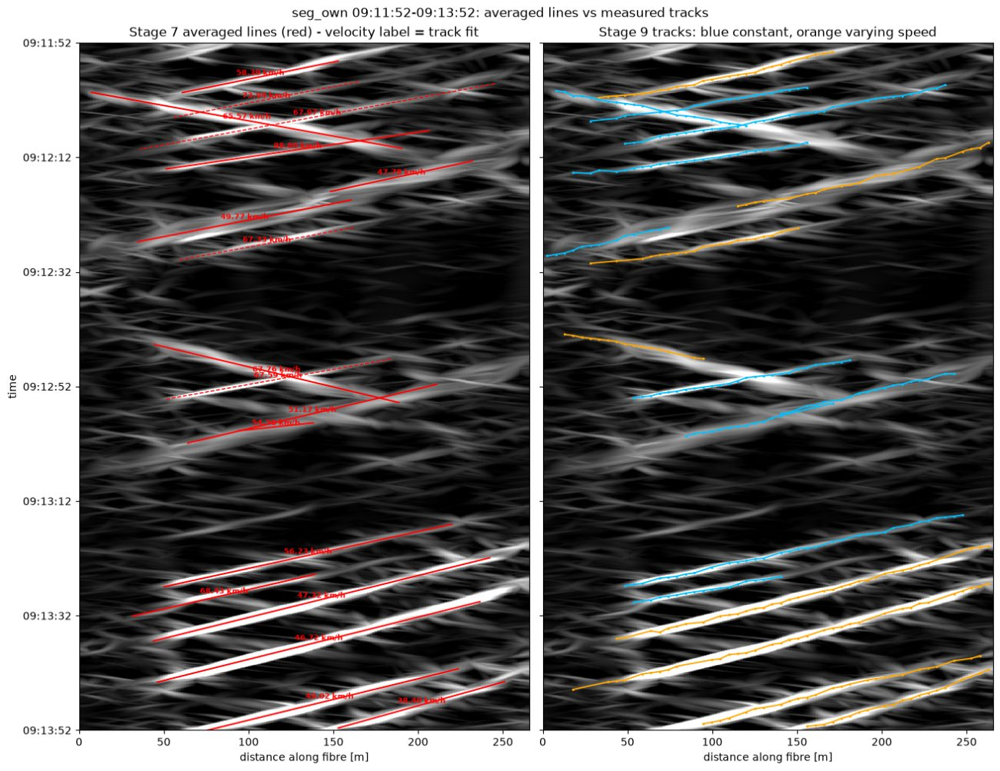

In [36]:
fig("stage9_seg_own_tracks")

**v(t) of all objects of `seg_own`** and per-object profiles with the constant and quadratic fits:

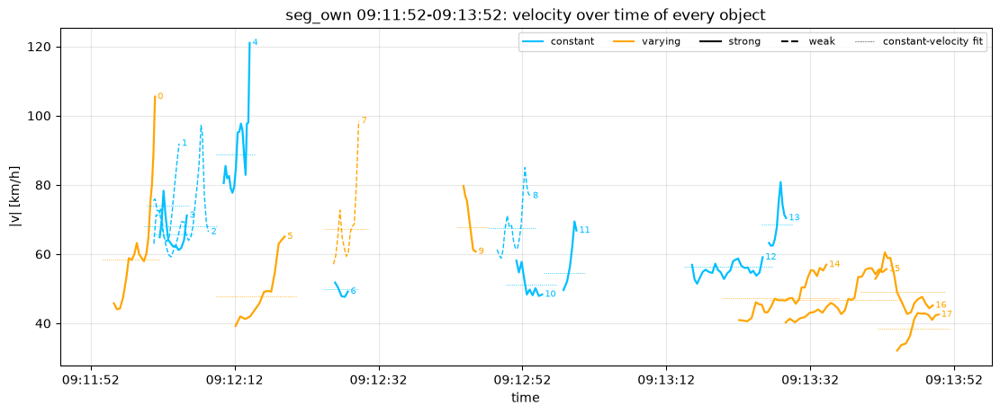

In [37]:
fig("stage9_seg_own_profiles")

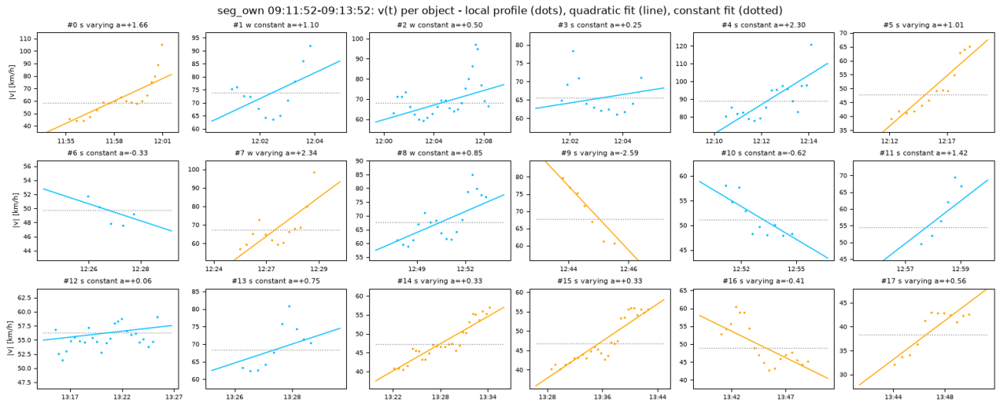

In [38]:
fig("stage9_seg_own_gallery")

Synthetic sample 42: measured v(t) (colour) against the ground-truth v(t) (black):

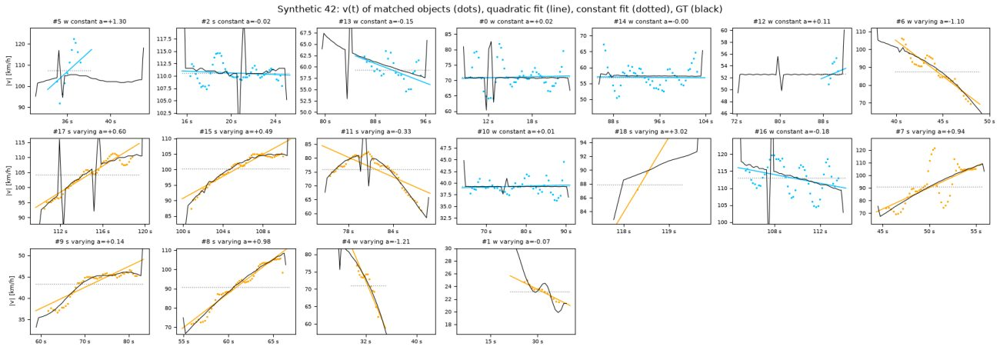

In [39]:
fig("stage9_synthetic_42_profiles")

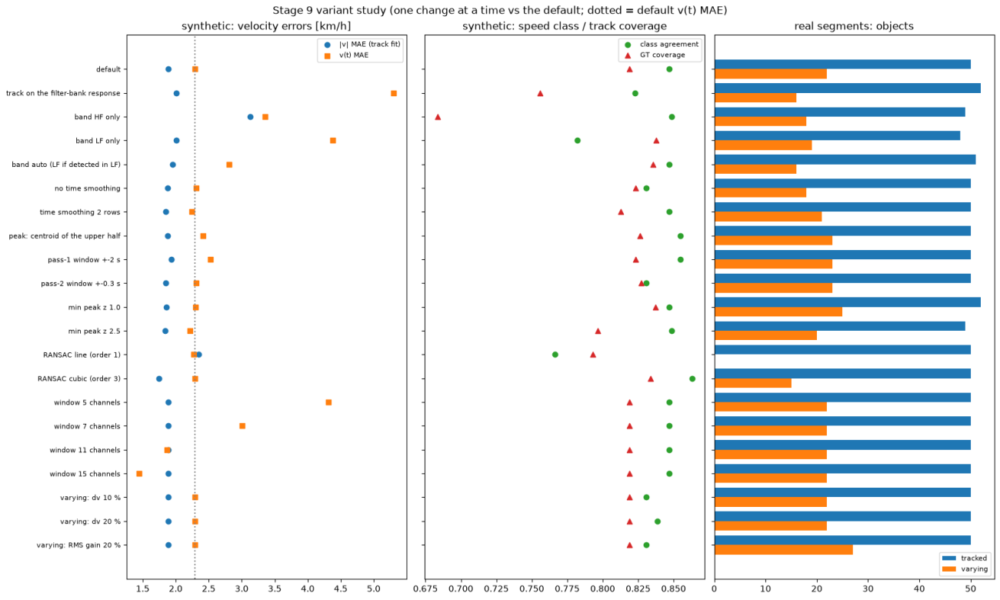

In [40]:
fig("stage9_variant_study")

## 10. Clustering of the detected objects (extra point 2)

**Features** (`features.object_features`, vectorised over channels, ≈0.01 s per object):

* *cross-profile of the line*: in every channel a ±2 s window of the f-k energy map around the
  track, re-centred on the ridge → FWHM thickness, peak z, area, number of sub-lines, tail
  asymmetry, z in HF and LF;
* *spectrum*: the raw signal in a 0.8 s window on the trajectory relative to the channel's
  background spectrum → SNR in LF and HF [dB], LF−HF ratio, spectral centroid;
* *motion*: |v|, relative speed change dv_rel, std of v(t), |acceleration|, R² (logarithms of
  the heavy-tailed ones).

**Feature choice from a separability study** (AUC of every feature on synthetic data, heavy vs
light and varying vs constant speed). HF SNR (0.99), peak z and line area (0.97) separate trams
from cars, the FWHM thickness only weakly (0.64): *a line looks thick because it is strong*.
Speed change: log dv_rel 0.90, log |a| 0.80. Spectrum shape and sub-lines carry no information
(≈0.5).

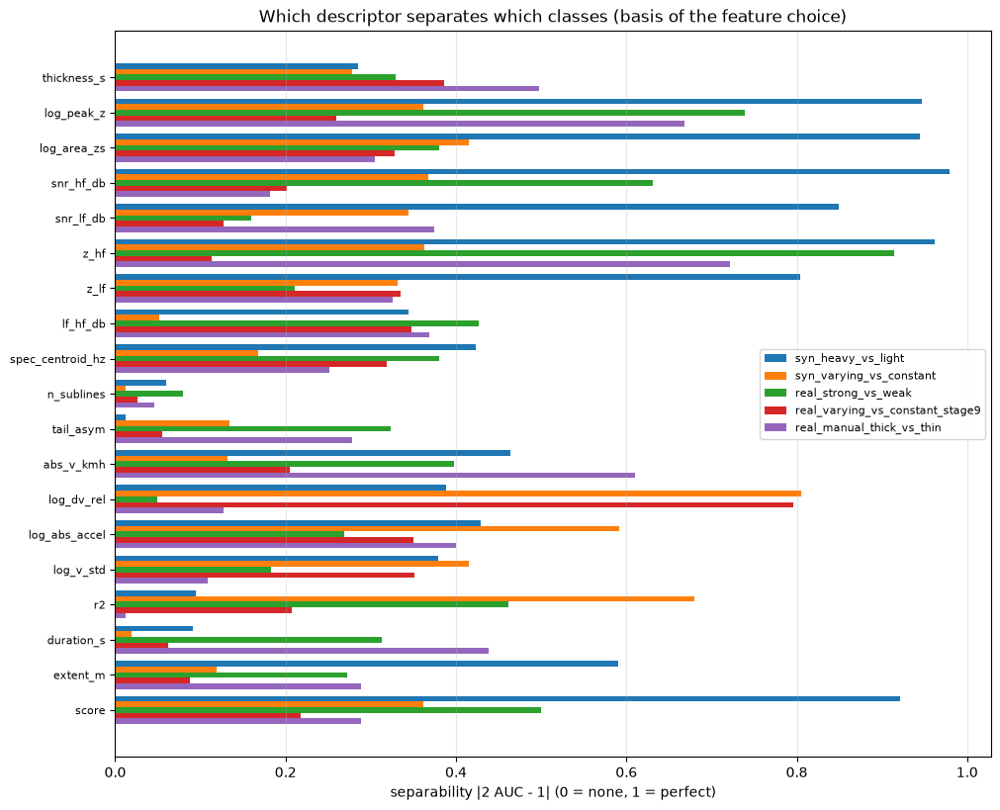

In [41]:
fig("stage10_feature_separability")

**Method: factorized k-means** (`cv2.kmeans`, k-means++ initialisation, 10 restarts, z-scored and
clipped features). One k-means per property - *thickness* = (log peak z, log area, HF SNR) and
*speed change* = (log dv_rel, log |a|, log std v) - with k ∈ {2, 3} chosen by the silhouette;
the levels are ordered and named, and a cluster is the combination of levels, so the cluster
names are directly the categories of the brief (*thick / medium / thin* × *constant / varying
speed*). A joint k-means on all features is kept as a comparison: with k chosen by silhouette it
only finds thick / thin, and adding velocity, spectrum and shape features destroys the
structure (ARI 0.12, log #45). Clustering runs over all objects of a run (one segment has too
few objects).

Validation on the matched synthetic objects: thickness level vs heavy / light purity **0.92**
(ARI 0.70), speed level vs GT speed class purity **0.79**; 4 clusters vs the 4 GT classes ARI
0.47 (a rule baseline - Otsu of the line area × Stage-9 class - gives 0.52, i.e. comparable).

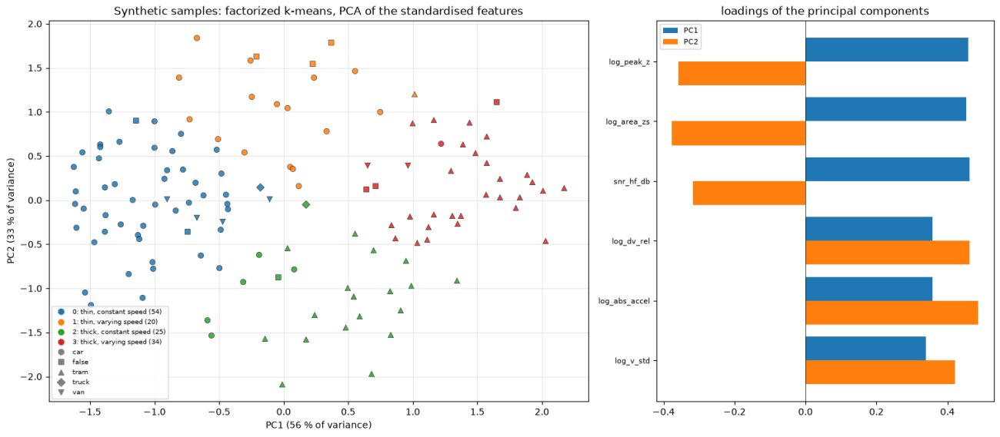

In [42]:
fig("stage10_synthetic_pca")

**Real data** - choice of k per property (silhouette and compactness), PCA of the objects, feature distributions per cluster:

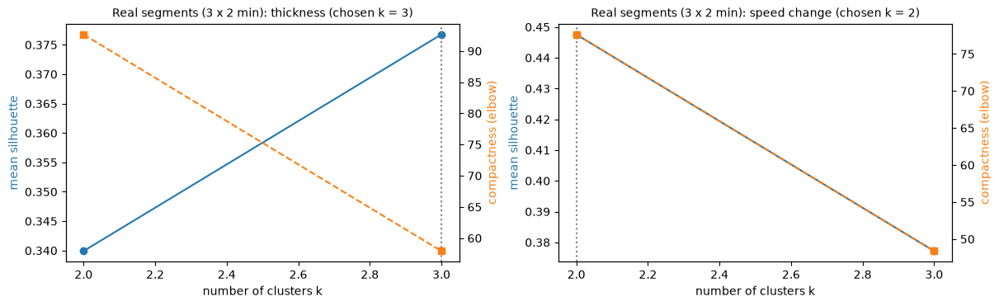

In [43]:
fig("stage10_real_k_selection")

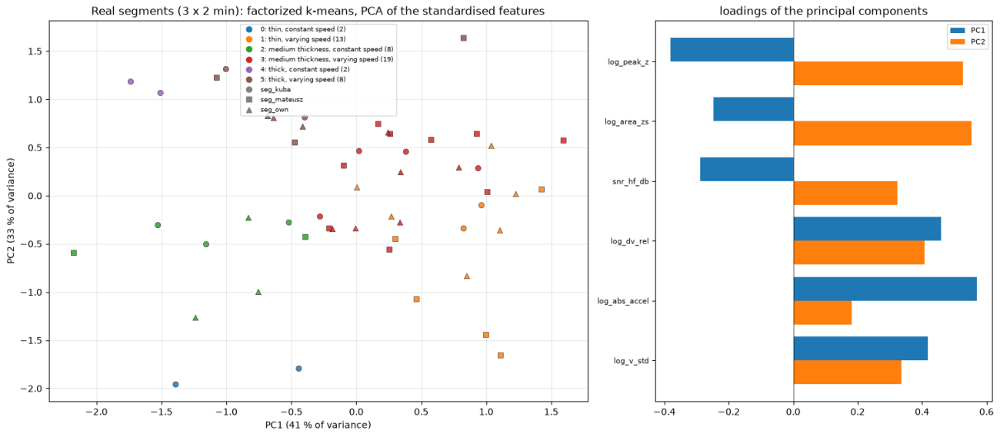

In [44]:
fig("stage10_real_pca")

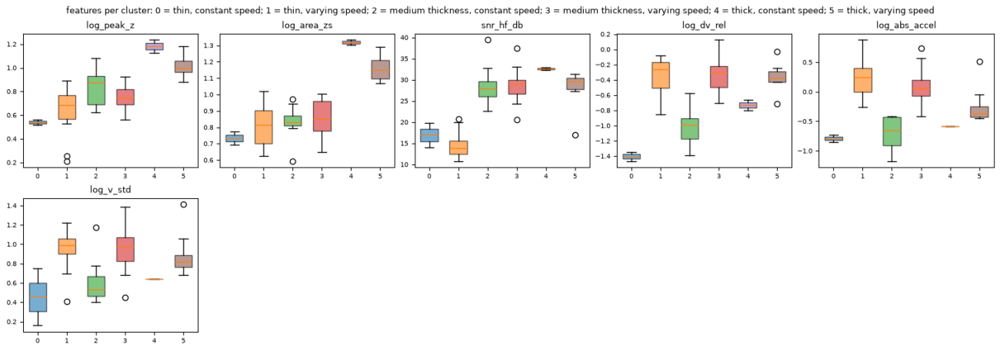

In [45]:
fig("stage10_real_features")

In [46]:
s = read_json("clustering_summary.json")["real"]
table([{"cluster": n, "objects": c} for n, c in zip(s["names"], s["sizes"])], ["cluster", "objects"])

| cluster | objects |
|---|---|
| thin, constant speed | 2 |
| thin, varying speed | 13 |
| medium thickness, constant speed | 8 |
| medium thickness, varying speed | 19 |
| thick, constant speed | 2 |
| thick, varying speed | 8 |

"Shape of the lines": straightened line images (cross-profile along the track) of the objects of
every cluster, and the clusters on the waterfall and in v(t) of `seg_own`:

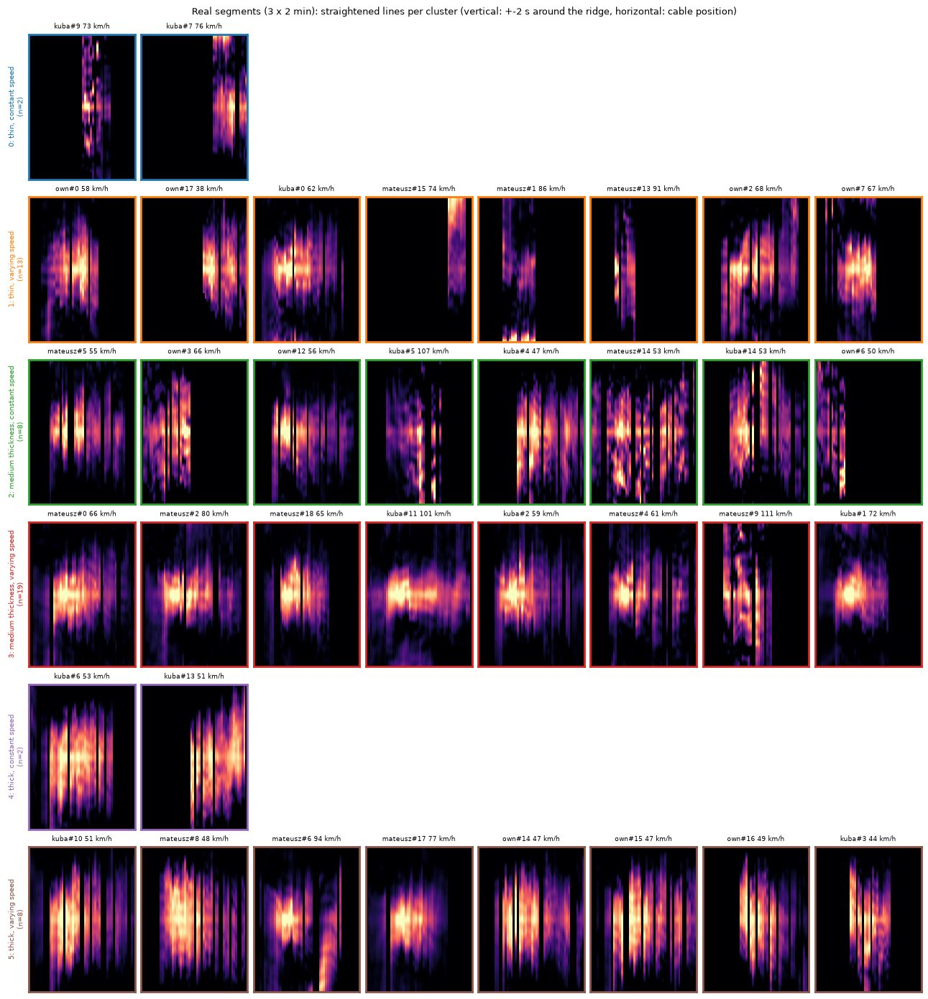

In [47]:
fig("stage10_real_gallery")

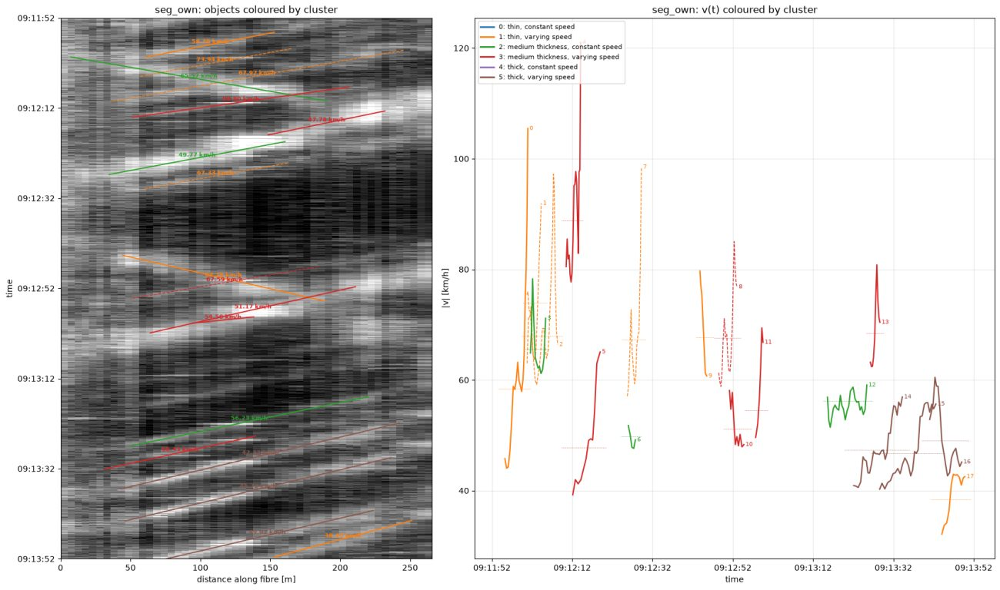

In [48]:
fig("stage10_seg_own_clusters")

**Interpretation and limitation.** On real data the thick clusters have a ≈1.5× wider FWHM and a
higher HF SNR than the thin ones, and the speed level agrees with the Stage-9 class for most
objects. However, compared with our manual thick / thin labels (section 12), the k-means
thickness level does not reproduce them (ARI ≈ 0): single features do separate the labels
(AUC z_hf 0.86, peak z 0.83, FWHM 0.75), but HF SNR - the best feature on synthetic data - is
almost uninformative on real data (AUC 0.59; real cars are as loud in HF as trams). The clusters
therefore describe the **signal** (loud / quiet, constant / varying speed), not the vehicle type.
We did not re-tune the feature set on 39 indicative labels, which would fit the reference itself.

## 11. Detailed results for the three 2-minute segments

The whole method is one call, `pipeline.run_segment`, used by `scripts/run_pipeline.py --segment
all` (which also clusters the objects of the run and writes the figures and tables shown below).
**The cell runs the complete pipeline live on `seg_kuba`** (Stages 4 → 10) and compares the
result with the saved table:

In [49]:
import time

from das import io as dio
from das.config import PipelineParams
from das.pipeline import STAGE_TIMERS, run_segment
from das.velocity import reported_velocity_kmh

seg = dio.load_named_segment("seg_kuba", pad_files=1)       # 12 files + 1 file padding each side
t = time.perf_counter()
res = run_segment(seg, PipelineParams())
print(f"raw matrix {seg.data.shape}, image {res.pre.images['hf'].shape} rows x channels, "
      f"pipeline {time.perf_counter() - t:.1f} s")
print("timings [s]:", {k.removesuffix('_s'): round(res.timings[k], 2) for k in STAGE_TIMERS})
print("counts:", res.counts)
saved = read_csv("pipeline_seg_kuba_objects.csv")
same = len(saved) == len(res.objects) and all(
    abs(float(r["velocity_kmh"]) - reported_velocity_kmh(o)) < 0.01 for r, o in zip(saved, res.objects))
print(f"identical to the saved result of run_pipeline.py: {same}")

raw matrix (87500, 52), image (3000, 52) rows x channels, pipeline 5.5 s
timings [s]: {'preprocess': 0.52, 'enhance': 3.26, 'detect': 1.38, 'group': 0.01, 'track': 0.04, 'features': 0.27}
counts: {'n_objects': 15, 'strong_pos': 2, 'strong_neg': 11, 'weak_pos': 2, 'weak_neg': 0, 'speed_constant': 10, 'speed_varying': 5}
identical to the saved result of run_pipeline.py: True


**Number of objects per segment** - strong (path 6A) and weak (path 6B) objects per direction of
motion, speed classes, and the processing time of each stage. "strong / weak" is the detection
path; the thick / thin *character* of the line is given by the clusters.

In [50]:
summ = [r for r in read_csv("pipeline_summary.csv") if r["kind"] == "segment"]
table(summ, ["name", "start", "n_objects", "strong_pos", "strong_neg", "weak_pos", "weak_neg",
             "speed_constant", "speed_varying"],
      ["segment", "start", "objects", "strong v>0", "strong v<0", "weak v>0", "weak v<0",
       "constant speed", "varying speed"])
table(summ, ["name", "preprocess_s", "enhance_s", "detect_s", "group_s", "track_s", "features_s",
             "total_s", "realtime_factor"],
      ["segment", "preprocess", "enhance", "detect", "group", "track", "features", "total [s]",
       "real-time factor"], nd=2)

| segment | start | objects | strong v>0 | strong v<0 | weak v>0 | weak v<0 | constant speed | varying speed |
|---|---|---|---|---|---|---|---|---|
| seg_kuba | 09:04:52 | 15 | 2 | 11 | 2 | 0 | 10 | 5 |
| seg_mateusz | 09:32:22 | 19 | 4 | 13 | 0 | 2 | 8 | 9 |
| seg_own | 09:11:52 | 18 | 2 | 12 | 0 | 4 | 10 | 8 |

| segment | preprocess | enhance | detect | group | track | features | total [s] | real-time factor |
|---|---|---|---|---|---|---|---|---|
| seg_kuba | 0.56 | 4.06 | 1.22 | 0.01 | 0.04 | 0.20 | 6.09 | 19.71 |
| seg_mateusz | 0.73 | 3.84 | 0.85 | 0.01 | 0.05 | 0.18 | 5.67 | 21.18 |
| seg_own | 0.81 | 4.53 | 0.76 | 0.01 | 0.04 | 0.16 | 6.31 | 19.02 |

For every segment: the raw waterfall, the result (left: velocities on the raw waterfall as in
the brief; right: measured tracks coloured by cluster), v(t) of all objects, and the object
table (velocity = track fit; R²; speed class with start / end speed and acceleration; clock time
of the passage of the cable middle; extent; cluster).

### 11.1 `seg_kuba`

Assigned segment of Kuba, 09:04:52-09:06:52 (it overlaps the example figure of the brief, 09:05:32-09:07:12).

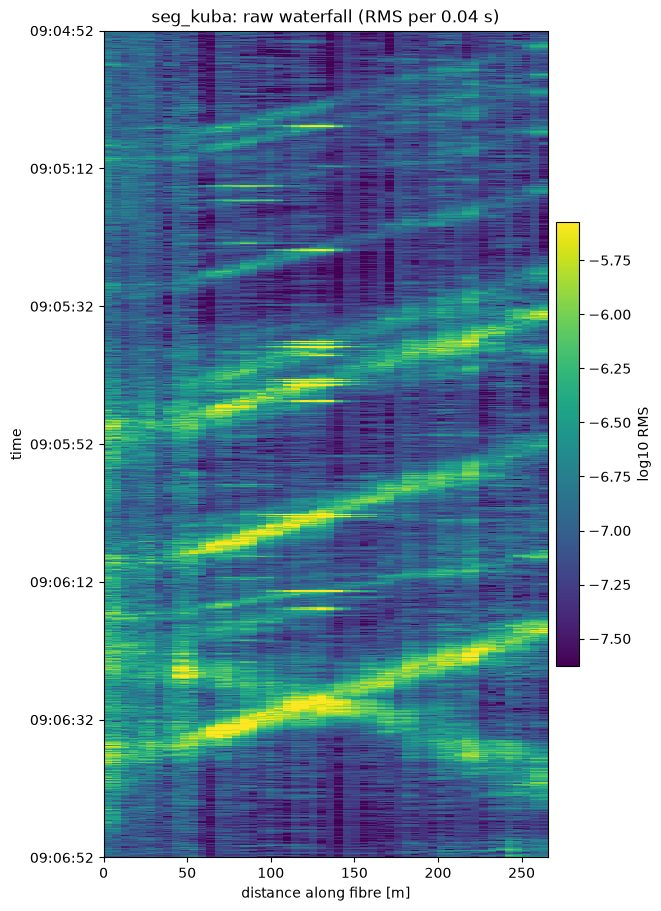

In [51]:
fig("result_seg_kuba_raw", width=520)

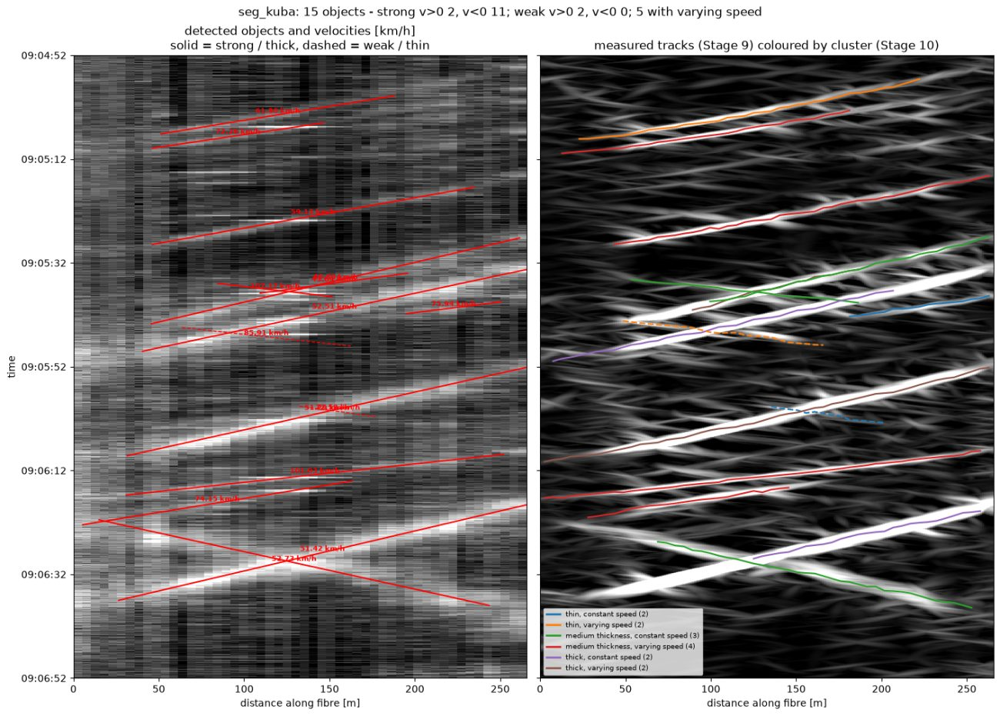

In [52]:
fig("result_seg_kuba_result")

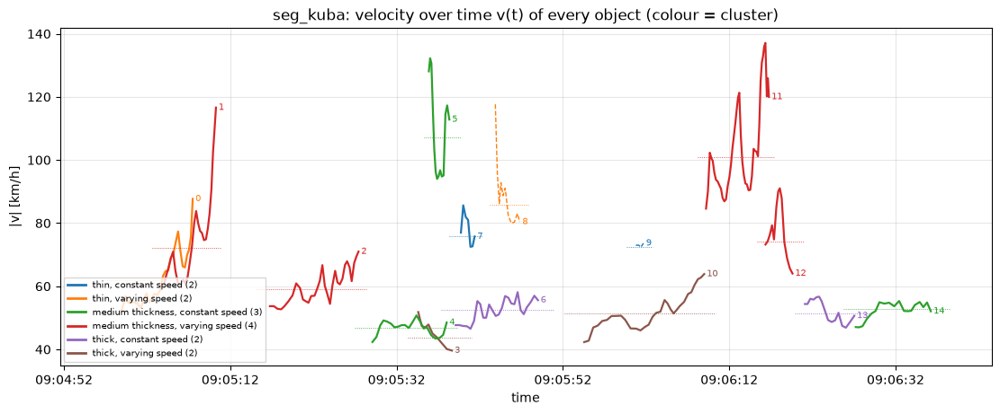

In [53]:
fig("result_seg_kuba_velocity")

In [54]:
rows = read_csv("pipeline_seg_kuba_objects.csv")
table(rows, ["id", "kind", "direction", "velocity_kmh", "r2", "speed_class", "v_start_kmh", "v_end_kmh",
             "accel_ms2", "t_ref_clock", "x_start_m", "x_end_m", "cluster"],
      ["id", "path", "dir", "v [km/h]", "R²", "speed", "v start", "v end", "a [m/s²]", "time (mid-cable)",
       "x start [m]", "x end [m]", "cluster"], nd=2)

| id | path | dir | v [km/h] | R² | speed | v start | v end | a [m/s²] | time (mid-cable) | x start [m] | x end [m] | cluster |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | strong | -1 | -61.80 | 0.99 | varying | -42.58 | -77.12 | 0.83 | 09:05:02.77 | 188.00 | 51.40 | thin, varying speed |
| 1 | strong | -1 | -72.26 | 0.99 | varying | -47.24 | -94.57 | 1.59 | 09:05:05.69 | 146.50 | 46.30 | medium thickness, varying speed |
| 2 | strong | -1 | -59.13 | 1.00 | constant | -50.98 | -66.88 | 0.33 | 09:05:23.38 | 234.60 | 46.30 | medium thickness, varying speed |
| 3 | strong | -1 | -43.64 | 0.99 | varying | -55.50 | -31.49 | -0.86 | 09:05:36.79 | 195.60 | 109.50 | thick, varying speed |
| 4 | strong | -1 | -46.80 | 1.00 | constant | -44.88 | -48.52 | 0.08 | 09:05:37.05 | 261.40 | 45.60 | medium thickness, constant speed |
| 5 | strong | 1 | 107.12 | 0.99 | constant | 109.52 | 104.38 | -0.32 | 09:05:37.79 | 84.60 | 151.60 | medium thickness, constant speed |
| 6 | strong | -1 | -52.51 | 1.00 | constant | -47.42 | -57.79 | 0.21 | 09:05:42.56 | 265.20 | 40.50 | thick, constant speed |
| 7 | strong | -1 | -75.94 | 0.99 | constant | -76.94 | -75.01 | -0.14 | 09:05:44.35 | 250.50 | 195.00 | thin, constant speed |
| 8 | weak | 1 | 85.91 | 0.99 | constant | 105.38 | 67.71 | -2.25 | 09:05:46.94 | 63.50 | 162.50 | thin, varying speed |
| 9 | weak | 1 | 72.58 | 0.98 | constant | 73.13 | 72.09 | -0.09 | 09:05:59.63 | 132.40 | 177.10 | thin, constant speed |
| 10 | strong | -1 | -51.29 | 1.00 | varying | -40.86 | -60.95 | 0.31 | 09:06:01.78 | 265.20 | 31.60 | thick, varying speed |
| 11 | strong | -1 | -101.03 | 1.00 | varying | -82.28 | -118.13 | 1.09 | 09:06:13.11 | 251.80 | 31.00 | medium thickness, varying speed |
| 12 | strong | -1 | -74.15 | 0.99 | constant | -85.05 | -63.21 | -1.06 | 09:06:15.65 | 163.10 | 5.40 | medium thickness, varying speed |
| 13 | strong | -1 | -51.42 | 1.00 | constant | -54.84 | -47.78 | -0.21 | 09:06:28.82 | 265.20 | 26.50 | thick, constant speed |
| 14 | strong | 1 | 52.73 | 1.00 | constant | 50.23 | 55.46 | 0.11 | 09:06:30.00 | 15.00 | 243.50 | medium thickness, constant speed |

### 11.2 `seg_mateusz`

Assigned segment of Mateusz, 09:32:22-09:34:22.

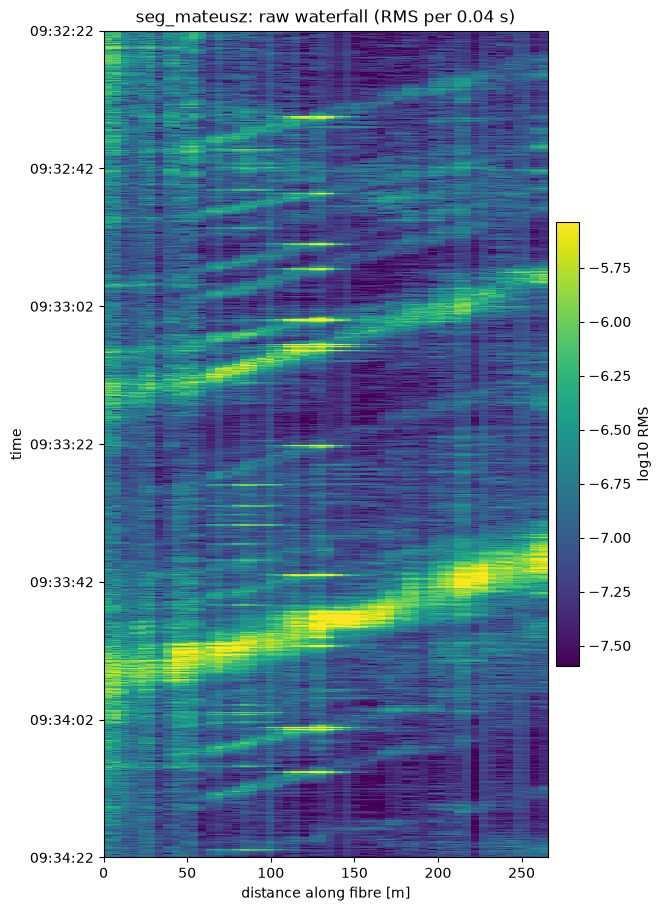

In [55]:
fig("result_seg_mateusz_raw", width=520)

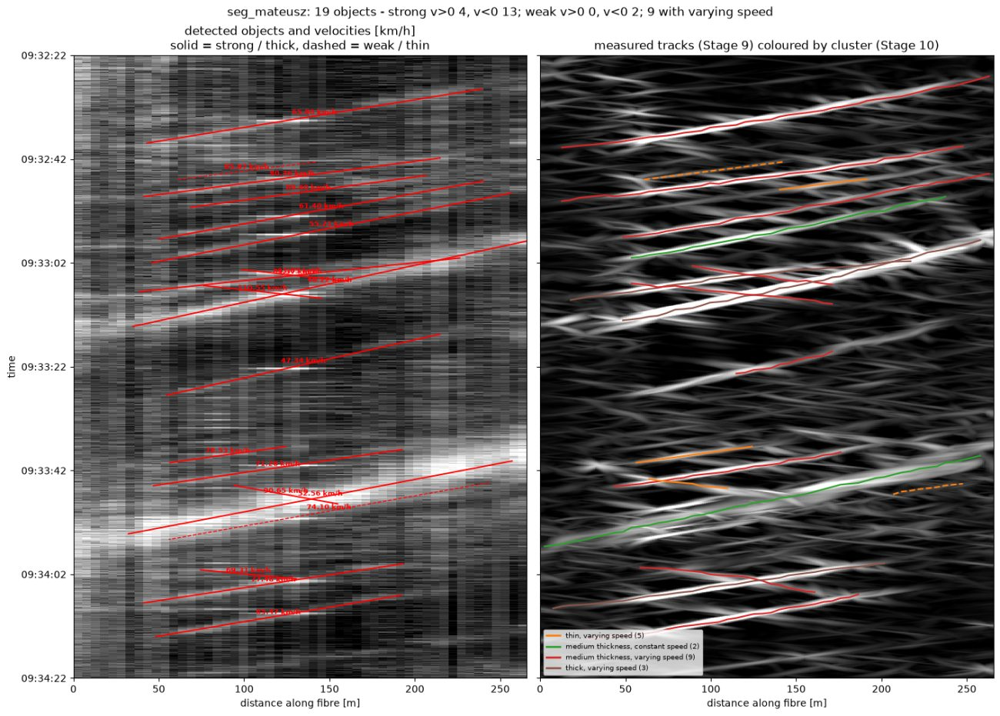

In [56]:
fig("result_seg_mateusz_result")

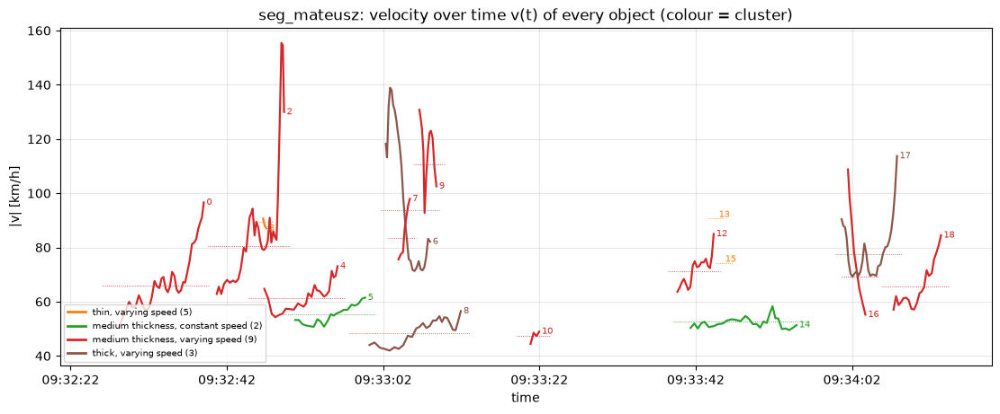

In [57]:
fig("result_seg_mateusz_velocity")

In [58]:
rows = read_csv("pipeline_seg_mateusz_objects.csv")
table(rows, ["id", "kind", "direction", "velocity_kmh", "r2", "speed_class", "v_start_kmh", "v_end_kmh",
             "accel_ms2", "t_ref_clock", "x_start_m", "x_end_m", "cluster"],
      ["id", "path", "dir", "v [km/h]", "R²", "speed", "v start", "v end", "a [m/s²]", "time (mid-cable)",
       "x start [m]", "x end [m]", "cluster"], nd=2)

| id | path | dir | v [km/h] | R² | speed | v start | v end | a [m/s²] | time (mid-cable) | x start [m] | x end [m] | cluster |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | strong | -1 | -65.80 | 0.99 | varying | -45.05 | -83.47 | 0.78 | 09:32:34.15 | 239.00 | 43.10 | medium thickness, varying speed |
| 1 | weak | -1 | -85.87 | - | - | - | - | - | 09:32:42.93 | 142.00 | 61.00 | thin, varying speed |
| 2 | strong | -1 | -80.36 | 0.99 | varying | -54.99 | -105.04 | 1.32 | 09:32:45.30 | 214.80 | 41.20 | medium thickness, varying speed |
| 3 | strong | -1 | -89.60 | 1.00 | varying | -99.00 | -80.05 | -2.63 | 09:32:48.44 | 206.50 | 68.60 | thin, varying speed |
| 4 | strong | -1 | -61.40 | 1.00 | constant | -53.20 | -68.55 | 0.35 | 09:32:52.54 | 240.30 | 50.10 | medium thickness, varying speed |
| 5 | strong | -1 | -55.21 | 1.00 | varying | -48.24 | -61.96 | 0.32 | 09:32:56.43 | 256.30 | 46.00 | medium thickness, constant speed |
| 6 | strong | -1 | -93.65 | 0.98 | varying | -134.40 | -48.80 | -3.19 | 09:33:04.29 | 226.30 | 38.60 | thick, varying speed |
| 7 | strong | 1 | 83.37 | 0.98 | constant | 58.87 | 105.43 | 3.62 | 09:33:04.52 | 98.60 | 161.20 | medium thickness, varying speed |
| 8 | strong | -1 | -48.22 | 1.00 | varying | -39.20 | -56.33 | 0.31 | 09:33:07.26 | 265.20 | 34.80 | thick, varying speed |
| 9 | strong | 1 | 110.55 | 0.98 | constant | 130.97 | 89.15 | -2.96 | 09:33:08.35 | 76.30 | 145.20 | medium thickness, varying speed |
| 10 | strong | -1 | -47.34 | 0.99 | constant | -35.44 | -58.01 | 1.46 | 09:33:21.75 | 214.80 | 54.60 | medium thickness, varying speed |
| 11 | strong | -1 | -78.53 | - | - | - | - | - | 09:33:36.99 | 124.20 | 56.50 | thin, varying speed |
| 12 | strong | -1 | -71.28 | 1.00 | constant | -58.84 | -82.76 | 1.00 | 09:33:40.82 | 192.50 | 46.90 | medium thickness, varying speed |
| 13 | strong | 1 | 90.65 | 0.98 | constant | 96.26 | 85.42 | -1.71 | 09:33:47.13 | 94.20 | 154.80 | thin, varying speed |
| 14 | strong | -1 | -52.56 | 1.00 | constant | -52.01 | -53.09 | 0.02 | 09:33:47.92 | 256.90 | 32.20 | medium thickness, constant speed |
| 15 | weak | -1 | -74.10 | 0.98 | varying | -100.27 | -45.10 | -7.54 | 09:33:50.80 | 243.50 | 55.90 | thin, varying speed |
| 16 | strong | 1 | 69.31 | 0.96 | varying | 114.29 | 23.00 | -5.37 | 09:34:02.93 | 74.40 | 130.50 | medium thickness, varying speed |
| 17 | strong | -1 | -77.48 | 1.00 | constant | -70.77 | -84.18 | 0.43 | 09:34:02.95 | 193.10 | 41.20 | thick, varying speed |
| 18 | strong | -1 | -65.47 | 0.99 | varying | -45.43 | -83.75 | 1.24 | 09:34:09.30 | 191.80 | 48.20 | medium thickness, varying speed |

### 11.3 `seg_own`

Our own segment, 09:11:52-09:13:52: the most active admissible window, traffic in both directions with crossing lines.

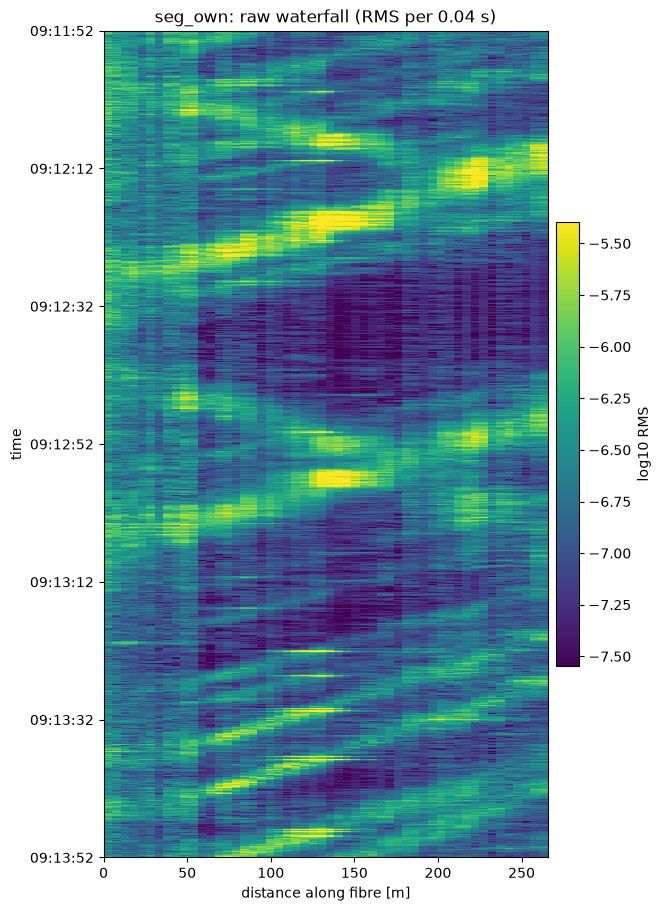

In [59]:
fig("result_seg_own_raw", width=520)

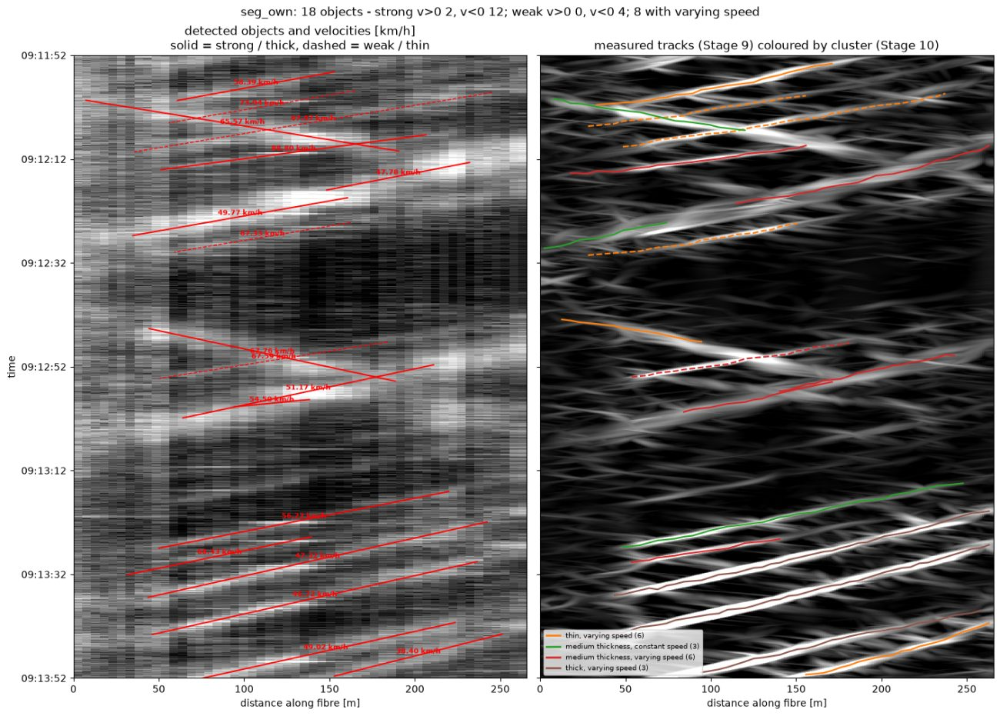

In [60]:
fig("result_seg_own_result")

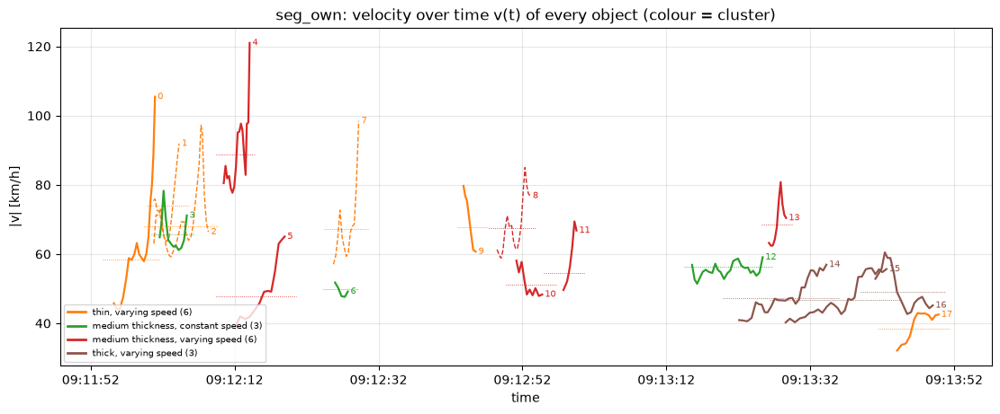

In [61]:
fig("result_seg_own_velocity")

In [62]:
rows = read_csv("pipeline_seg_own_objects.csv")
table(rows, ["id", "kind", "direction", "velocity_kmh", "r2", "speed_class", "v_start_kmh", "v_end_kmh",
             "accel_ms2", "t_ref_clock", "x_start_m", "x_end_m", "cluster"],
      ["id", "path", "dir", "v [km/h]", "R²", "speed", "v start", "v end", "a [m/s²]", "time (mid-cable)",
       "x start [m]", "x end [m]", "cluster"], nd=2)

| id | path | dir | v [km/h] | R² | speed | v start | v end | a [m/s²] | time (mid-cable) | x start [m] | x end [m] | cluster |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | strong | -1 | -58.39 | 0.98 | varying | -33.68 | -81.24 | 1.66 | 09:11:56.39 | 152.90 | 61.00 | thin, varying speed |
| 1 | weak | -1 | -73.94 | 0.99 | constant | -62.91 | -86.06 | 1.10 | 09:12:00.65 | 165.10 | 55.80 | thin, varying speed |
| 2 | weak | -1 | -67.97 | 1.00 | constant | -58.57 | -77.13 | 0.50 | 09:12:05.31 | 245.30 | 35.50 | thin, varying speed |
| 3 | strong | 1 | 65.57 | 1.00 | constant | 62.68 | 68.24 | 0.25 | 09:12:07.37 | 7.30 | 190.50 | medium thickness, constant speed |
| 4 | strong | -1 | -88.80 | 0.99 | constant | -65.25 | -110.14 | 2.30 | 09:12:10.52 | 206.50 | 51.40 | medium thickness, varying speed |
| 5 | strong | -1 | -47.78 | 0.98 | varying | -26.99 | -67.48 | 1.01 | 09:12:18.95 | 232.00 | 148.40 | medium thickness, varying speed |
| 6 | strong | -1 | -49.77 | 0.99 | constant | -52.76 | -46.80 | -0.34 | 09:12:21.06 | 160.50 | 34.80 | medium thickness, constant speed |
| 7 | weak | -1 | -67.33 | 0.98 | varying | -42.04 | -93.29 | 2.33 | 09:12:25.85 | 162.40 | 59.00 | thin, varying speed |
| 8 | weak | -1 | -67.59 | 0.99 | constant | -57.46 | -77.62 | 0.85 | 09:12:49.92 | 184.20 | 50.40 | medium thickness, varying speed |
| 9 | strong | 1 | 67.76 | 0.99 | varying | 87.47 | 47.74 | -2.59 | 09:12:50.87 | 44.40 | 188.60 | thin, varying speed |
| 10 | strong | -1 | -51.17 | 0.99 | constant | -58.86 | -43.36 | -0.62 | 09:12:57.09 | 211.00 | 64.20 | medium thickness, varying speed |
| 11 | strong | -1 | -54.50 | 0.99 | constant | -39.08 | -68.61 | 1.42 | 09:12:58.51 | 138.20 | 94.20 | medium thickness, varying speed |
| 12 | strong | -1 | -56.23 | 1.00 | constant | -54.96 | -57.55 | 0.06 | 09:13:21.65 | 219.90 | 50.10 | medium thickness, constant speed |
| 13 | strong | -1 | -68.43 | 0.99 | constant | -62.48 | -74.51 | 0.75 | 09:13:25.22 | 139.50 | 31.60 | medium thickness, varying speed |
| 14 | strong | -1 | -47.32 | 1.00 | varying | -37.55 | -56.98 | 0.33 | 09:13:29.92 | 242.20 | 43.70 | thick, varying speed |
| 15 | strong | -1 | -46.72 | 1.00 | varying | -35.86 | -58.06 | 0.33 | 09:13:37.21 | 236.50 | 46.30 | thick, varying speed |
| 16 | strong | -1 | -49.02 | 1.00 | varying | -57.99 | -40.47 | -0.41 | 09:13:47.87 | 223.70 | 71.80 | thick, varying speed |
| 17 | strong | -1 | -38.40 | 0.99 | varying | -27.84 | -47.99 | 0.56 | 09:13:53.26 | 251.20 | 152.90 | thin, varying speed |

All intermediate steps for `seg_kuba` (the same figures exist for every segment in
`outputs/figures/pipeline/<segment>/`): f-k maps and filter-bank responses per band and
direction, and candidates → groups → objects.

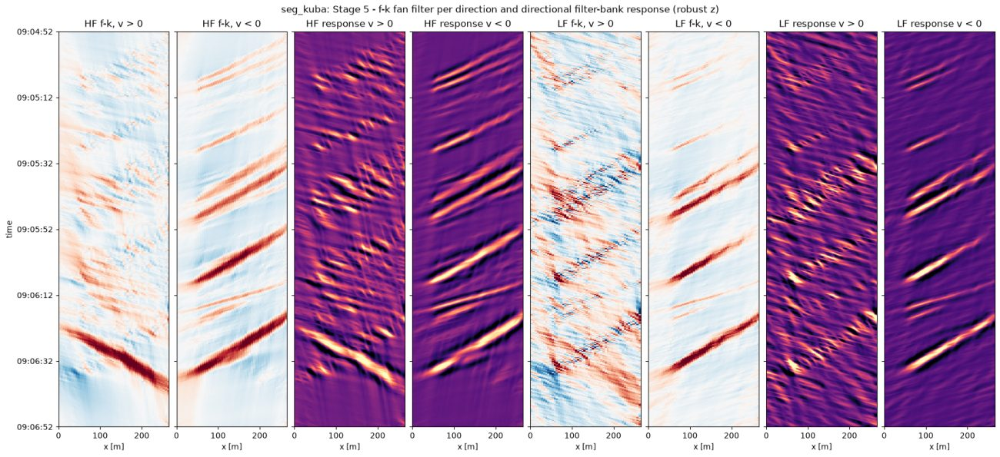

In [63]:
fig("result_seg_kuba_enhancement")

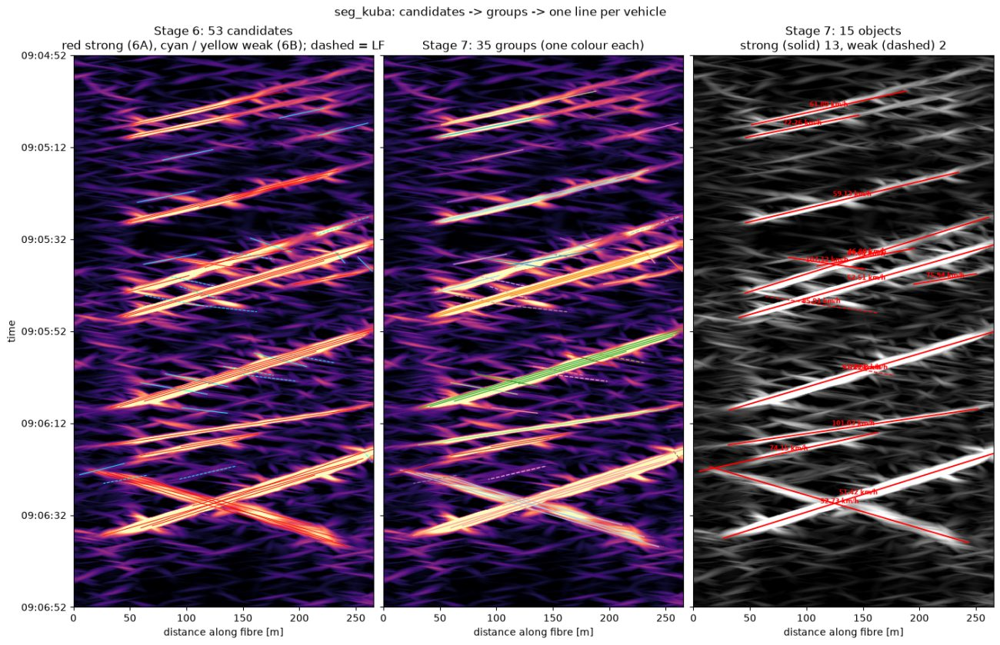

In [64]:
fig("result_seg_kuba_candidates")

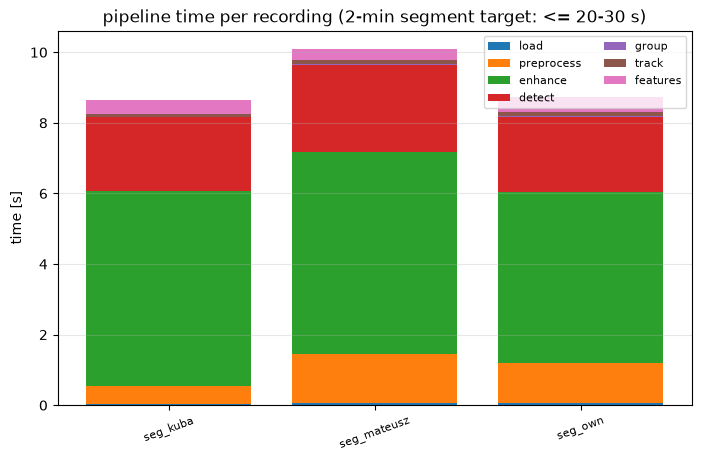

In [65]:
fig("result_timings", width=700)

## 12. Evaluation and experiments

### 12.1 How the detections are scored

The real recordings have no ground truth, so two references are used:

* **synthetic data** (6 samples, 134 vehicles: 49 trams / trucks = *thick*, 85 cars / vans =
  *thin*): reference objects are built from the ground-truth mask (passage time per channel →
  line), and the pipeline runs with dt / dx from the metadata (59 channels - nothing assumes 52);
* **real data**: 52 lines marked by hand on the raw waterfall of the three segments with our
  annotation tool (`scripts/annotate_real.py`, matplotlib GUI, thick / thin label per line).
  This reference is **indicative only** - rough clicks on a much noisier image. Labels outside
  the velocity range the detector searches (4 near-horizontal strokes of 187-3147 km/h) or
  shorter than 30 m (1) are listed but not scored, leaving 47 scored labels (23 thick, 24 thin).

Detections and references are matched **one-to-one** (greedy by distance, same direction, time
gap at the detection centre < 1.5 s, |Δv| < 20 km/h). We report precision / recall / F1, recall
**separately for thick and thin lines**, the error of the reported velocity, and the trajectory
IoU (tracks rasterised one pixel per channel, ±0.5 s). For real data the false positives are
split into "near a label" (fragment / duplicate of a labelled vehicle) and "no label".
The detector was developed on the synthetic data; the real labels were used only as a guard
and a tie-break in Stage 13 (12.4).

### 12.2 Synthetic data (true ground truth)

In [66]:
rows = read_csv("eval_synthetic.csv")
table(rows, ["sample", "n_ref", "n_det", "tp_heavy", "n_ref_heavy", "recall_heavy", "tp_light", "n_ref_light",
             "recall_light", "precision", "f1", "vel_mae", "traj_iou"],
      ["sample", "vehicles", "detections", "thick found", "thick", "recall thick", "thin found", "thin",
       "recall thin", "precision", "F1", "|v| MAE [km/h]", "traj. IoU"])

| sample | vehicles | detections | thick found | thick | recall thick | thin found | thin | recall thin | precision | F1 | \|v\| MAE [km/h] | traj. IoU |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 40 | 22 | 21 | 7 | 7 | 1.000 | 13 | 15 | 0.867 | 0.952 | 0.930 | 0.853 | 0.627 |
| 41 | 18 | 19 | 6 | 6 | 1.000 | 11 | 12 | 0.917 | 0.895 | 0.919 | 2.421 | 0.559 |
| 42 | 20 | 19 | 8 | 8 | 1.000 | 10 | 12 | 0.833 | 0.947 | 0.923 | 1.650 | 0.618 |
| 43 | 24 | 25 | 8 | 8 | 1.000 | 14 | 16 | 0.875 | 0.880 | 0.898 | 2.547 | 0.664 |
| 44 | 30 | 30 | 12 | 12 | 1.000 | 16 | 18 | 0.889 | 0.933 | 0.933 | 2.574 | 0.605 |
| 45 | 20 | 19 | 8 | 8 | 1.000 | 11 | 12 | 0.917 | 1.000 | 0.974 | 0.962 | 0.699 |
| ALL | 134 | 133 | 49 | 49 | 1.000 | 75 | 85 | 0.882 | 0.932 | 0.929 | 1.890 | 0.629 |

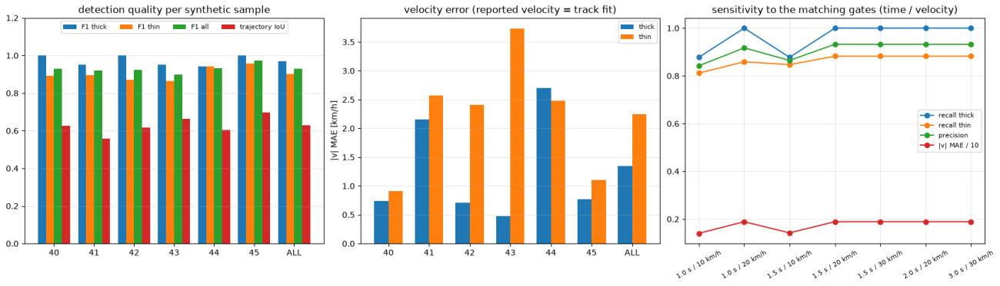

In [67]:
fig("eval_synthetic_summary")

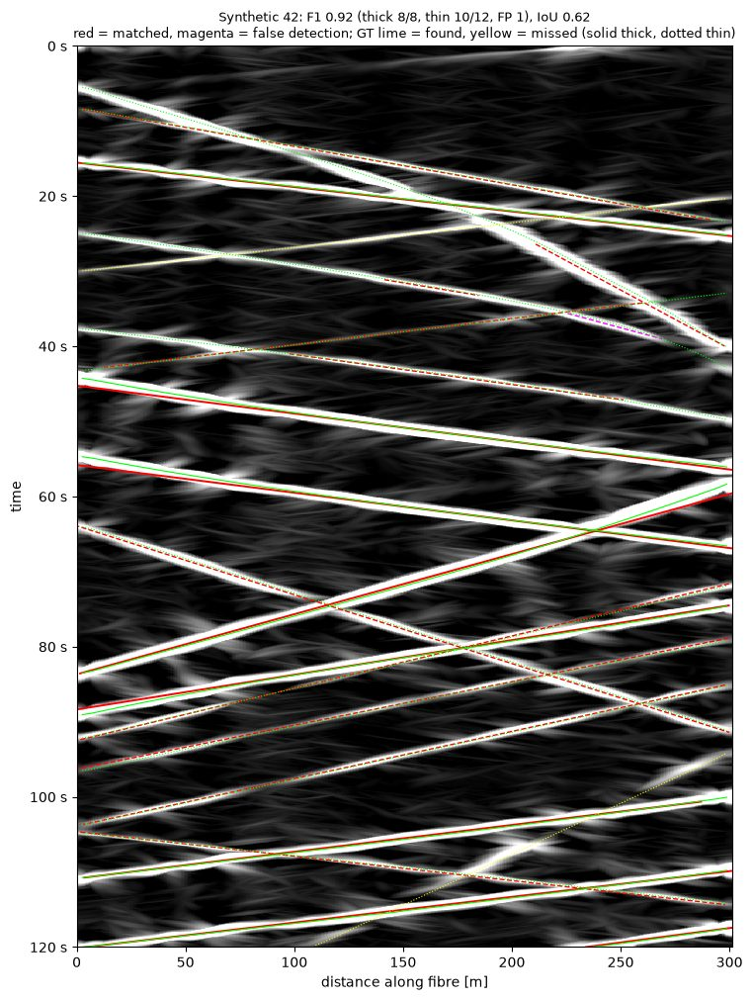

In [68]:
fig("eval_synthetic_42")

**Synthetic result (6 samples, 134 vehicles).** Thick lines: recall **1.000** (49 / 49),
precision 0.94, F1 **0.969**; thin lines: recall **0.882** (75 / 85), precision 0.92, F1
**0.903**; all objects: precision 0.932, recall 0.925, **F1 0.929** (9 false positives, 10
missed cars). The reported velocity differs from the GT velocity by **1.89 km/h** on average
(thick 1.35, thin 2.24; MAPE 3.5 %); trajectory IoU 0.63 (GT tracks span the whole cable,
detections only the detected part). The scores do not change for matching gates from 1.5 s /
20 km/h up to 3 s / 30 km/h; a 10 km/h gate lowers thick recall to 0.88, because the averaged
Stage-7 line of a long, bent tram track can differ by > 10 km/h from the GT mean velocity.

The missed cars are visible for < 5 s at the end of the record, very slow / strongly varying
(≤ 30 km/h) or one at 110 km/h. The remaining false positives are fragments at crossings with a
strong line of the opposite direction, where the f-k direction separation is imperfect.
"strong / weak" is the detection path, not the vehicle type: 15 of the 75 found cars are clear
enough to pass the strong path.

### 12.3 Real segments vs the manual labels

In [69]:
rows = read_csv("eval_real.csv")
table(rows, ["segment", "n_ref", "n_det", "tp_heavy", "n_ref_heavy", "recall_heavy", "tp_light", "n_ref_light",
             "recall_light", "precision", "f1", "fp_near_label", "fp_no_label", "vel_mae"],
      ["segment", "labels", "detections", "thick found", "thick", "recall thick", "thin found", "thin",
       "recall thin", "precision", "F1", "FP near a label", "FP no label", "|v| difference [km/h]"])

| segment | labels | detections | thick found | thick | recall thick | thin found | thin | recall thin | precision | F1 | FP near a label | FP no label | \|v\| difference [km/h] |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| seg_kuba | 13 | 15 | 8 | 8 | 1.000 | 2 | 5 | 0.400 | 0.667 | 0.714 | 4 | 1 | 2.105 |
| seg_mateusz | 15 | 19 | 4 | 4 | 1.000 | 9 | 11 | 0.818 | 0.684 | 0.765 | 4 | 2 | 3.980 |
| seg_own | 19 | 18 | 10 | 11 | 0.909 | 6 | 8 | 0.750 | 0.889 | 0.865 | 2 | 0 | 6.402 |
| ALL | 47 | 52 | 22 | 23 | 0.957 | 17 | 24 | 0.708 | 0.750 | 0.788 | 10 | 3 | 4.493 |
| ALL (all labels) | 52 | 52 | 22 | 23 | 0.957 | 17 | 29 | 0.586 | 0.750 | 0.750 | 10 | 3 | 4.493 |

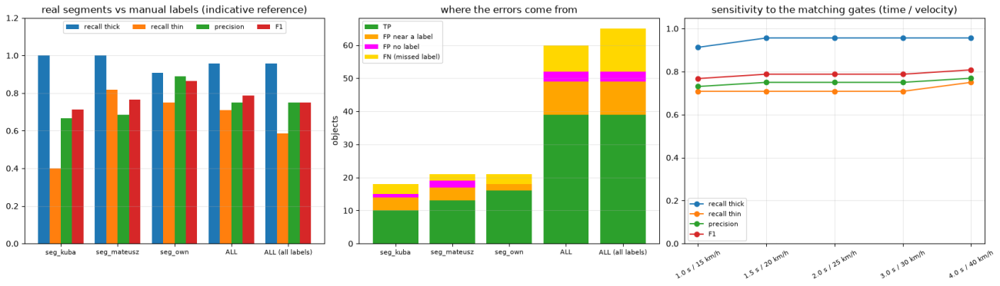

In [70]:
fig("eval_real_summary")

Detections vs labels (red = matched, orange = false positive near a label, magenta = no label; labels lime = found, yellow = missed, solid thick / dotted thin, cyan = not scored):

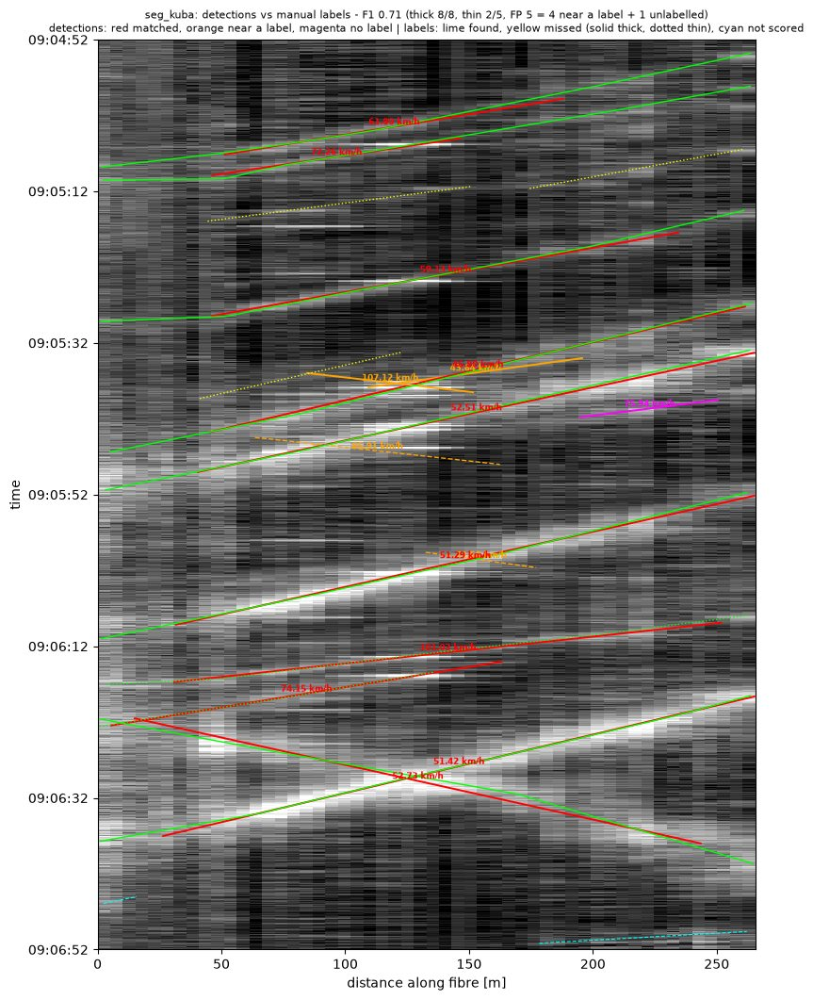

In [71]:
fig("eval_real_seg_kuba", width=620)

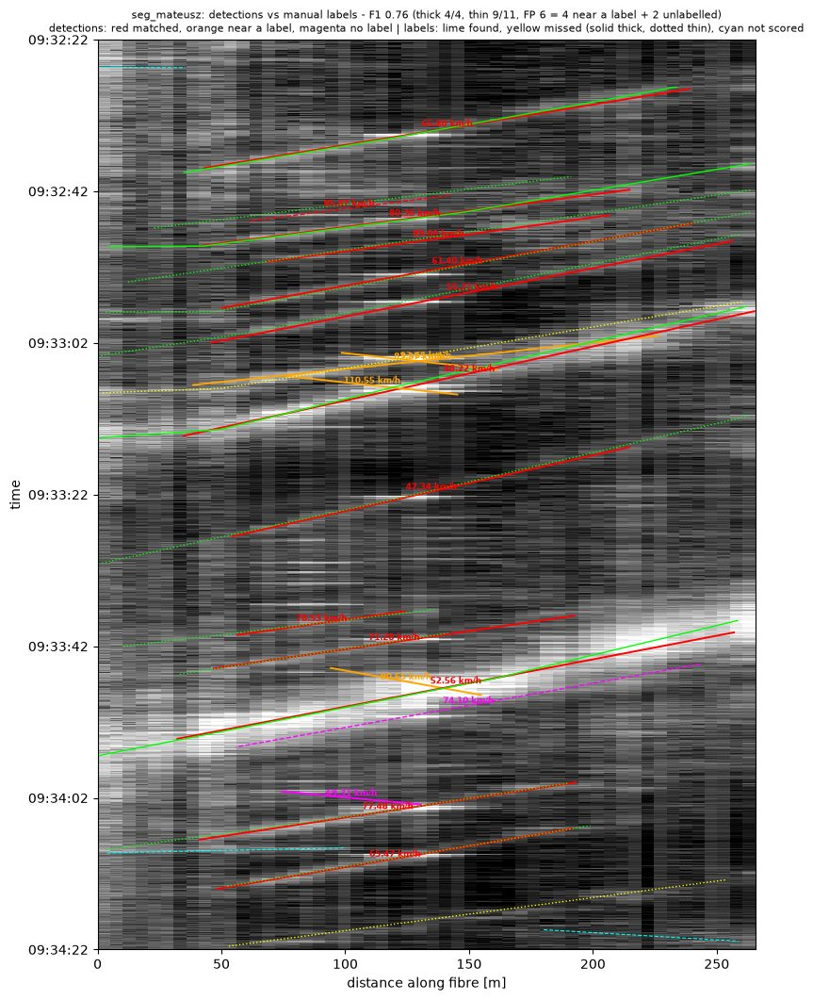

In [72]:
fig("eval_real_seg_mateusz", width=620)

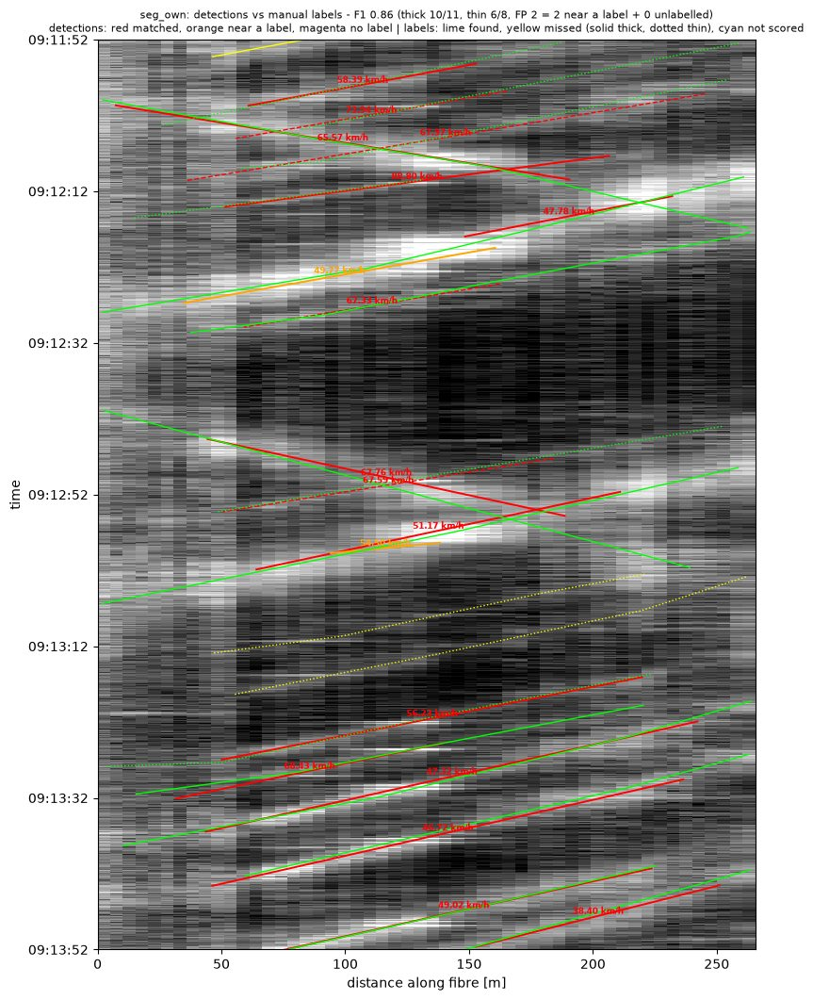

In [73]:
fig("eval_real_seg_own", width=620)

**Real result (47 scored labels, 52 detections).** Thick lines: recall **0.957** (22 / 23); thin
lines: recall **0.708** (17 / 24); all: precision **0.750**, recall **0.830**, **F1 0.788**
(F1 0.750 if the 5 unscored labels are counted as well). Per segment F1: `seg_kuba` 0.71,
`seg_mateusz` 0.76, `seg_own` 0.86. The scores are practically independent of the matching
gates (F1 0.768 at 1 s / 15 km/h, 0.788 from 1.5 s / 20 km/h to 3 s / 30 km/h), i.e. the
inaccuracy of the hand-drawn lines does not drive the result. The velocity of the matched
objects differs from the slope of the drawn line by 4.5 km/h on average (MAPE 7.7 %) - about the
accuracy of a slope clicked by eye.

* **False positives (13): 10 lie on a labelled line** - fragments or duplicates of a strong
  vehicle (the "X" of crossing fragments next to trams) - and only 3 have no label nearby (noise
  or an unlabelled vehicle). Counting only those, the precision would be 39 / 42 = 0.93.
* **Missed labels (8)** are weak, isolated thin lines (2 of them at the segment edge); one thin
  label of `seg_mateusz` was lost in Stage 13 when the larger grouping tolerance merged it with
  a neighbouring object.
* **Thick / thin by detection path** is a poor class on real data: 13 of the 17 matched thin
  labels come from the strong path, because real cars are much louder relative to the
  background than the synthetic ones. The character of an object is described by its features /
  cluster (section 10), not by the path.
* Real data are much harder than the synthetic ones (F1 0.79 vs 0.93): the noise texture of the
  quiet direction, the hotspot, wide diffuse tram lines and many crossings do not exist in the
  simulator - exactly the warning of the brief.

### 12.4 Stage 13: ablation, method comparison, parameter studies

`scripts/tune_parameters.py` runs Stages 4 → 9 for every variant on all 6 synthetic samples and
the 3 labelled real segments (in parallel per recording; results of Stages 4-6 are cached and
reused by all variants with the same upstream parameters) and scores the objects as above.
Each variant changes the final parameters in one place. **Selection rule:** the synthetic F1
(true ground truth) decides; the real-data F1 only breaks ties between settings that are
equivalent on the synthetic data (|ΔF1| < 0.005) and vetoes changes that only fit the simulator.

**Ablation** - one step switched off at a time (detection-level repetition of the pixel-level study of sections 5-6):

In [74]:
COLS = ["variant", "syn_f1", "syn_recall_thick", "syn_recall_thin", "syn_precision", "syn_vel_mae",
        "real_f1", "real_recall_thick", "real_recall_thin", "real_precision", "real_fp_near_label", "time_s"]
HEAD = ["variant", "syn F1", "syn R thick", "syn R thin", "syn P", "syn |v| MAE", "real F1", "real R thick",
        "real R thin", "real P", "real FP near label", "s / recording"]
table(read_csv("tuning_ablation.csv"), COLS, HEAD)

| variant | syn F1 | syn R thick | syn R thin | syn P | syn \|v\| MAE | real F1 | real R thick | real R thin | real P | real FP near label | s / recording |
|---|---|---|---|---|---|---|---|---|---|---|---|
| final parameters | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.679 |
| no common-mode removal | 0.900 | 0.980 | 0.812 | 0.929 | 1.992 | 0.788 | 0.913 | 0.750 | 0.750 | 9 | 35.506 |
| no log compression (linear ratio) | 0.817 | 0.980 | 0.647 | 0.873 | 2.288 | 0.504 | 0.870 | 0.417 | 0.417 | 28 | 35.717 |
| no f-k fan filter | 0.893 | 1.000 | 0.800 | 0.914 | 1.705 | 0.557 | 0.826 | 0.333 | 0.540 | 17 | 25.084 |
| no directional filter bank | 0.859 | 0.980 | 0.765 | 0.876 | 1.668 | 0.708 | 1.000 | 0.458 | 0.694 | 9 | 10.411 |
| no masking of strong lines | 0.899 | 0.980 | 0.800 | 0.935 | 1.686 | 0.780 | 0.957 | 0.708 | 0.736 | 12 | 28.871 |
| no hysteresis (single 4 sigma threshold) | 0.903 | 0.980 | 0.812 | 0.936 | 1.370 | 0.783 | 0.913 | 0.625 | 0.800 | 7 | 30.615 |
| no LF band in the weak path | 0.740 | 1.000 | 0.412 | 0.903 | 1.859 | 0.809 | 0.957 | 0.667 | 0.809 | 7 | 28.126 |
| no weak path (strong lines only) | 0.621 | 0.980 | 0.176 | 0.913 | 1.645 | 0.756 | 0.913 | 0.542 | 0.791 | 7 | 26.030 |
| no ridge tracking (line velocity) | 0.929 | 1.000 | 0.882 | 0.932 | 2.893 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.491 |
| no edge margin in tracking | 0.929 | 1.000 | 0.882 | 0.932 | 1.856 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.675 |

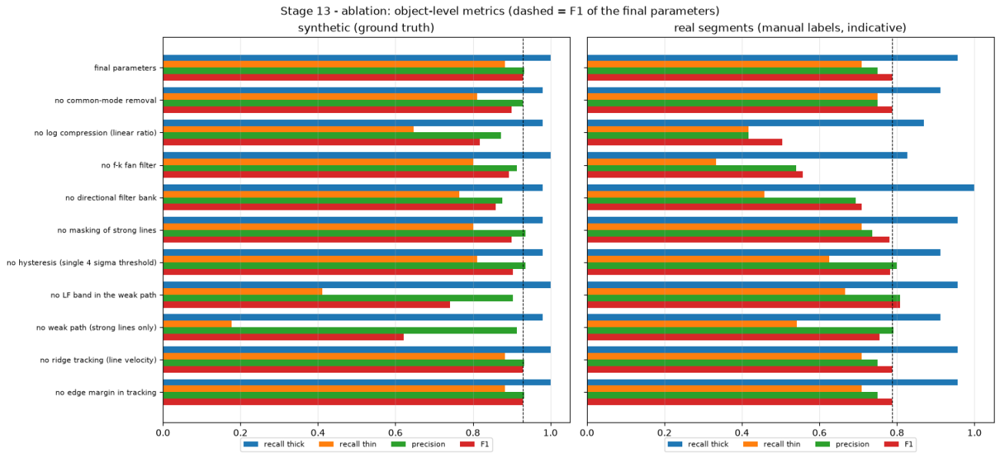

In [75]:
fig("tuning_ablation")

**What each step is responsible for** (changes against the final F1 0.929 synthetic / 0.788 real):

* **log compression** is the most important pre-processing step: without it thin recall drops to
  0.65 (synthetic) and 0.42 (real), F1 to 0.82 / 0.50 - trams dominate the linear image;
* **f-k fan filter**: synthetic F1 0.89, real F1 0.56 (real thin recall 0.33) - on real data the
  horizontal hotspot dashes and stripes produce false lines and hide weak ones;
* **directional filter bank**: synthetic thin recall 0.77, precision 0.88; it is also ≈70 % of the
  run time (without it 10 s instead of 30 s per recording in the parallel tuning run);
* **weak path**: without it (thick lines only - the grade 3/4 solution) thin recall is **0.18**
  on synthetic data. Its **LF band** is what finds thin lines in the simulator (HF-only weak
  path: thin recall 0.41). On real data the LF band adds some false positives (real F1 0.81
  without it), but removing it would lose half of the synthetic cars, so it stays;
* **masking of strong lines** and **hysteresis** each add 2-3 synthetic points of F1 (thin
  recall 0.80 / 0.81 without them); common-mode removal adds 3 points (thin recall 0.81 without);
* **ridge tracking** does not change the detections but lowers the velocity error from 2.89 to
  1.89 km/h; the edge margin changes nothing in these recordings (it only acts on vehicles cut by
  the window end, e.g. the ad-hoc window 09:20:02).

**Method comparison** - alternatives of single steps and two classical baselines:

In [76]:
table(read_csv("tuning_methods.csv"), COLS, HEAD)

| variant | syn F1 | syn R thick | syn R thin | syn P | syn \|v\| MAE | real F1 | real R thick | real R thin | real P | real FP near label | s / recording |
|---|---|---|---|---|---|---|---|---|---|---|---|
| final parameters | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.679 |
| Hough: HoughLinesP only | 0.887 | 1.000 | 0.765 | 0.927 | 1.921 | 0.768 | 0.957 | 0.667 | 0.731 | 11 | 28.931 |
| Hough: global hough_line only | 0.902 | 0.980 | 0.788 | 0.950 | 1.716 | 0.809 | 0.957 | 0.667 | 0.809 | 7 | 29.287 |
| enhancer: Sato | 0.663 | 0.898 | 0.871 | 0.532 | 2.105 | 0.337 | 0.652 | 0.667 | 0.226 | 64 | 56.426 |
| enhancer: Meijering | 0.580 | 0.837 | 0.824 | 0.446 | 1.593 | 0.217 | 0.565 | 0.417 | 0.139 | 93 | 62.484 |
| enhancer: Gabor | 0.476 | 0.653 | 0.600 | 0.386 | 1.612 | 0.257 | 0.565 | 0.375 | 0.177 | 64 | 37.042 |
| envelope: mean \|x\| | 0.893 | 0.980 | 0.812 | 0.914 | 1.842 | 0.755 | 0.913 | 0.667 | 0.725 | 10 | 22.853 |
| envelope: plain decimation | 0.874 | 0.980 | 0.776 | 0.898 | 1.949 | 0.740 | 0.957 | 0.625 | 0.698 | 11 | 21.233 |
| normalisation: robust z | 0.935 | 0.959 | 0.894 | 0.953 | 1.808 | 0.772 | 0.957 | 0.708 | 0.722 | 9 | 38.690 |
| f-k padding: reflect | 0.914 | 0.980 | 0.812 | 0.959 | 1.769 | 0.760 | 0.957 | 0.667 | 0.717 | 8 | 25.831 |
| f-k padding: Tukey taper | 0.903 | 0.980 | 0.812 | 0.936 | 2.205 | 0.661 | 0.913 | 0.667 | 0.569 | 17 | 25.430 |
| f-k padding: none (circular) | 0.908 | 0.980 | 0.835 | 0.930 | 1.922 | 0.742 | 0.870 | 0.667 | 0.720 | 9 | 24.760 |
| strong threshold: fixed 6 sigma | 0.906 | 0.980 | 0.859 | 0.910 | 1.776 | 0.739 | 0.783 | 0.667 | 0.756 | 9 | 28.698 |
| baseline: Canny + HoughLinesP, raw image | 0.591 | 0.735 | 0.282 | 0.870 | 4.676 | nan | 0.000 | 0.000 | 0.000 | 7 | 25.363 |
| baseline: Canny + HoughLinesP, preprocessed HF | 0.040 | 0.000 | 0.035 | 0.200 | 17.083 | 0.171 | 0.174 | 0.208 | 0.155 | 28 | 27.412 |

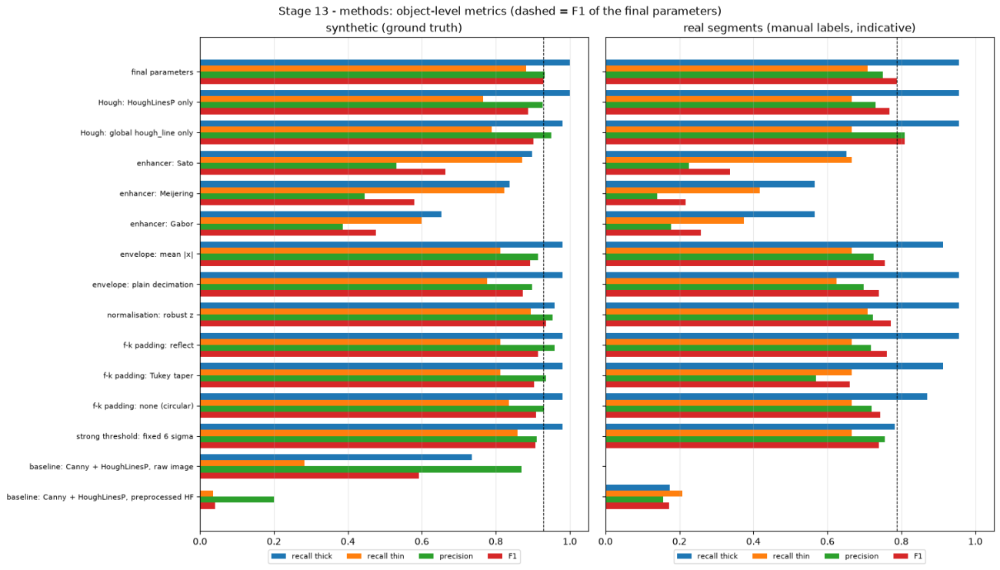

In [77]:
fig("tuning_methods")

* **Hough:** HoughLinesP alone 0.887, global `hough_line` alone 0.902, both 0.929 (synthetic F1)
  - they find different lines, as in Stage 6.
* **Enhancer at the object level:** Sato, Meijering and Gabor give far more false positives
  (precision 0.39-0.53 synthetic, 0.14-0.23 real). Their response distribution differs from the
  matched bank (the thresholds in σ were chosen for the bank), but already the pixel-level AUC
  of section 6 was lower; the matched filter bank is kept.
* **Envelope:** RMS > mean |x| > plain decimation (0.929 / 0.893 / 0.874).
* **Normalisation:** a robust z-score is equal on synthetic F1 (0.935) but loses 2 of the 49
  trams (thick recall 0.959) and is worse on real data (0.772) - rejected.
* **f-k padding:** zero 0.929, reflect 0.914, none (circular FFT) 0.908, Tukey taper 0.903 /
  real 0.661 - zero padding is kept. Without padding the circular FFT wraps the cable ends
  together (the "f-k without padding" failure mode).
* **Strong threshold:** a fixed 6 σ instead of Otsu with a 4 σ floor loses real thick lines
  (real thick recall 0.78).
* **Classical baseline - Canny + HoughLinesP** with the same Hough settings and the same velocity
  fan: on the raw log-RMS image synthetic F1 0.59 (thin recall 0.28) and **no correct detection
  on the real segments**; on the pre-processed HF image it is even worse (synthetic F1 0.04),
  because the edges of the noisy energy image are everywhere. Edge detection is the wrong tool
  for wide, noisy ridges - a matched filter on the energy image is needed.

**One-at-a-time sweep** of the key parameters around the final values:

In [78]:
table(read_csv("tuning_sweep.csv"), COLS, HEAD)

| variant | syn F1 | syn R thick | syn R thin | syn P | syn \|v\| MAE | real F1 | real R thick | real R thin | real P | real FP near label | s / recording |
|---|---|---|---|---|---|---|---|---|---|---|---|
| final parameters | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.679 |
| hf_low = 30.0 | 0.917 | 0.959 | 0.882 | 0.924 | 1.675 | 0.733 | 0.826 | 0.750 | 0.685 | 12 | 25.296 |
| hf_low = 100.0 | 0.891 | 0.980 | 0.824 | 0.901 | 1.986 | 0.685 | 0.913 | 0.667 | 0.607 | 20 | 23.852 |
| lf_low = 0.5, lf_high = 5.0 | 0.872 | 1.000 | 0.741 | 0.911 | 1.834 | 0.768 | 0.957 | 0.667 | 0.731 | 11 | 21.832 |
| lf_low = 2.0, lf_high = 12.0 | 0.900 | 1.000 | 0.859 | 0.891 | 1.724 | 0.743 | 0.957 | 0.708 | 0.672 | 14 | 27.788 |
| time_decimation = 10 | 0.897 | 0.959 | 0.835 | 0.915 | 1.854 | 0.678 | 0.957 | 0.750 | 0.563 | 19 | 50.049 |
| time_decimation = 50 | 0.891 | 0.959 | 0.788 | 0.934 | 1.664 | 0.743 | 0.957 | 0.708 | 0.672 | 13 | 21.731 |
| kernel_length_px = 41 | 0.895 | 0.980 | 0.788 | 0.935 | 2.116 | 0.706 | 0.739 | 0.542 | 0.789 | 5 | 22.082 |
| kernel_length_px = 121 | 0.876 | 0.980 | 0.765 | 0.911 | 2.029 | 0.710 | 0.913 | 0.708 | 0.633 | 17 | 26.252 |
| n_angles = 12 | 0.905 | 1.000 | 0.824 | 0.922 | 1.884 | 0.743 | 0.957 | 0.708 | 0.672 | 13 | 18.374 |
| n_angles = 36 | 0.917 | 1.000 | 0.847 | 0.931 | 1.837 | 0.792 | 0.957 | 0.750 | 0.741 | 10 | 43.145 |
| space_upsample = 4 | 0.903 | 0.959 | 0.812 | 0.943 | 1.897 | 0.755 | 0.957 | 0.750 | 0.678 | 14 | 14.721 |
| strong_min_sigma = 3.0 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.656 | 1.000 | 0.708 | 0.533 | 28 | 28.925 |
| strong_min_sigma = 5.0 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.817 | 0.913 | 0.708 | 0.826 | 6 | 30.394 |
| strong_min_sigma = 6.0 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.739 | 0.783 | 0.667 | 0.756 | 9 | 30.293 |
| min_extent_m = 30.0 | 0.925 | 1.000 | 0.882 | 0.925 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 28.684 |
| min_extent_m = 60.0 | 0.917 | 1.000 | 0.847 | 0.931 | 1.906 | 0.837 | 0.957 | 0.792 | 0.804 | 7 | 30.661 |
| weak_min_support_m = 40.0 | 0.919 | 1.000 | 0.894 | 0.906 | 1.884 | 0.695 | 0.957 | 0.792 | 0.577 | 19 | 29.695 |
| weak_min_support_m = 80.0 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.682 |

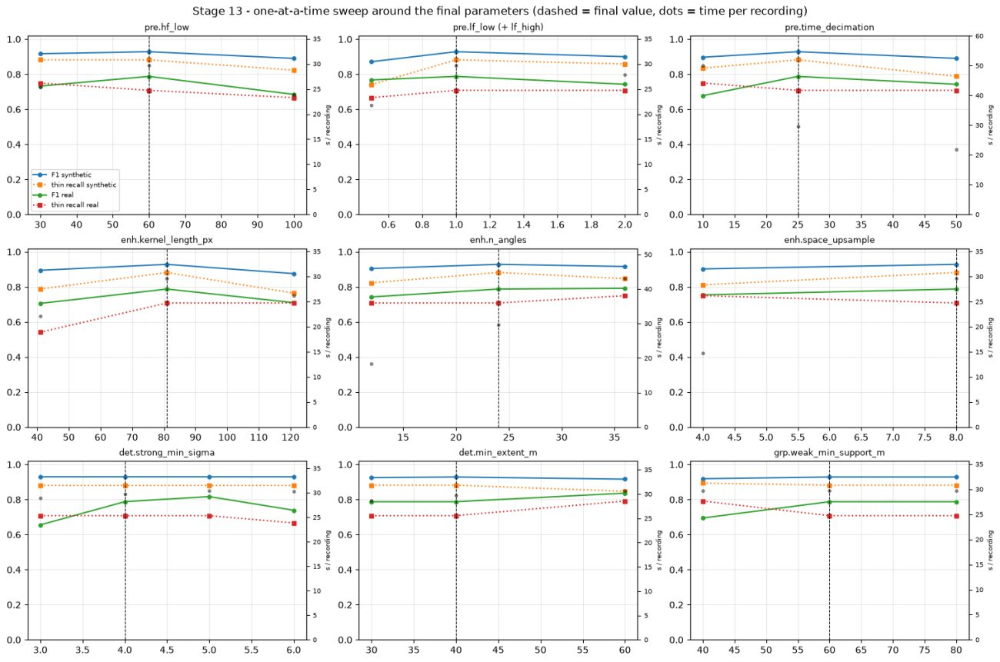

In [79]:
fig("tuning_sweep")

Every swept parameter has its best synthetic F1 at the final value (or a plateau containing it):
band edges (HF lower edge 30 / 60 / 100 Hz: 0.917 / **0.929** / 0.891; LF 0.5-5 / **1-8** / 2-12 Hz:
0.872 / **0.929** / 0.900), decimation 10 / **25** / 50 (0.897 / **0.929** / 0.891), kernel length
41 / **81** / 121 px (0.895 / **0.929** / 0.876), number of angles 12 / **24** / 36 (0.905 /
**0.929** / 0.917), upsampling 4 / **8** (0.903 / **0.929**). Decimation 10 is also 1.7× slower
(note: pixel-unit parameters were not rescaled in this sweep). The strong-threshold floor and
the minimal extent / support do not change the synthetic result (3-6 σ identical) but do change
the real one - see 12.4 "selection".

**Speed / accuracy.** Fewer angles (12) or ×4 upsampling would halve the dominant filter-bank
cost (18 s / 15 s instead of 30 s per recording in the parallel tuning run) at −0.02 to −0.03
synthetic F1; we keep the more accurate setting because the whole pipeline already runs in
≈9-10 s per 2-minute segment on mains power (section 11).

**Sensitivity to the weak-path (hysteresis) thresholds** - grid of low × high and the curve with low = high / 2:

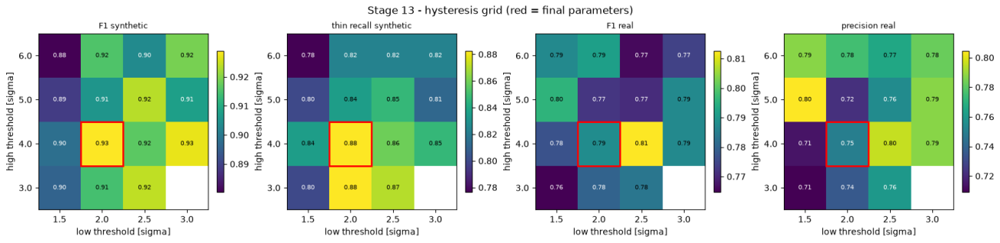

In [80]:
fig("tuning_hysteresis")

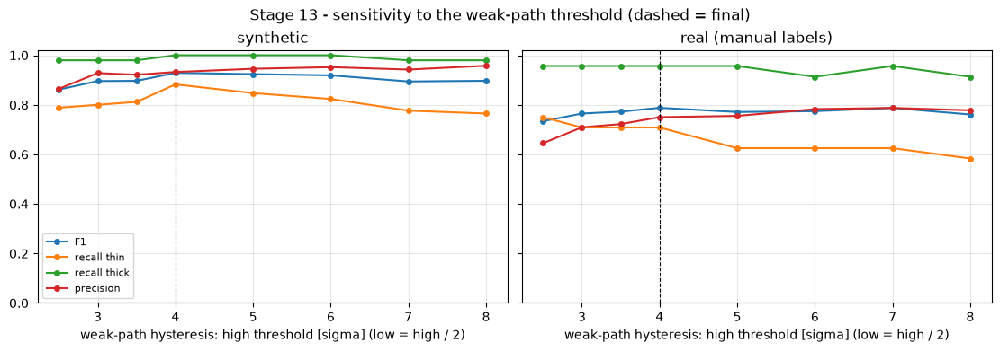

In [81]:
fig("tuning_hysteresis_sensitivity")

The synthetic F1 has a clear maximum at **low / high = 2 / 4 σ** (0.929); lower thresholds add
false positives from the noise texture (1.25 / 2.5 σ: precision 0.865), higher ones lose thin
lines (4 / 8 σ: thin recall 0.77). The real-data F1 is flat (0.73-0.81) over the whole grid, i.e.
the method is not sensitive to the exact thresholds there; the final thresholds lie in the
middle of that plateau.

**Grouping tolerances** (time × velocity) and the combinations of the candidate changes:

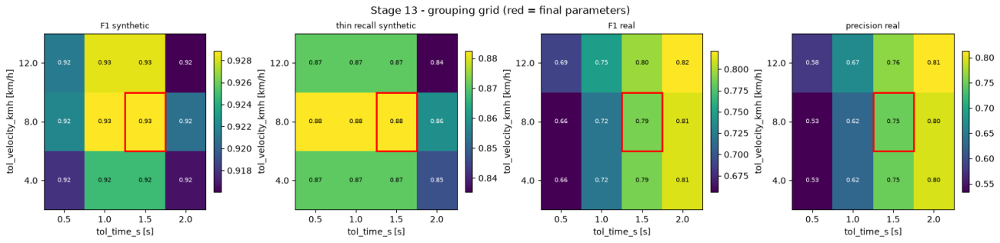

In [82]:
fig("tuning_grouping")

In [83]:
table(read_csv("tuning_combined.csv"), COLS, HEAD)

| variant | syn F1 | syn R thick | syn R thin | syn P | syn \|v\| MAE | real F1 | real R thick | real R thin | real P | real FP near label | s / recording |
|---|---|---|---|---|---|---|---|---|---|---|---|
| final parameters | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.679 |
| tol_time_s = 1.5 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.788 | 0.957 | 0.708 | 0.750 | 10 | 29.698 |
| tol_time_s = 2.0 | 0.921 | 1.000 | 0.859 | 0.931 | 1.837 | 0.812 | 0.957 | 0.708 | 0.796 | 8 | 29.703 |
| strong_min_sigma = 5 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.817 | 0.913 | 0.708 | 0.826 | 6 | 30.394 |
| tol_time_s = 1.5 + strong_min_sigma = 5 | 0.929 | 1.000 | 0.882 | 0.932 | 1.890 | 0.817 | 0.913 | 0.708 | 0.826 | 6 | 30.414 |
| tol_time_s = 2.0 + strong_min_sigma = 5 | 0.921 | 1.000 | 0.859 | 0.931 | 1.837 | 0.854 | 0.913 | 0.708 | 0.905 | 3 | 30.415 |
| tol_time_s = 1.5, tol_velocity_kmh = 12 | 0.928 | 1.000 | 0.871 | 0.939 | 1.900 | 0.796 | 0.957 | 0.708 | 0.765 | 9 | 29.678 |

**Selection of the final parameters.** Grouping is the only place where a change was adopted:
the **time tolerance of the link 1.0 → 1.5 s**. On synthetic data 1.0 s and 1.5 s are identical
(F1 0.929; 0.5 s and 2.0 s are worse), while on real data 1.5 s merges the fragments next to
strong lines: precision 0.625 → 0.750, F1 **0.721 → 0.788**, false positives near a label
19 → 10, thick recall unchanged. This was the open question of Stage 6 (are the extra merges
fragments or close cars?) and the Stage-11 evidence - 19 of 24 real false positives were
fragments on labelled lines - pointed the same way.

Rejected although better on the real labels: a strong-threshold floor of **5 σ** (real F1 0.817,
combined with 1.5 s also 0.817): it loses a real thick line, contradicts the Stage-6 finding that
wide diffuse tram lines (z ≈ 4-6) must reach the strong path, and is supported only by our rough
labels. Likewise 2.0 s (synthetic F1 −0.008) and a minimal extent of 60 m (synthetic −0.012).
Choosing parameters on 47 indicative labels would fit the reference, not the method.

### 12.5 Unsuccessful approaches (what did not work and why)

| Approach | Result | Why it failed / lesson | Log |
|---|---|---|---|
| Canny + Hough on the raw / pre-processed image | synthetic F1 0.59 / 0.04, **0 correct detections on real data** | edges of wide noisy ridges are everywhere; lines must be enhanced (f-k + matched filter) first | Stage 13 |
| One global threshold (strong path only, grade 3/4) | thin recall 0.18 | thin lines are 3-5× weaker than trams - two paths with masking + hysteresis are needed | #24 |
| Single threshold instead of hysteresis | thin recall 0.88 → 0.81 | fragmented thin lines | Stage 13 |
| f-k filter without padding / with a Tukey taper | synthetic F1 0.908 / 0.903, Tukey real 0.661 | wrap-around of the circular FFT at the cable ends; the taper weakens the edge channels | #15, Stage 13 |
| Band choice by d' of band power, by f-k energy in the fan | picked the widest band / 0.2-1 Hz | circular selection, energy weighting | #6, #7 |
| Mean / std normalisation | std overestimates the noise 4× | heavy tails (kurtosis 435) → median / MAD | #3 |
| Hessian ridge filters (Sato, Meijering), Gabor | pixel AUC 0.917-0.949 vs 0.974; object precision ≤ 0.53 | tuned to tubular structures of one width; lose thin noisy lines, 2-3× slower | #16, Stage 13 |
| Strong lines from per-column centroids | touching trams → one wrong line | replaced by ridge + sequential RANSAC | #19 |
| Weak centre line from the response ridge instead of the skeleton | F1 0.929 → 0.874 | ridge pixels of the noise texture give many short segments | #26 |
| Separate RANSAC fit of wide hysteresis components | thin recall +4-8 pp but FP 9 → 45-89 | crossing lines merge into networks | #27 |
| Tracking on the filter-bank response | v(t) MAE 5.33 vs 2.29 km/h | straight kernels straighten curved tracks | #32 |
| Cubic trajectory model | marginally better synthetic, over-follows noise on real data | quadratic = constant acceleration kept | #36 |
| One joint k-means on all features | ARI 0.14 / 0.12 | uninformative features dominate the distances → factorized k-means | #43, #45 |
| v(t) at the end of an ad-hoc window | up to 350 km/h | border peaks of a ridge cut by the window → edge margin (Stage 13) | #53, Stage 13 |

## 13. Conclusions, errors and limitations

**Conclusions.**
* A classical pipeline - energy image with log compression, direction-separated f-k fan
  filter, matched line-filter bank and two detection paths - detects **all thick lines** (1.00
  synthetic, 0.96 real recall) and **most thin lines** (0.88 synthetic, 0.71 real), with one
  averaged line, a velocity and a velocity profile per vehicle. F1 is 0.93 on synthetic and
  0.79 on real data (against indicative manual labels).
* Each step is justified by an ablation: log compression, the f-k filter, the filter bank and the
  weak path (with the LF band) are each worth between 4 and 70 points of F1 or of thin recall; the
  classical Canny + Hough baseline fails completely on real data.
* Velocities agree with the ground truth to 1.9 km/h (3.5 %) on synthetic data and with the drawn
  lines to 4.5 km/h on real data; v(t) reaches 2.3 km/h and separates braking / accelerating
  vehicles from constant ones (85 % agreement).
* The clustering gives interpretable groups by construction (thick / medium / thin × constant /
  varying speed). It matches the vehicle type on synthetic data (purity 0.92) but describes
  loudness rather than type on real data.
* The whole pipeline runs in ≈9-10 s per 2-minute segment (≈12× faster than real time) on a
  15 W laptop CPU, fully vectorised (no per-pixel loops); on battery the CPU is throttled and the
  times vary up to 4×.

**Factual and methodological errors we found (and fixed or bounded).**
* *Circular evaluation* - the first band-selection criteria favoured the band used to select the
  cells (log #6); the first v(t) reference used the same window as the estimate (log #31).
* *Direction of traffic* - the dominant direction was first misread from the waterfall in the
  EDA; the f-k energy (Stage 3) corrected it, and the sign convention is now covered by tests.
* *Acceleration sign* followed the cable axis, not the motion (log #40).
* *Annotation tool* lost clicks and unsaved lines (weak references of matplotlib callbacks,
  closing the window) - fixed with regression tests.
* *Tie-aware AUC* - ranking with arbitrary tie-breaking gave an AUC of 0.02 for a discrete
  feature (log #42).
* *Strong / weak ≠ thick / thin* - the detection path was first read as the vehicle class; on
  real data 13 of 17 matched thin labels come from the strong path.

**Limitations.**
* **No ground truth for real data.** The manual labels are subjective, drawn by one person on the
  raw waterfall; 5 of 52 strokes are not even vehicles in the searched velocity range. Real
  scores are indicative; the method was selected on the synthetic data.
* **Synthetic ≠ real.** The simulator has no hotspot, no noise texture of the quiet direction and
  quieter cars; parameters that are optimal there are not guaranteed to be optimal on real data
  (e.g. the LF band, the strong floor).
* **Vehicles side by side or in a convoy** (gap < ≈1.5 s at the same speed) merge into one line;
  a car behind a tram is masked by the tram's halo (±0.5 s).
* **Crossing lines** of opposite directions are separated by the f-k filter, but at the crossing
  point fragments remain (most real false positives).
* **Cable geometry is unknown.** We assume the fibre runs straight along the road with 5.1 m per
  channel; curves, slack or a varying distance to the lanes bias the velocity (apparent speed
  along the fibre) and v(t).
* **Short cable section (≈266 m).** A vehicle is visible for 6-40 s, so v(t) has only 10-40 points
  and the 46 m window smooths abrupt braking; the LF path is blind for x < 55 m.
* **Velocity range 5-150 km/h** of the fan: a stopping vehicle disappears, faster ones are not
  searched.
* **Sub-lines (axles / bogies)** are not resolved at 0.04 s rows, so the "shape" features carry
  little information.
* **Timings** depend strongly on the laptop's power state (CPU throttling on battery).
* **Borderline clusters.** k-means levels have hard boundaries: in our repeated runs one real
  object close to the thick / medium boundary of `seg_kuba` changed its thickness level between
  two runs of the same code (all detections, velocities and the other clusters were identical),
  so the cluster of an object near a boundary should not be over-interpreted.

## 14. References and sources

The full list - data, libraries with the functions used, literature with the place where each
method is used, and the use of an AI assistant - is kept in `docs/references.md` and displayed
here:

In [84]:
text = (ROOT / "docs" / "references.md").read_text(encoding="utf-8")
display(Markdown(text.split("\n", 1)[1]))          # without the file's own title


For every entry: WHAT was used and WHERE (module / report section).

## Data
- **Real DAS recordings**, fibre-optic cable along Jana Pawła II street, 2024-05-07, 259 files
  of 10 s (`HHMMSS.npy`, 6250 × 52, dt = 0.0016 s, dx = 5.1065 m). Course materials, Google Drive
  link in the project brief. Used for: everything on real data (report sections 1–3, 5–12).
- **Synthetic DAS dataset** (course materials, 6 samples `40`–`45`: signal, ground-truth mask,
  metadata with vehicle type / direction / lane). Used for: development and the quantitative
  evaluation against the ground truth (Stages 5–13, report section 12).
- **Course example notebook** (loading and displaying the data, link in the brief). Used for:
  the waterfall convention (time vertical, space horizontal) and the "velocity label on the
  line" figure style reproduced in `visualization.plot_detections`.
- **Manual labels** of the three real segments (`data/annotations/manual_labels.json`), drawn by
  the authors with `scripts/annotate_real.py`. Indicative reference only (report section 12).

## Libraries (allowed by the brief)
- **NumPy**: `numpy.fft` (`rfft`, `fft2`, per-channel FFT, FFT band-pass, Welch PSD, STFT and f-k
  transform - no SciPy), `lib.stride_tricks.sliding_window_view` (envelopes, STFT frames, v(t)
  windows), `linalg` (batched RANSAC solves, SVD of features), robust statistics. All modules.
- **OpenCV**: `filter2D` (directional matched-filter bank), `resize` (`INTER_LINEAR` spatial
  upsampling, `INTER_AREA` report figures), `HoughLinesP` (weak path), `morphologyEx` / `dilate`
  (oriented opening, strong-line mask), `GaussianBlur`, `getGaborKernel` (Gabor comparison),
  `kmeans` with k-means++ initialisation (clustering), `Canny` (unsuccessful baseline, Stage 13).
- **scikit-image**: `filters.threshold_otsu`, `filters.apply_hysteresis_threshold`,
  `morphology.skeletonize` / `remove_small_objects`, `transform.hough_line` /
  `hough_line_peaks` (global Hough), `measure.label` / `regionprops` / `ransac` / `LineModelND`
  (strong path), `filters.sato` / `meijering` (comparison), `exposure.equalize_adapthist`
  (CLAHE comparison).
- **Matplotlib**: all figures and the annotation GUI (`annotation.py`).
- Pillow is allowed but was not needed.
- Tooling only (not part of the algorithm): uv, pytest, Jupyter / nbconvert.

Library documentation used: numpy.org/doc, docs.opencv.org (4.x), scikit-image.org/docs,
matplotlib.org - function signatures, conventions (e.g. the `hough_line` angle convention, the
`numpy.fft` frequency ordering) and examples of the functions listed above.

## Literature (methods used, and where)
- Hough transform: P. V. C. Hough, *Method and means for recognizing complex patterns*, US Patent
  3 069 654 (1962); R. O. Duda, P. E. Hart, *Use of the Hough transformation to detect lines and
  curves in pictures*, Communications of the ACM 15(1), 1972. → global `hough_line` (Stage 6B).
- Progressive probabilistic Hough (`cv2.HoughLinesP`): J. Matas, C. Galambos, J. Kittler,
  *Robust detection of lines using the progressive probabilistic Hough transform*, Computer
  Vision and Image Understanding 78(1), 2000. → Stage 6B.
- RANSAC: M. A. Fischler, R. C. Bolles, *Random sample consensus*, Communications of the ACM
  24(6), 1981. → sequential RANSAC of strong lines (6A), trajectory RANSAC (Stage 9).
- Otsu threshold: N. Otsu, *A threshold selection method from gray-level histograms*, IEEE
  Trans. Systems, Man, and Cybernetics 9(1), 1979. → strong threshold (6A).
- Hysteresis thresholding / edge detection: J. Canny, *A computational approach to edge
  detection*, IEEE Trans. PAMI 8(6), 1986. → hysteresis of the weak path (6B), Canny baseline.
- Thinning: T. Y. Zhang, C. Y. Suen, *A fast parallel algorithm for thinning digital patterns*,
  Communications of the ACM 27(3), 1984 (algorithm of `skimage.morphology.skeletonize`). → 6B.
- Oriented matched filters for line detection: S. Chaudhuri et al., *Detection of blood vessels
  in retinal images using two-dimensional matched filters*, IEEE Trans. Medical Imaging 8(3),
  1989 - the idea of a bank of rotated line kernels with a Gaussian cross-profile (Stage 5).
- Hessian ridge filters used for comparison: Y. Sato et al., Medical Image Analysis 2(2), 1998
  (`sato`); E. Meijering et al., Cytometry A 58(2), 2004 (`meijering`); A. F. Frangi et al.,
  MICCAI 1998 (background).
- f-k (frequency-wavenumber) fan / velocity filtering: Ö. Yilmaz, *Seismic Data Analysis*,
  Society of Exploration Geophysicists, 2001 (chapter on f-k filtering). → Stage 5.
- Welch PSD: P. D. Welch, IEEE Trans. Audio and Electroacoustics 15(2), 1967. → Stage 3.
- Running moments: B. P. Welford, Technometrics 4(3), 1962; T. F. Chan, G. H. Golub, R. J.
  LeVeque, *Updating formulae and a pairwise algorithm for computing sample variances*, 1979.
  → streaming global statistics (Stage 2).
- k-means++: D. Arthur, S. Vassilvitskii, *k-means++: the advantages of careful seeding*,
  SODA 2007; silhouette: P. J. Rousseeuw, Journal of Computational and Applied Mathematics 20,
  1987; adjusted Rand index: L. Hubert, P. Arabie, Journal of Classification 2, 1985. → Stage 10.
- DAS background: A. H. Hartog, *An Introduction to Distributed Optical Fibre Sensors*, CRC
  Press, 2017; N. J. Lindsey et al., *City-scale dark fiber DAS measurements of infrastructure
  use during the COVID-19 pandemic*, Geophysical Research Letters 47(16), 2020 (vehicles as
  slanted lines in DAS waterfalls, velocity from the slope). → report sections 1 and 13.

## Code and inspiration
- No code was copied from external projects; all algorithms are implemented in `src/das/` on
  top of the libraries above.
- **AI assistant: Claude (Anthropic), used through Claude Code.** Used as a programming
  assistant for: proposing and implementing parts of the code (modules in `src/das/`, scripts,
  tests), refactoring, running the experiments and summarising their results, and drafting the
  documentation and report text. The method choices were discussed and verified by the authors
  on the data (figures, metrics, tests); the authors are responsible for the content.


## Appendix A. Experiments log

Every experiment of the project, successful or not, in the order it was done: what was tried,
the parameters, the data, the result, and the decision (`docs/experiments_log.md`).

In [85]:
text = (ROOT / "docs" / "experiments_log.md").read_text(encoding="utf-8")
display(Markdown(text.split("\n", 1)[1]))


Record EVERY experiment (also unsuccessful ones) - this feeds report section 12.

| # | Date | Stage | What was tried | Parameters | Data | Result (metric / visual) | Kept? | Notes |
|---|------|-------|----------------|------------|------|--------------------------|-------|-------|
| 1 | 08.11 | 2 | Bad-channel detection: robust z of log10 RMS (median of per-file RMS) | z > 3.5 | all 259 files | channel 25 flagged (z = 4.4) | detector kept; channel 25 **not** removed | Smooth RMS/kurtosis bump over channels 22–28 with short horizontal dashes when vehicles pass → physical hotspot (road/track feature), not a sensor fault. Handle with robust normalisation + f-k. |
| 2 | 08.11 | 2 | Display: linear RMS vs log10(RMS / channel median), 0.04 s blocks | clip p99.5 | seg_kuba, seg_mateusz, seg_own | thin car lines barely visible in linear scale; clearly visible in log-normalised scale | log + per-channel normalisation → Stage 4 | Evidence for the grade-5 (thin lines) preprocessing choice. |
| 3 | 08.11 | 2 | Gaussian model of the noise | σ = std vs σ = 1.4826·MAD | all files | std overestimates the noise ≈4× (kurtosis 435) | robust σ used for thresholds | Mean/std normalisation rejected. |
| 4 | 08.11 | 2 | Choice of seg_own by activity ranking | 3× / 10× channel reference, 1 s windows | all 12-file windows not overlapping assigned | 091152–091342 best (active 0.258, 10 episodes) | chosen | Runners-up: 092052, 092552, 093852. |
| 5 | 08.11 | 3 | Tonal-line search (running-median baseline, > 10 dB) on channel-median PSD and on every channel | Welch 2048, all 259 files | all files | no global lines (no 50 Hz); weak local lines on 1–5 channels (1–3, 10.5, 26.5–35.5, 48, 113.5 Hz) | no notch filter | Local lines handled by per-channel normalisation + fan filter. |
| 6 | 08.11 | 3 | Band choice by d' of log band power, vehicle (top 10% RMS) vs background (bottom 30%) 2 s cells | 12 × 14 band grid | 3 segments | best = widest band (8–312 Hz, d' 4.2), almost flat for all wide bands | **rejected** | Cells are selected by broadband RMS → circular, always favours the widest band. |
| 7 | 08.11 | 3 | Band choice by fraction of envelope f-k energy inside the vehicle fan (10–150 km/h) | 16 × 19 band grid, after common-mode removal | 3 segments | flat 0.66–0.68 for HF; LF optimum 0.2–1 Hz, which is visually the worst | **rejected** (kept as secondary panel) | Energy-weighted; penalised by short horizontal streaks that the fan filter removes anyway. |
| 8 | 08.11 | 3 | Band choice by **line SNR** = p99 of robust z of the fan-filtered log envelope | same grid | 3 segments | HF 60–312.5 Hz: 5.84; LF 1–8 Hz: 5.39; broadband 4.88; 0.2–1 Hz: 2.88; 20–80 Hz: 3.85 | **kept** → `hf_*`, `lf_*` in config | Agrees with the visual band comparison. |
| 9 | 08.11 | 3 | Visual band comparison (8 bands, log envelope) | broadband, 0.5–5, 5–20, 20–50, 50–120, 120–300, LF, HF | 3 segments | LF: sharpest thin lines but blind for x < 55 m and some lanes (e.g. +x tram in seg_kuba); HF: clean, all thick + most thin lines; 120–300 Hz dominated by hotspot dashes | **two paths LF + HF** | Changes Stages 4–7 (dual-band processing, merging of candidates). |
| 10 | 08.11 | 3 | f-k fan filter on synthetic stripes | zero padding to 128 | synthetic image | vertical stripe removed 100%; finite horizontal stripe leaks 1.6% energy at cable ends | to improve in Stage 5 | Compare Tukey taper / reflect padding. |
| 11 | 08.11 | 4–5 | **Evaluation method:** pixel AUC vs synthetic GT (light = car/van, heavy = tram/truck; negatives > 1 s / 2 channels from any vehicle) + line SNR on real segments | synthetic 40, 42, 44; seg_kuba/mateusz/own | – | heavy ≈ 1.000 for all sensible variants; light AUC discriminates | AUC = primary metric | Line SNR is not comparable across methods (e.g. no f-k → HF SNR 13.4 inflated by hotspot dashes while AUC drops). |
| 12 | 08.11 | 4 | Envelope: RMS vs mean\|x\| vs plain decimation | 25-sample blocks | as above | light AUC hf/lf/fused: RMS 0.830/0.960/0.962, abs_mean 0.830/0.958/0.961, decimate 0.729/0.957/0.953 | RMS | Envelope is necessary (decimation aliases the oscillating signal). |
| 13 | 08.11 | 4 | Normalisation log_ratio vs robust_z (log1p z+); lower clip on/off | clip p99.5 | as above | robust_z: HF light +0.017, fused +0.001, real SNR lower; no lower clip: LF 0.960 → 0.938 | log_ratio + clip at 0 | |
| 14 | 08.11 | 4 | Common-mode removal / detrend / Gaussian smoothing / CLAHE on-off | σ_t = 2 rows, σ_x = 0.5 ch | as above | no CM: HF light 0.830 → 0.810; detrend: no effect; smoothing: ±0.001; CLAHE: fused +0.003 but real SNR −2 | CM on, detrend on, smoothing off, CLAHE off | |
| 15 | 08.11 | 5 | f-k on/off; padding zero / reflect / tukey | fan 10–150 km/h | as above | no f-k: light 0.790/0.925/0.933; zero 0.838/0.961/0.965 vs reflect 0.830/0.960/0.962; tukey 0.821/0.942/0.943 (heavy 0.990) | f-k on, zero padding | reflect removes leakage of full-width stripes completely (test), but common-mode removal already eliminates them. |
| 16 | 08.11 | 5 | Enhancer: matched line-filter bank vs Sato vs Meijering vs Gabor vs none; white top-hat | 24 angles, σ = 2 px | as above | bank 0.962 fused; none 0.956; Gabor 0.949; Sato 0.948; Meijering 0.917; top-hat 0.957 | filter bank, no top-hat | Hessian filters lose thin lines and are 2–3× slower. |
| 17 | 08.11 | 5 | Kernel length 21/41/61/81/121 px, width σ 1/2/4 px; fan 5–150 / 5–200 / 10–150 | – | as above | L=21 0.954, 41 0.962, 81 0.963 fused; σ: no gain; round 2 combination zero pad + L81 + fan 5–150 → **0.867/0.972/0.974**, L121 equal fused | **final: zero pad, L=81, σ=2, fan 5–150 km/h** | L121 blurs line ends and fits curved tracks worse. Fan from 5 km/h keeps slow (braking) vehicles – a < 10 km/h vehicle in synthetic 40 was removed with 10 km/h. |
| 18 | 09.11 | 6–7 | **Evaluation method (object level):** reference objects from the GT *mask* (per-channel passage time → LSQ line), greedy one-to-one matching: same direction, \|Δt\| at the detection centre < 1.5 s (interpolated GT track), \|Δv\| < 20 km/h | `MATCH_TOL_*` in `run_detection.py` | 6 synthetic samples (85 light, 49 heavy) | GT velocity sign = metadata direction for all 134 vehicles | primary metric for Stages 6–7 | Implemented early from Stage 11 (`gt_objects_from_mask`, `match_detections`, `detection_metrics`, `velocity_errors`). Real data: number of objects + visual check only (annotations in Stage 11). |
| 19 | 09.11 | 6A | Strong path, first version: Otsu → oriented opening → components → per-column centroid → RANSAC, one line per component | – | synthetic | heavy 49/49, but **two trams touching** in the mask → centroid lies between them → only short end fragments survive (FP) | **rejected** | Replaced by ridge (local maxima along time) + sequential RANSAC. |
| 20 | 09.11 | 6A | Ridge + **sequential RANSAC** (up to 4 lines per component); ridge NMS ±5 rows; a 2nd line that does not overlap any accepted line in x (< 50 %) only extends it | – | synthetic + real | one line per component: FP 12; no NMS: FP 11; final: FP 9 | **kept** | Without the "continuation" rule the bent line ends near the cable ends became extra strong FP (FP 24). Physical argument: two vehicles of one direction both cross the cable, so they overlap in x. |
| 21 | 09.11 | 6A | Strong threshold: Otsu floored at 3 / 4 / 6 / 10 σ; fixed 8 σ | – | synthetic + real | synthetic identical for floors 3–10 (F1 0.929); real objects (strong+weak): 3σ 82+3, **4σ 54+10**, 6σ 28+20, 10σ 7+33 | **4 σ** | With 6 σ wide, diffuse lines on real data (z ≈ 4–6, e.g. seg_own 09:12:15–09:12:30) were missed: in 6B their hysteresis region is a broad blob whose skeleton is branched. 6A (opening + ridge + RANSAC) handles them. 3 σ duplicates lines in dense areas. Synthetic data are insensitive (higher SNR). |
| 22 | 09.11 | 6 | `kind` strong/weak vs vehicle type | – | synthetic, matched objects | 13/70 cars come from 6A (direction without trams → threshold at the floor); ridge score cars 16–30 vs trams 15–55, thickness cars 0.25–1.1 s vs trams 0.46–1.5 s | `kind` = detection path only | No single Stage-6 feature separates thick/thin; this is left to clustering (Stage 10). Recall is always reported per GT type. |
| 23 | 09.11 | 6B | Weak path: mask strong (dilated ±0.5 s / ±4 m) → hysteresis 2/4 σ of the background → skeleton → HoughLinesP + global `hough_line` | – | synthetic | light recall: both 0.882, HoughLinesP only 0.765, global only 0.788 (fewest FP: 6) | **both** | The two Hough variants find different lines (fragmented vs short-but-clear). Global-Hough gap 60 vs 20 px: no difference. |
| 24 | 09.11 | 6 | Ablation of the paths | – | synthetic | strong path only (grade 3/4): light **0.176**; no masking of strong objects: light 0.800 (−8 pp); weak HF only 0.412; weak LF only 0.812; no local-orientation check: FP same, real weak +2 | full dual-band weak path + masking | Evidence for the grade-5 requirement: thin lines are found by 6B, mostly in the LF band. |
| 25 | 09.11 | 6B | Hysteresis thresholds 1.5/3, 2/4, 2.5/5, 3/6 σ | – | synthetic + real | F1 0.889 / **0.929** / 0.924 / 0.919; FP 11 / 9 / 7 / 6 | 2 / 4 σ | 3/6 σ has the lowest velocity MAE (2.40) but loses 5 cars. |
| 26 | 09.11 | 6B | Weak centre line = response ridge instead of / in addition to the skeleton | NMS 5–10 rows | synthetic | ridge: F1 0.874 (FP 18), both: 0.866 (FP 27) vs skeleton 0.929 | **rejected** | Ridge pixels of the noise texture create many short Hough segments. |
| 27 | 09.11 | 6B | Separate fit (ridge + sequential RANSAC) of *wide* hysteresis components (mean width > 0.4–1.0 s) | with and without a line-coverage check (≥ 60–80 % of columns) | synthetic + real | light recall 0.88 → 0.92–0.96 but FP 9 → 45–89 | **rejected** | On synthetic data the hysteresis mask merges crossing lines into wide networks → many short false lines. Solved instead by the 4 σ strong floor (#21). |
| 28 | 09.11 | 7 | Grouping: link = same direction AND (same line: \|Δv\| < 8 km/h or 15 %, time gap at the midpoint < max(1 s, thickness/2)) OR (continuation: x gap −20…20 m, time gap at the junction < tol, v ratio ≤ 2); connected components; robust weighted LSQ t(x) per group | – | synthetic + real | no continuation link: FP 17 (vs 9); tol_time 0.5 s: FP 11; 1.5 s: same synthetic, real 44+8 vs 54+10; tol_v 4 km/h/8 %: FP 10; LF weight ×1/×2/×4: MAE 2.93/2.89/2.89 | continuation on, tol 1 s, LF ×2 | tol_time 1.5 s merges 12 more real objects – check against the Stage-11 annotations whether these are fragments or close cars. |
| 29 | 09.11 | 7 | Acceptance rule for weak objects (noise texture of the quiet direction): statistics of weak objects – synthetic TP: support median 229 m, score 8.9; synthetic FP: 43 m, 4.0; **real: 49 m, 4.1, 1 segment** | – | synthetic + real | no rule: FP 14, real weak 48 (most short + faint); support ≥ 60 m only: light 0.812; **support ≥ 60 m OR score ≥ 5 σ**: light 0.882, FP 9 | **long OR clearly above noise** | 80 m/5 σ and 60 m/6 σ give almost the same result. |
| 30 | 09.11 | 6–7 | **Final Stages 6–7** | defaults in `DetectionParams` / `GroupingParams` | 6 synthetic + 3 real | synthetic: **heavy 49/49 (1.000), light 75/85 (0.882)**, precision 0.932, F1 0.929, \|v\| MAE 2.89 km/h; real: seg_kuba 17 objects, seg_mateusz 24, seg_own 23; ≈1 s per segment | – | Missed cars: at the record end (< 5 s visible), very slow / strongly varying speed (≤ 30 km/h, e.g. sample 40 marker 1), one at 110 km/h. Remaining FP: fragments at crossings with strong lines of the opposite direction (f-k separation is imperfect there). |
| 31 | 09.11 | 8–9 | **Evaluation method (velocity, v(t)):** objects matched to the GT as in #18; true mean velocity = LSQ line of the GT track; true v(t) = `velocity_profile` of the GT track with a **3-channel** window (≈ instantaneous); errors on the common time span; speed class of the GT track with the same rule | `REF_WINDOW = 3` in `run_velocity.py` | 6 synthetic samples, 124 matched objects | most synthetic vehicles accelerate / brake (±0.2–1.8 m/s²) – a good reference for v(t) | primary metric for Stages 8–9 | First version used the *same* window for the GT profile → a wider window looked better partly by construction (smooth vs smooth); fixed. |
| 32 | 09.11 | 9 | Map used for tracking: f-k filtered direction map (per channel) vs Stage-5 filter-bank response | sum of HF+LF z maps | synthetic + real | v(t) MAE **2.29** vs 5.33 km/h; GT coverage 0.83 vs 0.76 | **f-k map** | The filter bank integrates along straight 81-px kernels and straightens curved tracks. |
| 33 | 09.11 | 9 | Band of the tracking map: HF+LF sum / HF / LF / auto (LF if the object was detected in LF) | – | synthetic | \|v\| MAE 1.86 / 3.11 / 1.97 / 1.91 km/h; v(t) MAE **2.29** / 3.41 / 4.35 / 2.76; HF only loses 5 tracks | **sum** | LF is blind for x < 55 m, HF lines are wide; the sum keeps a sharp ridge everywhere. |
| 34 | 09.11 | 8 | Reported velocity: Stage-7 line vs LSQ x(t) = v t + b on the track | – | synthetic | \|v\| MAE **2.89 → 1.86 km/h** (light 2.23, heavy 1.29; MAPE ≈ 3 %); all 124 matched objects tracked | **track fit** in the tables, R² reported | Real segments: 62/64 objects tracked, median R² 0.99. |
| 35 | 09.11 | 9 | Sub-row peak: parabola through the argmax vs centroid of the upper half of the peak (±3/6/10 rows) | – | synthetic + real | synthetic v(t) MAE 2.29 vs 2.32–2.72; real profile jitter (median std of successive differences) 2.63 vs 2.78–3.15 km/h | **parabola** | Expected the centroid to help on the flat-topped HF ridges of real trams – it does not. Option kept (`peak_method`). |
| 36 | 09.11 | 9 | Trajectory RANSAC order 1 / 2 / 3 (t(x) polynomial) | 200 trials, residual 0.3 s | synthetic + real | \|v\| MAE 2.33 / 1.86 / 1.73; class agreement 0.77 / 0.85 / 0.86; real "varying" 1 / 30 / 17 | **order 2** | Order 1 cannot follow a bent track (pass 2 searches around a straight line). Cubic is marginally better on synthetic data (constant-acceleration dynamics) but its pass-2 curve over-follows noise on real data; quadratic = constant acceleration, simplest physical model. |
| 37 | 09.11 | 9 | v(t) window 5 / 7 / 9 / 11 / 15 channels (26–77 m) | local LSQ slope | synthetic | v(t) MAE 4.31 / 3.01 / **2.29** / 1.87 / 1.46 km/h | **9 channels (46 m)** | Synthetic dynamics are smooth (≈ constant acceleration), so they always reward smoothing; 15 channels leaves few profile points per object and would hide abrupt braking on real data. Compromise documented. |
| 38 | 09.11 | 9 | Search details: pass-1 window ±1 / ±2 s, pass-2 window ±0.5 / ±0.3 s, min peak z 1.0 / 1.5 / 2.5, time smoothing 0 / 1 / 2 rows | – | synthetic + real | all within ±0.3 km/h of v(t) MAE 2.29; ±2 s: 2.54; min z 2.5 loses 5 tracks | defaults ±1 s / ±0.5 s / 1.5 / 1 row | Robust to these choices. |
| 39 | 09.11 | 9 | Constant / varying rule: \|v_end − v_start\| ≥ 10 / 15 / 20 % of \|v\| AND quadratic RMS gain ≥ 20 / 30 % | – | synthetic | agreement 0.84 / **0.85** / 0.85; RMS gain 20 %: 0.83 | 15 % and 30 % | Errors are mostly GT-varying → "constant" (17/64): conservative, small accelerations near the threshold. Only 1/60 GT-constant called varying. |
| 40 | 09.11 | 9 | Sign of the acceleration | – | – | 2a of x(t) has the sign of the cable axis: braking towards −x gave a > 0 | **along the motion**: 2a·sign(v), + faster, − braking | Interpretable in the report for both directions. |
| 41 | 09.11 | 8–9 | **Final Stages 8–9** | defaults in `TrackingParams` | 6 synthetic + 3 real | synthetic: \|v\| MAE **1.86 km/h**, v(t) MAE **2.29 km/h**, acceleration error (median) **0.07 m/s²**, class agreement **0.85**; real: seg_kuba 17/17 tracked (6 varying), seg_mateusz 22/24 (10), seg_own 23/23 (14), median R² 0.99; tracking ≈ 0.05 s per segment | – | Limitation: near crossings and between two close vehicles the track can jump (e.g. seg_kuba #5, #12: ±20 km/h swings); weak objects have noisier profiles. R² and v_std flag them. |
| 42 | 09.11 | 10 | **Feature separability study** (basis of the feature choice): AUC of every descriptor, heavy vs light and GT varying vs constant speed (synthetic, matched objects), strong vs weak and Stage-9 class (real) | tie-aware AUC (mid-ranks) | 133 synthetic + 64 real objects | heavy/light: HF SNR 0.99, z_hf 0.98, peak z 0.97, area 0.97, score 0.96, FWHM thickness **0.64**, LF/HF ratio 0.33, centroid 0.71, sub-lines 0.47; varying/constant: log dv_rel **0.90**, log \|a\| 0.80, log std v 0.72 | thickness group = (log peak z, log area, HF SNR); speed group = (log dv_rel, log \|a\|, log std v) | A line *looks* thick because it is strong: the measured temporal width (FWHM) separates trams from cars poorly. Sub-lines (bogie fringes) are not resolved at 0.04 s rows – limitation. Tie-broken ranks first gave AUC 0.02 for the discrete sub-line count (fixed). |
| 43 | 09.11 | 10 | First clustering: one k-means on 10 standardised descriptors (thickness, energy, spectrum, sub-lines, \|v\|, speed change), robust (MAD) scaling, k by silhouette | – | synthetic + real | synthetic k = 2, purity heavy/light 0.69, ARI 0.14; real k = 4 with names like "average" | **rejected** | Uninformative features with equal weight dominate the distances; MAD scaling makes a few hard-braking vehicles extreme. |
| 44 | 09.11 | 10 | Speed-change features linear vs log; z-score vs robust MAD scaling; clip ±3 / ±4 | – | synthetic | log features: ARI vs 4 GT classes +0.05–0.1; z-score ≈ MAD for log features; clip without effect | **log features, z-score, clip ±4** | The log of dv, \|a\|, std v is close to symmetric, which suits k-means. |
| 45 | 09.11 | 10 | **Factorized** k-means (one k-means per property: thickness, speed change; cluster = combination of the levels) vs **joint** k-means (k by silhouette / k = 4) | k per property in [2, 3] by silhouette | synthetic (GT) + real | factorized: 4 clusters, ARI vs 4 GT classes **0.45**, purity 0.73, thickness level vs heavy/light purity **0.92** (ARI 0.70), speed level vs GT purity **0.78**; joint k-sil: k = 2 (ARI 0.44, only thick/thin); joint k = 4: 0.48 but cluster names not guaranteed; + velocity, spectrum, shape: 0.12 | **factorized (default)**, joint kept as `--mode joint` | Factorized clusters are by construction the categories of the brief (thick/thin × constant/varying) and robust to adding the 3rd thickness level on real data. Speed change is a continuum on synthetic data (GT threshold 15 %), so its ARI stays moderate. |
| 46 | 09.11 | 10 | Rule baseline: Otsu threshold of the line area × Stage-9 speed class | – | synthetic | ARI vs 4 GT classes 0.53, heavy/light 0.62 | baseline for the report | Comparable to k-means – the speed class of Stage 9 is already a good rule; clustering adds data-driven levels (3 thickness levels on real data). |
| 47 | 09.11 | 10 | **Final Stage 10** | `FeatureParams`, `ClusteringParams` defaults | 6 synthetic + 3 real | synthetic 2×2: thin/const 51, thin/var 23, thick/const 25, thick/var 34 (trams in thick 46/59); real (64 objects) 3×2: thin 4+13, medium 9+22, thick 6+10; thick FWHM ≈1.8–1.9 s vs 1.1–1.3 s, HF SNR 28–30 vs 14 dB; speed level vs Stage-9 class 73 %; real silhouette 0.21 | – | ≈2 min incl. the pipeline for 9 recordings; features ≈0.01 s per object. Agreement with manual thick/thin labels follows after the annotation (Stage 11). |
| 48 | 09.11 | 11 | **Synthetic evaluation** (`evaluate_synthetic.py`): per-class P/R/F1 (class precision by detection path 6A = thick, 6B = thin), reported (track) velocity errors, trajectory IoU (one pixel per channel, ±0.5 s), gate sensitivity | gates 1.5 s / 20 km/h | 6 synthetic samples, 134 vehicles | thick R **1.000** (49/49) P 0.940 F1 **0.969**; thin R **0.882** (75/85) P 0.924 F1 **0.903**; all P 0.932 R 0.925 F1 0.929; \|v\| MAE 1.86 km/h (thick 1.29, thin 2.23), MAPE 3.5 %; IoU 0.63; 15/75 matched cars from the strong path; gates ≥ 1.5 s / 20 km/h stable, 10 km/h: thick R 0.88 | – | IoU < 1 mostly because GT tracks span the whole cable while detections cover the detected extent (± tracking extension). The 10 km/h drop: matching uses the Stage-7 line velocity, which for long bent tram tracks differs > 10 km/h from the GT mean. |
| 49 | 09.11 | 11 | Real data: annotation tool (`annotate_real.py`, matplotlib GUI on the raw log-RMS waterfall, polylines + thick/thin label in physical units) and `evaluate_real.py` | – | 3 real segments | smoke test of the evaluation flow with labels made from the detections: F1 1.00 (outputs removed afterwards) | **labels pending** (manual annotation by the authors) | Reference must be independent of the detector, therefore the raw waterfall (and Stage-4 band images) only. Subjective reference – limitation to state in the report. |
| 50 | 11.11 | 11 | Annotation tool in practice + **manual labels** of the 3 real segments | autosave after every finished / undone / deleted line and on window close | `seg_kuba` 15, `seg_mateusz` 18, `seg_own` 19 lines (Kuba) | 1st run: clicks ignored – the unassigned `Annotator` was garbage-collected (matplotlib keeps weak references to callbacks); closing with X did not save | fixed (figure holds the tool; autosave; 2 regression tests) | Labels are indicative only: rough clicks on a noisy waterfall. 5 strokes are not vehicles in the detector fan (4 near-horizontal, 187–3147 km/h; 1 of 13 m) and are listed but not scored (`split_references`, 5–150 km/h, ≥ 30 m). |
| 51 | 11.11 | 11 | **Real-data evaluation** (`evaluate_real.py`) vs the 47 scored labels; FP split near a label / no label (`false_positive_kinds`, 1 s on ≥ 3 channels); gate sensitivity | gates 1.5 s / 20 km/h (unchanged) | 3 real segments, 64 detections | thick R **0.957** (22/23) P 0.63; thin R 0.75 (18/24) P 0.60; all P 0.625 R **0.851** F1 **0.721** (all 52 labels: F1 0.690); per segment F1 0.67 / 0.72 / 0.76; \|v\| diff 4.05 km/h (thick 2.97, thin 5.37), MAPE 6.6 %; IoU 0.38; FP 24 = **19 near a label** + 5 no label; P/R/F1 identical for gates 1.0 s / 15 km/h … 4.0 s / 40 km/h | – (detector not tuned on the labels) | Precision is lowered by fragments / duplicates of strong lines (X-shaped pieces next to trams); without them P = 40/45 = 0.89, which is the input for Stage 13. The 7 missed labels are weak, isolated thin lines (≥ 4.9 s from any matched label, 2 at the segment edge), so tol_time 1.5 s (Stage 6 open point) does not merge close cars. The detection path is a poor thick/thin class on real data: 14 of 18 matched thin labels come from the strong path. |
| 52 | 11.11 | 10/11 | Clusters and features vs the manual thick/thin labels (`run_clustering.py`, 40 matched objects) | – | real | AUC manual thick vs thin: z_hf 0.84, log peak z 0.83, FWHM 0.78, log area 0.63, **HF SNR 0.54** (synthetic 0.99); factorized thickness level vs labels ARI −0.01 (thick level 7 thick / 2 thin, medium 10 / 10, thin 5 / 6); joint variants ARI ≤ 0.19 | no change (limitation) | The thickness group was chosen on synthetic data, where HF SNR is the best feature. On real data cars are as loud in HF as trams (median ≈ 27 dB for both), so the k-means thickness level follows the loudness, not the manual thickness. Not re-tuned on 40 indicative labels (it would fit the reference itself). Peak z / z_hf / FWHM are the candidates. |
| 53 | 11.11 | 12 | **End-to-end run** `run_pipeline.py` (Stages 4 → 10 + clustering over the run), stage timings | `PipelineParams` defaults | 3 segments; 6 synthetic; window `--start 092002` | segments: 17 / 24 / 23 objects (strong v>0/v<0: 3/11, 5/17, 3/15; weak: 2/1, 0/2, 0/5); clusters identical to Stage 10 (real 4/13/9/22/6/10, synthetic 51/23/25/34); synthetic F1 0.90–0.97 per sample; time per 2-min recording **7.7–9.0 s** (CPU not throttled; enhance 5–6 s = 70 %), 12.9–38.7 s on battery (throttled) | – | Laptop i5-1235U on battery: the same 24-kernel filter-bank benchmark slows from 0.9 s to 3–4.9 s after a few seconds of load, so timings vary 4× between runs; report the unthrottled numbers and state the hardware. The Stage-5 filter bank dominates; fewer angles / smaller upsampling are a Stage-13 ablation (they change the results). v(t) of an object cut by the end of an ad-hoc window reaches 217 km/h (no padding there) – Stage 13. |
| 54 | 12.11 | 13 | **Evaluation method of Stage 13** (`tune_parameters.py`): every variant = final parameters with a few fields changed, Stages 4 → 9 on 6 synthetic + 3 labelled real recordings, object-level Stage-11 scores; parallel per recording, Stage 4-6 results cached per upstream parameters (`run_pipeline(pre=, enhanced=, detections=)`) | 83 variants (78 distinct), ≈16 min (9 processes) | 6 synthetic + 3 real | – | **selection rule:** synthetic F1 decides; real F1 only breaks ties of synthetic-equivalent settings (\|ΔF1\| < 0.005) and vetoes changes that only fit the simulator | The labels are indicative (Stage 11), so they must not drive the choice. |
| 55 | 12.11 | 4–9 | **Ablation at the detection level** (final parameters, one step off) | – | as #54 | synthetic F1 / thin recall: final 0.929 / 0.882; no log compression 0.817 / 0.647 (real F1 0.504); no f-k 0.893 / 0.800 (real 0.557, real thin 0.333); no filter bank 0.859 / 0.765; no masking 0.899 / 0.800; no hysteresis 0.903 / 0.812; no common mode 0.900 / 0.812; weak path HF only 0.740 / 0.412 (real 0.809); strong path only 0.621 / 0.176; no ridge tracking: same detections, \|v\| MAE 2.89 vs 1.89 | every step kept | The LF band of the weak path adds a few real false positives (real F1 0.809 without it) but finds half of the synthetic cars – kept. |
| 56 | 12.11 | 4–6 | **Method comparison** at the object level + classical baselines (Canny with median-based thresholds + HoughLinesP, same Hough settings and velocity fan, no tracking) | – | as #54 | synthetic / real F1: HoughLinesP only 0.887 / 0.768, global Hough only 0.902 / 0.809, Sato 0.663 / 0.337, Meijering 0.580 / 0.217, Gabor 0.476 / 0.257, mean\|x\| 0.893 / 0.755, decimation 0.874 / 0.740, robust z 0.935 / 0.772 (thick R 0.959), reflect 0.914 / 0.760, Tukey 0.903 / 0.661, no padding 0.908 / 0.742, fixed 6 σ 0.906 / 0.739; **Canny + Hough raw 0.591 / 0 correct**, on the HF image 0.040 / 0.171 | final methods kept; robust z rejected (loses 2 trams, worse real) | Unsuccessful approaches of the plan confirmed with numbers: Canny + Hough (edges of noisy wide ridges everywhere), single threshold, f-k without padding. Hessian / Gabor thresholds in σ were set for the bank, but their pixel AUC was already lower (#16). |
| 57 | 12.11 | 3–7 | **One-at-a-time sweep**: hf_low 30/100, LF band 0.5–5 / 2–12, decimation 10/50, kernel 41/121, angles 12/36, upsampling 4, strong floor 3/5/6 σ, min extent 30/60 m, weak support 40/80 m | pixel-unit parameters not rescaled with the decimation | as #54 | synthetic F1 is maximal at every final value (0.929); e.g. kernel 41/121: 0.895/0.876, angles 12/36: 0.905/0.917, upsample 4: 0.903; decimation 10 is 1.7× slower; strong floor 3–6 σ and support 80 m: synthetic identical, real 0.656 / **0.817** (5 σ) / 0.739; min extent 60 m: synthetic 0.917, real 0.837 | defaults kept | Speed option documented: 12 angles or ×4 upsampling halve the filter-bank cost at −0.02…−0.03 synthetic F1. |
| 58 | 12.11 | 6B | **Hysteresis grid** low 1.5–3 × high 3–6 σ + sensitivity curve low = high/2 (2.5–8 σ) | – | as #54 | synthetic F1 maximal at 2 / 4 σ (0.929); 1.25/2.5: P 0.865; 4/8: thin R 0.765; real F1 flat 0.73–0.81 | 2 / 4 σ kept | Real data are insensitive to the thresholds in a wide range. |
| 59 | 12.11 | 7 | **Grouping grid** tol_time 0.5–2 s × tol_v 4–12 km/h, then combinations with the strong floor | – | as #54 | synthetic F1 1.0 s = 1.5 s = 0.929 (0.5 s 0.922, 2.0 s 0.921); real F1 0.721 → **0.788** with 1.5 s (P 0.625 → 0.750, FP near a label 19 → 10, thick R unchanged, one thin label of seg_mateusz merged with a neighbour); 1.5 s + 5 σ: real 0.817 (thick R 0.913) | **tol_time_s = 1.5 s** (new default) ; 5 σ floor rejected | Tie-break rule of #54: synthetic-equivalent, real better, consistent with the Stage-6 open point and the Stage-11 fragment analysis. The 5 σ floor loses a real thick line, contradicts #21 and rests on the rough labels only. All Stage 6–12 results regenerated. |
| 60 | 12.11 | 9 | **Edge margin in tracking**: peaks within `edge_margin_s` = 0.5 s of the first / last image row dropped (both passes) | 0 / 0.5 s | window 09:20:02, synthetic | the vehicle cut by the window end (#53): v(t) up to 351 km/h → plausible; synthetic detections unchanged, \|v\| MAE 1.86 → 1.89 km/h | kept (regression test) | A ridge whose centre lies beyond the image has its noisy flank maximum a few rows before the border → compressed passage times. |
| 61 | 12.11 | 14 | Report figures: downscaled with `cv2.INTER_AREA` to ≤ 1300 px, JPEG (q 82) for files > 150 kB; block diagram drawn with matplotlib | – | 67 figures | 8.9 MB of figures (first version 1500 px / PNG up to 350 kB: 11.3 MB, HTML of sections 1–11 alone 14.6 MB) | kept | HTML must stay < ≈20 MB together with the full source code. |
| 62 | 12.11 | 15 | **Quality control**: clean copy (uv and pip), code review (5 unused functions removed, slope tolerance moved to `DetectionParams.slope_margin`), repeated runs of the pipeline | – | 3 segments, clean environment | object tables byte-identical to the repository; 162 tests pass. One real object (`seg_kuba` #3) at the thick / medium boundary of the factorized k-means changed its thickness level between two runs of identical code; detections, velocities and the other clusters identical, current code reproducible | kept; limitation in report section 13 | k-means levels have hard boundaries, so the cluster of a borderline object should not be over-interpreted. |


## Appendix B. Source code

The complete source code: the library `src/das/` (one module per processing stage), the
command-line scripts `scripts/` and the configuration. Tests are in `tests/` (run with
`uv run pytest`, warnings are errors).

In [86]:
files = sorted((ROOT / "src" / "das").glob("*.py")) + sorted((ROOT / "scripts").glob("*.py"))
n_lines = sum(len(p.read_text(encoding="utf-8").splitlines()) for p in files)
print(f"{len(files)} files, {n_lines} lines")
for p in files:
    display(Markdown(f"#### `{p.relative_to(ROOT).as_posix()}`"))
    display(Code(p.read_text(encoding="utf-8"), language="python"))

30 files, 9566 lines


#### `src/das/__init__.py`

"""DAS moving-object detection package (see plan.md for the stage-by-stage plan)."""

#### `src/das/annotation.py`

"""Manual labels of the real segments (plan: Stage 11) - storage, session state, GUI.

The real recordings have no ground truth, so the visible lines are marked by hand on the
raw energy waterfall (log RMS, the image of the brief - *not* the detector output, to
keep the reference independent of the algorithm). A line is a polyline of >= 2 clicks
in physical units (x [m] along the cable, t [s] from the segment start) with the label
"thick" (tram / truck) or "thin" (car). Labels live in
``data/annotations/manual_labels.json`` (versioned)::

    {"segments": {"seg_kuba": {"start": "090452", "annotator": "...", "saved": "...",
                               "lines": [{"id": 1, "kind": "thin",
                                          "points": [[x, t], ...]}, ...]}}}

``Annotator`` is the matplotlib tool used by ``scripts/annotate_real.py``; the logic is
in ``AnnotationSession`` so it can be tested without a display.
"""
from __future__ import annotations

import json
from datetime import datetime
from pathlib import Path

import numpy as np

from . import config

LABEL_KINDS = ("thick", "thin")
KIND_STYLE = {"thick": dict(color="red", lw=1.6, ls="-"),
              "thin": dict(color="cyan", lw=1.1, ls="--")}

HELP = """Annotation keys (mouse over the image):
  left click      add a point of the current line (>= 2 points, along the line)
  right click     remove the last point
  t / n           finish the current line as THICK (tram, truck) / THIN (car)
  u               undo: last point, or the last finished line
  d               delete the finished line nearest to the mouse
  up / down       move the view by half a window (pageup / pagedown: a whole window)
  a               toggle: whole segment / window view
  b               next background image (raw RMS -> HF band -> LF band)
  s               save           q  save and quit           h  this help
Labels are saved automatically after every finished / undone / deleted line and when
the window is closed; an unfinished line (no t / n yet) is not saved.
Use the toolbar zoom / pan freely - clicks are ignored while a toolbar mode is active."""


# ======================================================================================
# Storage
# ======================================================================================
def load_labels(path: Path | str | None = None) -> dict:
    """The labels file (an empty structure if it does not exist yet)."""
    path = Path(path or config.ANNOT_FILE)
    if not path.exists():
        return {"segments": {}}
    data = json.loads(path.read_text(encoding="utf-8"))
    data.setdefault("segments", {})
    return data


def save_labels(data: dict, path: Path | str | None = None) -> Path:
    path = Path(path or config.ANNOT_FILE)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=1), encoding="utf-8")
    return path


def segment_lines(data: dict, name: str) -> list[dict]:
    """Labelled lines of one segment ([] if not annotated)."""
    return list(data.get("segments", {}).get(name, {}).get("lines", []))


# ======================================================================================
# Session state (no GUI)
# ======================================================================================
class AnnotationSession:
    """Lines finished so far + the points of the line being drawn."""

    def __init__(self, lines: list[dict] | None = None):
        self.lines: list[dict] = [dict(ln) for ln in (lines or [])]
        self.current: list[list[float]] = []

    def _next_id(self) -> int:
        return max((int(ln.get("id", 0)) for ln in self.lines), default=0) + 1

    def add_point(self, x: float, t: float) -> None:
        self.current.append([float(x), float(t)])

    def remove_point(self) -> bool:
        if self.current:
            self.current.pop()
            return True
        return False

    def finish(self, kind: str) -> dict | None:
        """Close the curren

#### `src/das/clustering.py`

... (51 outputs left out)

#### `scripts/run_velocity.py`

"""Stages 8-9: velocity of every object and velocity over time (v(t), extra point 1).

Runs the pipeline (Stages 4-9, ``das.pipeline.run_pipeline``) and

1. synthetic samples: matches the objects with the ground truth and compares
   - the line velocity (Stage 7) and the track velocity (Stage 8, LSQ x(t) on the
     ridge track) with the true mean velocity, per vehicle class;
   - the velocity profile v(t) with the GT profile, the acceleration of the quadratic
     fit and the constant / varying speed label;
2. real segments: figures (velocities as in the brief, curved tracks, combined v(t),
   per-object v(t) gallery) and the object table with R^2 and acceleration;
3. variant study of the tracking options (energy map, band, window, ...), re-tracking the
   same objects.

Outputs: ``outputs/figures/velocity/``, ``outputs/results/velocity_*.csv`` and
``outputs/results/velocity_summary.json``.

Plan: Stages 8 and 9.
"""
from __future__ import annotations

import argparse
import csv
import json
import time
from collections import Counter
from dataclasses import asdict, replace

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from das import config  # noqa: E402
from das import io as dio  # noqa: E402
from das.config import PipelineParams, TrackingParams  # noqa: E402
from das.evaluation import (HEAVY_TYPES, LIGHT_TYPES, gt_objects_from_mask,  # noqa: E402
                            match_detections, profile_errors)
from das.pipeline import retrack, run_pipeline, run_segment  # noqa: E402
from das.tracking import velocity_profile  # noqa: E402
from das.velocity import write_objects_csv  # noqa: E402
from das.visualization import (plot_detections, plot_profile_gallery,  # noqa: E402
                               plot_velocity_profiles, save_figure)

FIG_DIR = config.FIG_DIR / "velocity"
MATCH_TOL_T_S, MATCH_TOL_V_KMH = 1.5, 20.0     # same matching as Stages 6-7
REF_WINDOW = 3                                 # GT v(t): 3-channel window (~instantaneous)

# (group, name, tracking overrides) - relative to the defaults
VARIANTS = [
    ("baseline", "default", {}),
    ("map", "track on the filter-bank response", {"track_map": "response"}),
    ("map", "band HF only", {"track_band": "hf"}),
    ("map", "band LF only", {"track_band": "lf"}),
    ("map", "band auto (LF if detected in LF)", {"track_band": "auto"}),
    ("map", "no time smoothing", {"smooth_rows": 0.0}),
    ("map", "time smoothing 2 rows", {"smooth_rows": 2.0}),
    ("search", "peak: centroid of the upper half", {"peak_method": "centroid"}),
    ("search", "pass-1 window +-2 s", {"search_halfwidth_s": 2.0}),
    ("search", "pass-2 window +-0.3 s", {"refine_halfwidth_s": 0.3}),
    ("search", "min peak z 1.0", {"min_peak_z": 1.0}),
    ("search", "min peak z 2.5", {"min_peak_z": 2.5}),
    ("search", "RANSAC line (order 1)", {"poly_order": 1}),
    ("search", "RANSAC cubic (order 3)", {"poly_order": 3}),
    ("profile", "window 5 channels", {"velocity_window_channels": 5}),
    ("profile", "window 7 channels", {"velocity_window_channels": 7}),
    ("profile", "window 11 channels", {"velocity_window_channels": 11}),
    ("profile", "window 15 channels", {"velocity_window_channels": 15}),
    ("class", "varying: dv 10 %", {"varying_dv_rel": 0.10}),
    ("class", "varying: dv 20 %", {"varying_dv_rel": 0.20}),
    ("class", "varying: RMS gain 20 %", {"varying_rms_gain": 0.2}),
]


def parse_args() -> argparse.Namespace:
    p = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--segment", default="all", help="segment name from config.SEGMENTS or 'all'")
    p.add_argument("--synthetic", default="all", help="comma-separated synthetic ids or 'all'")
    p.add_argument("--skip-variants", action="store_true", help="no variant study")
    p.add_argument("--dpi", type=int, default=100)
    return p.parse_args(

#### `scripts/tune_parameters.py`

"""Stage 13: parameter studies, ablation and method comparison at the detection level.

Every variant = the final parameters (``config.PipelineParams``) with a few fields
changed. It runs Stages 4 -> 9 on all recordings and is scored at the *object* level
with the Stage-11 evaluation:

- synthetic samples: one-to-one matching with the ground truth (P / R / F1, recall of
  thick = tram / truck and thin = car / van lines, |v| MAE);
- real segments: the same against the manual labels (indicative reference, only the
  scored labels, see ``evaluation.split_references``), plus the false positives split
  into "near a label" / "no label".

Studies (``--study``, several allowed, default all):

- ``ablation``: switch off one step at a time (common-mode removal, log compression,
  f-k filter, filter bank, masking of strong lines, hysteresis, LF band, weak path,
  ridge tracking, edge margin);
- ``methods``: alternatives of single steps (Hough variants, Sato / Meijering / Gabor,
  envelope, normalisation, f-k padding, strong threshold) and two classical baselines
  (Canny + HoughLinesP on the raw / preprocessed image);
- ``sweep``: one-at-a-time grid around the defaults (band edges, decimation, kernel
  length, number of angles, upsampling, strong floor, minimal extent / support);
- ``hysteresis``: grid of the weak-path thresholds (low x high) + the sensitivity curve
  F1(threshold) with low = high / 2;
- ``grouping``: grid of the grouping tolerances (time x velocity);
- ``combined``: combinations of the candidate changes found by the other studies.

Speed: the recordings are processed in parallel (``--jobs``); inside a worker the
results of Stages 4 / 5 / 6 are cached and reused by all variants with the same
upstream parameters (``run_pipeline(pre=, enhanced=, detections=)``), so e.g. a
grouping grid costs only grouping + tracking. Timings of reused stages are taken from
the run that computed them.

The detector is selected on the *synthetic* F1 (true ground truth); the real-data
scores (rough manual labels) are a guard against changes that only fit the simulator.
We do not tune for individual lines.

Outputs: ``outputs/results/tuning_<study>.csv``, ``tuning.json``,
``outputs/figures/tuning/<study>*.png``.

Usage::

    uv run python scripts/tune_parameters.py                    # all studies (~0.5-1 h)
    uv run python scripts/tune_parameters.py --study ablation methods --jobs 4
    uv run python scripts/tune_parameters.py --quick            # 2 synthetic + 1 real

Plan: Stage 13.
"""
from __future__ import annotations

import argparse
import copy
import csv
import json
import os
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from dataclasses import asdict, dataclass

import cv2
import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from das import config  # noqa: E402
from das import io as dio  # noqa: E402
from das.annotation import load_labels, segment_lines  # noqa: E402
from das.config import PipelineParams  # noqa: E402
from das.detection import (Detections, LineSegment, detect_candidates,  # noqa: E402
                           sample_image, slope_bounds, slope_ok)
from das.enhancement import enhance, robust_z  # noqa: E402
from das.evaluation import (evaluate_objects, gt_objects_from_mask,  # noqa: E402
                            references_from_annotations, split_references,
                            summarize_evaluations)
from das.pipeline import run_pipeline  # noqa: E402
from das.preprocessing import preprocess, upsample_space  # noqa: E402
from das.visualization import save_figure  # noqa: E402

FIG_DIR = config.FIG_DIR / "tuning"
STUDIES = ("ablation", "methods", "sweep", "hysteresis", "grouping", "combined")
NO_TRACK = (("trk.min_points", 10 ** 6),)          # velocity of the averaged Stage-7 line
FIELDS = ["study", "variant", "changes", "syn_precision", "syn_recall", "syn_f1",
          "syn_recall_thick", "syn_recall_t